<a href="https://colab.research.google.com/github/vrncn01/SKRIPSI-XGBOOST/blob/main/XGBoost_Histogram_ver_SKRIPSI_KETIGA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Manual XGBoost — Optimized Histogram Binning (Detailed Output)

Notebook eksperimen manual XGBoost yang menggunakan **precomputed histogram bins** dan output sangat detail per boosting iteration.

**Sumber path dan parameter** mengikuti notebook `SKRIPSI_KETIGA(1).ipynb`:
- `BASE_DIR = /content/drive/MyDrive/SKRIPSI/FMC_2_8_MODELING`
- `X_train.npz`, `X_valid.npz`, `X_test.npz`
- `y_train.csv`, `y_valid.csv`, `y_test.csv`
- `feature_names_after_encoding.csv`
- learning rate 0.05, max depth 6, min child weight 1, subsample 0.80, colsample_bytree 0.80, lambda 1, alpha 0, gamma 0, seed 42, n_estimators 200.

> **Catatan:** notebook ini tidak melakukan split ulang. Test set hanya dipakai sekali pada evaluasi final.


In [ ]:
import os

print(os.path.exists("/content/drive"))
print(os.path.exists("/content/drive/MyDrive"))
print(os.path.exists("/content/drive/MyDrive/SKRIPSI"))
print(os.path.exists("/content/drive/MyDrive/SKRIPSI/FMC_2_8_MODELING"))

True
True
True
False


In [ ]:
import pickle

CKPT = "/content/drive/MyDrive/SKRIPSI/FMC_XGBOOST_HISTOGRAM_DETAILED/checkpoints/best_state.pkl"

with open(CKPT, "rb") as f:
    state = pickle.load(f)

print(type(state))

if isinstance(state, dict):
    print("\nKEYS:")
    for k, v in state.items():
        print(k, "->", type(v), end="")
        try:
            print(" |", v if not hasattr(v, "__len__") or isinstance(v, (str, int, float)) else f"len={len(v)}")
        except:
            print()
else:
    print(state)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/SKRIPSI/FMC_XGBOOST_HISTOGRAM_DETAILED/checkpoints/best_state.pkl'

In [1]:
# ============================================================
# 0. SETUP
# ============================================================
import os, time, json, math, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Google Drive mount dilewati (bukan environment Colab).")

BASE_DIR = "/content/drive/MyDrive/SKRIPSI/FMC_2_8_MODELING"

X_TRAIN_PATH = os.path.join(BASE_DIR, "X_train.npz")
X_VALID_PATH = os.path.join(BASE_DIR, "X_valid.npz")
X_TEST_PATH  = os.path.join(BASE_DIR, "X_test.npz")

Y_TRAIN_PATH = os.path.join(BASE_DIR, "y_train.csv")
Y_VALID_PATH = os.path.join(BASE_DIR, "y_valid.csv")
Y_TEST_PATH  = os.path.join(BASE_DIR, "y_test.csv")

FEATURE_NAMES_PATH = os.path.join(BASE_DIR, "feature_names_after_encoding.csv")

OUTPUT_DIR = "/content/drive/MyDrive/SKRIPSI/FMC_XGBOOST_HISTOGRAM_DETAILED"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "logs"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "checkpoints"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "plots"), exist_ok=True)

# Parameter mengikuti notebook skripsi
params = {
    "objective": "binary:logistic",
    "learning_rate": 0.05,
    "max_depth": 6,
    "min_child_weight": 1.0,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "reg_lambda": 1.0,
    "reg_alpha": 0.0,
    "gamma": 0.0,
    "n_estimators": 200,
    "random_seed": 42,
}

MAX_BIN = 32
EARLY_STOPPING_ROUNDS = 20

# Level output:
# 0 = hanya summary
# 1 = detail iteration
# 2 = detail node + best split
# 3 = detail histogram best feature pada setiap node
VERBOSE_LEVEL = 2
SHOW_HISTOGRAM_BINS = True

np.random.seed(params["random_seed"])

print("SETUP SELESAI")
print("BASE_DIR :", BASE_DIR)
print("OUTPUT   :", OUTPUT_DIR)


Mounted at /content/drive
SETUP SELESAI
BASE_DIR : /content/drive/MyDrive/SKRIPSI/FMC_2_8_MODELING
OUTPUT   : /content/drive/MyDrive/SKRIPSI/FMC_XGBOOST_HISTOGRAM_DETAILED


In [2]:
# ============================================================
# 1. LOAD SPARSE DATA — TANPA SPLIT ULANG
# ============================================================
def load_y(path):
    df = pd.read_csv(path)
    # dukung CSV satu kolom maupun kolom bernama target/y
    if df.shape[1] == 1:
        return df.iloc[:, 0].to_numpy(dtype=np.float64)
    for c in ["y", "target", "label", "STUCK"]:
        if c in df.columns:
            return df[c].to_numpy(dtype=np.float64)
    return df.iloc[:, 0].to_numpy(dtype=np.float64)

t0 = time.perf_counter()
X_train = sp.load_npz(X_TRAIN_PATH).tocsr()
X_valid = sp.load_npz(X_VALID_PATH).tocsr()
X_test  = sp.load_npz(X_TEST_PATH).tocsr()

y_train = load_y(Y_TRAIN_PATH)
y_valid = load_y(Y_VALID_PATH)
y_test  = load_y(Y_TEST_PATH)

feature_names = pd.read_csv(FEATURE_NAMES_PATH).iloc[:, 0].astype(str).tolist()
if len(feature_names) != X_train.shape[1]:
    feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]

print("="*80)
print("DATA LOADED")
print("="*80)
print(f"Train : {X_train.shape} | positive={int(y_train.sum()):,} | rate={y_train.mean():.6f}")
print(f"Valid : {X_valid.shape} | positive={int(y_valid.sum()):,} | rate={y_valid.mean():.6f}")
print(f"Test  : {X_test.shape} | positive={int(y_test.sum()):,} | rate={y_test.mean():.6f}")
print(f"Features: {len(feature_names)}")
print(f"Load time: {time.perf_counter()-t0:.3f} sec")


DATA LOADED
Train : (258777, 651) | positive=248,607 | rate=0.960700
Valid : (32347, 651) | positive=31,076 | rate=0.960707
Test  : (32348, 651) | positive=31,077 | rate=0.960709
Features: 651
Load time: 2.698 sec


In [3]:
# ============================================================
# 2. BASIC MATH / METRICS
# ============================================================
def sigmoid(x):
    x = np.clip(x, -40, 40)
    return 1.0 / (1.0 + np.exp(-x))

def logloss(y, p):
    p = np.clip(p, 1e-15, 1-1e-15)
    return float(-np.mean(y*np.log(p) + (1-y)*np.log(1-p)))

def classification_metrics(y, p, threshold=0.5):
    pred = (p >= threshold).astype(np.int8)
    tp = int(np.sum((y==1) & (pred==1)))
    tn = int(np.sum((y==0) & (pred==0)))
    fp = int(np.sum((y==0) & (pred==1)))
    fn = int(np.sum((y==1) & (pred==0)))
    accuracy = (tp+tn) / max(1, len(y))
    precision = tp / max(1, tp+fp)
    recall = tp / max(1, tp+fn)
    f1 = 2*precision*recall/max(1e-15, precision+recall)
    return {
        "accuracy": accuracy, "precision": precision, "recall": recall,
        "f1": f1, "tp": tp, "tn": tn, "fp": fp, "fn": fn
    }

def auc_roc(y, p):
    order = np.argsort(-p)
    yy = y[order]
    pos = yy.sum()
    neg = len(yy)-pos
    if pos == 0 or neg == 0: return np.nan
    tps = np.cumsum(yy)
    fps = np.cumsum(1-yy)
    tpr = np.r_[0, tps/pos, 1]
    fpr = np.r_[0, fps/neg, 1]
    return float(np.trapezoid(tpr, fpr))

def auc_pr(y, p):
    order = np.argsort(-p)
    yy = y[order]
    pos = yy.sum()
    if pos == 0: return np.nan
    tp = np.cumsum(yy)
    fp = np.cumsum(1-yy)
    precision = tp / np.maximum(1, tp+fp)
    recall = tp / pos
    precision = np.r_[1.0, precision]
    recall = np.r_[0.0, recall]
    return float(np.trapezoid(precision, recall))

def l1_threshold(G, alpha):
    if alpha == 0:
        return G
    return np.sign(G) * max(abs(G)-alpha, 0.0)

def leaf_weight(G, H, lam, alpha):
    Gt = l1_threshold(G, alpha)
    return -Gt / (H + lam)

def leaf_score(G, H, lam, alpha):
    Gt = l1_threshold(G, alpha)
    return 0.5 * (Gt*Gt) / (H+lam)

def split_gain(G, H, GL, HL, GR, HR, lam, alpha, gamma):
    gain = (
        leaf_score(GL, HL, lam, alpha)
        + leaf_score(GR, HR, lam, alpha)
        - leaf_score(G, H, lam, alpha)
        - gamma
    )
    return gain


## 3. Precompute Bin Edges

Bin boundary dihitung **sekali** dari training data. Node berikutnya tidak perlu menghitung quantile ulang.

- Feature binary / sedikit unique → boundary berbasis nilai unik.
- Feature continuous → quantile boundaries sampai maksimum `MAX_BIN`.
- Missing tetap `NaN` dan tidak dimasukkan ke bin.


In [4]:
# ============================================================
# 3. PRECOMPUTE GLOBAL BIN EDGES
# ============================================================
def compute_bin_edges(X, max_bin=32, sample_limit=200000):
    n_features = X.shape[1]
    edges = []
    info = []
    rng = np.random.default_rng(params["random_seed"])

    for j in range(n_features):
        col = X[:, j].toarray().ravel()
        finite = col[~np.isnan(col)]
        if finite.size == 0:
            edges.append(np.array([], dtype=np.float64))
            info.append({"feature_idx": j, "n_unique": 0, "n_bins": 0, "kind": "all_missing"})
            continue

        if finite.size > sample_limit:
            finite = finite[rng.choice(finite.size, sample_limit, replace=False)]

        uniq = np.unique(finite)
        if uniq.size <= max_bin:
            # midpoint thresholds between unique values
            if uniq.size <= 1:
                e = np.array([], dtype=np.float64)
            else:
                e = (uniq[:-1] + uniq[1:]) / 2.0
            kind = "unique"
        else:
            qs = np.linspace(0, 1, max_bin+1)[1:-1]
            e = np.unique(np.quantile(finite, qs))
            kind = "quantile"

        edges.append(e.astype(np.float64))
        info.append({
            "feature_idx": j,
            "n_unique": int(uniq.size),
            "n_bins": int(len(e)+1),
            "kind": kind
        })
    return edges, pd.DataFrame(info)

t0 = time.perf_counter()
bin_edges, bin_info = compute_bin_edges(X_train, MAX_BIN)
print("="*80)
print("GLOBAL BINNING SELESAI")
print("="*80)
print(f"Features              : {X_train.shape[1]}")
print(f"Max bins              : {MAX_BIN}")
print(f"Binary/unique-style   : {(bin_info['kind']=='unique').sum()}")
print(f"Quantile-style        : {(bin_info['kind']=='quantile').sum()}")
print(f"All missing           : {(bin_info['kind']=='all_missing').sum()}")
print(f"Time                  : {time.perf_counter()-t0:.3f} sec")

bin_info.to_csv(os.path.join(OUTPUT_DIR, "logs", "bin_info.csv"), index=False)


GLOBAL BINNING SELESAI
Features              : 651
Max bins              : 32
Binary/unique-style   : 646
Quantile-style        : 5
All missing           : 0
Time                  : 23.726 sec


In [5]:
# ============================================================
# 4. PRECOMPUTE BIN ASSIGNMENTS FOR TRAIN/VALID/TEST
# ============================================================
# Representasi int16: -1 = missing, 0..31 = bin.
# Hanya dilakukan sekali sehingga training tree tidak menghitung
# quantile/unique berulang.

def assign_bins(X, edges):
    n, m = X.shape
    B = np.full((n, m), -1, dtype=np.int16)
    # Matriks 651 kolom x ratusan ribu baris cukup besar jika dense.
    # Untuk reliability dan kemudahan eksperimen, dibuat per feature.
    # Simpan list per feature agar memory lebih terkontrol.
    out = []
    for j in range(m):
        col = X[:, j].toarray().ravel()
        e = edges[j]
        b = np.full(n, -1, dtype=np.int16)
        mask = ~np.isnan(col)
        if len(e):
            b[mask] = np.searchsorted(e, col[mask], side="right").astype(np.int16)
        else:
            b[mask] = 0
        out.append(b)
    return out

t0 = time.perf_counter()
train_bins = assign_bins(X_train, bin_edges)
valid_bins = assign_bins(X_valid, bin_edges)
test_bins  = assign_bins(X_test, bin_edges)

print("="*80)
print("BIN ASSIGNMENT SELESAI")
print("="*80)
print(f"Train/Valid/Test bin assignments selesai.")
print(f"Time: {time.perf_counter()-t0:.3f} sec")


BIN ASSIGNMENT SELESAI
Train/Valid/Test bin assignments selesai.
Time: 26.041 sec


## 5. Histogram Split Search

Untuk sebuah node, histogram dihitung dari:

- jumlah sample per bin
- `G = Σ gradient`
- `H = Σ hessian`

Kemudian cumulative G/H dipakai untuk mengevaluasi split tanpa scanning nilai mentah berulang kali.

Missing diuji dua arah:
1. missing → LEFT
2. missing → RIGHT

Arah dengan gain lebih tinggi dipilih.


In [6]:
# ============================================================
# 5. HISTOGRAM SPLIT SEARCH
# ============================================================
def histogram_for_feature(bin_array, indices, grad, hess, n_bins):
    b = bin_array[indices]
    g = grad[indices]
    h = hess[indices]

    counts = np.bincount(np.clip(b, 0, max(0,n_bins-1)), minlength=max(1,n_bins))
    # missing dipisahkan; nonmissing hanya untuk histogram
    valid = b >= 0
    counts = np.bincount(b[valid], minlength=max(1,n_bins)).astype(np.int64)
    G = np.bincount(b[valid], weights=g[valid], minlength=max(1,n_bins))
    H = np.bincount(b[valid], weights=h[valid], minlength=max(1,n_bins))
    missing = ~valid
    G_missing = float(g[missing].sum())
    H_missing = float(h[missing].sum())
    N_missing = int(missing.sum())
    return counts, G, H, G_missing, H_missing, N_missing

def best_split_node(indices, grad, hess, feature_indices, depth, node_id,
                    verbose_level=0, show_hist=False):
    G_total = float(grad[indices].sum())
    H_total = float(hess[indices].sum())
    best = None

    candidate_records = []

    for j in feature_indices:
        n_bins = max(1, len(bin_edges[j]) + 1)
        counts, Gbin, Hbin, Gmiss, Hmiss, Nmiss = histogram_for_feature(
            train_bins[j], indices, grad, hess, n_bins
        )

        nonempty = np.where(counts > 0)[0]
        if len(nonempty) <= 1:
            continue

        # cumulative split after bin k
        GL_cum = np.cumsum(Gbin)
        HL_cum = np.cumsum(Hbin)
        NL_cum = np.cumsum(counts)

        for k in range(len(Gbin)-1):
            NL = int(NL_cum[k])
            NR = int(counts.sum() - NL)

            if NL <= 0 or NR <= 0:
                continue

            # missing LEFT
            GL = float(GL_cum[k] + Gmiss)
            HL = float(HL_cum[k] + Hmiss)
            GR = float(G_total - GL)
            HR = float(H_total - HL)
            gain_left = split_gain(
                G_total, H_total, GL, HL, GR, HR,
                params["reg_lambda"], params["reg_alpha"], params["gamma"]
            )

            # missing RIGHT
            GL2 = float(GL_cum[k])
            HL2 = float(HL_cum[k])
            GR2 = float(G_total - GL2)
            HR2 = float(H_total - HL2)
            gain_right = split_gain(
                G_total, H_total, GL2, HL2, GR2, HR2,
                params["reg_lambda"], params["reg_alpha"], params["gamma"]
            )

            if gain_left >= gain_right:
                gain = gain_left
                missing_dir = "LEFT"
                GLf, HLf, GRf, HRf = GL, HL, GR, HR
            else:
                gain = gain_right
                missing_dir = "RIGHT"
                GLf, HLf, GRf, HRf = GL2, HL2, GR2, HR2

            threshold = bin_edges[j][k] if k < len(bin_edges[j]) else np.inf

            rec = {
                "node_id": node_id, "depth": depth,
                "feature_idx": j, "feature_name": feature_names[j],
                "bin": k, "threshold": threshold,
                "missing_direction": missing_dir,
                "gain": gain,
                "G_parent": G_total, "H_parent": H_total,
                "G_left": GLf, "H_left": HLf,
                "G_right": GRf, "H_right": HRf,
                "left_count_nonmissing": NL,
                "right_count_nonmissing": NR,
                "missing_count": Nmiss
            }
            candidate_records.append(rec)

            if best is None or gain > best["gain"]:
                best = rec

    cand_df = pd.DataFrame(candidate_records)
    if best is not None:
        best["candidate_count"] = len(candidate_records)
    return best, cand_df


In [7]:
# ============================================================
# 6. TREE STRUCTURE
# ============================================================
class Node:
    def __init__(self, node_id, depth, indices, G, H):
        self.node_id = node_id
        self.depth = depth
        self.indices = indices
        self.G = G
        self.H = H
        self.is_leaf = True
        self.weight = leaf_weight(G, H, params["reg_lambda"], params["reg_alpha"])
        self.gain = 0.0
        self.feature_idx = None
        self.threshold = None
        self.missing_direction = None
        self.left = None
        self.right = None

def train_tree(indices, grad, hess, feature_indices, tree_id,
               node_logs, split_logs, hist_logs):
    next_node_id = [0]

    def build(idx, depth):
        nid = next_node_id[0]
        next_node_id[0] += 1

        G = float(grad[idx].sum())
        H = float(hess[idx].sum())
        node = Node(nid, depth, idx, G, H)

        if VERBOSE_LEVEL >= 2:
            print(f"\nNODE {nid} | depth={depth} | samples={len(idx):,} | G={G:.8f} | H={H:.8f}")

        stop_reason = None
        if depth >= params["max_depth"]:
            stop_reason = "max_depth"
        elif len(idx) <= 1:
            stop_reason = "sample_count<=1"
        elif H < params["min_child_weight"]:
            stop_reason = "parent_hessian<min_child_weight"

        if stop_reason:
            node_logs.append({
                "tree": tree_id, "node": nid, "depth": depth,
                "samples": len(idx), "G": G, "H": H,
                "leaf_weight": node.weight, "status": "LEAF",
                "stop_reason": stop_reason
            })
            if VERBOSE_LEVEL >= 2:
                print(f"  -> LEAF | weight={node.weight:.10f} | reason={stop_reason}")
            return node

        best, cand_df = best_split_node(
            idx, grad, hess, feature_indices, depth, nid,
            VERBOSE_LEVEL, SHOW_HISTOGRAM_BINS
        )

        if cand_df is not None and len(cand_df):
            split_logs.extend(cand_df.to_dict("records"))

        if best is None or best["gain"] <= 0:
            stop_reason = "no_positive_gain"
            node_logs.append({
                "tree": tree_id, "node": nid, "depth": depth,
                "samples": len(idx), "G": G, "H": H,
                "leaf_weight": node.weight, "status": "LEAF",
                "stop_reason": stop_reason
            })
            if VERBOSE_LEVEL >= 2:
                print(f"  -> LEAF | weight={node.weight:.10f} | reason={stop_reason}")
            return node

        j = best["feature_idx"]
        threshold = best["threshold"]
        b = train_bins[j][idx]
        k = best["bin"]

        nonmissing = b >= 0
        if best["missing_direction"] == "LEFT":
            left_mask = (b <= k) | (~nonmissing)
        else:
            left_mask = (b <= k) & nonmissing
        right_mask = ~left_mask

        left_idx = idx[left_mask]
        right_idx = idx[right_mask]

        if len(left_idx) == 0 or len(right_idx) == 0:
            stop_reason = "empty_child"
            node_logs.append({
                "tree": tree_id, "node": nid, "depth": depth,
                "samples": len(idx), "G": G, "H": H,
                "leaf_weight": node.weight, "status": "LEAF",
                "stop_reason": stop_reason
            })
            return node

        node.is_leaf = False
        node.gain = best["gain"]
        node.feature_idx = j
        node.threshold = threshold
        node.missing_direction = best["missing_direction"]

        node_logs.append({
            "tree": tree_id, "node": nid, "depth": depth,
            "samples": len(idx), "G": G, "H": H,
            "leaf_weight": node.weight, "status": "SPLIT",
            "stop_reason": ""
        })

        split_logs.append({
            **best, "tree": tree_id,
            "left_count": len(left_idx), "right_count": len(right_idx)
        })

        if VERBOSE_LEVEL >= 2:
            print("  BEST SPLIT")
            print(f"    feature       : {j} | {feature_names[j]}")
            print(f"    bin           : {k}")
            print(f"    threshold     : {threshold}")
            print(f"    missing dir   : {best['missing_direction']}")
            print(f"    gain          : {best['gain']:.10f}")
            print(f"    left samples  : {len(left_idx):,}")
            print(f"    right samples : {len(right_idx):,}")

        node.left = build(left_idx, depth+1)
        node.right = build(right_idx, depth+1)
        return node

    return build(indices, 0)


## 7. Training Loop

Output setiap iteration mencakup:
- sampling,
- gradient/hessian,
- tree,
- node/split detail,
- prediction update,
- train/validation metrics,
- early stopping,
- waktu tiap tahap.


In [8]:
# ============================================================
# 7. MANUAL HISTOGRAM XGBOOST TRAINING
# ============================================================
rng = np.random.default_rng(params["random_seed"])

# Base score = train positive rate, sesuai notebook skripsi
base_probability = np.clip(float(y_train.mean()), 1e-15, 1-1e-15)
base_margin = math.log(base_probability/(1-base_probability))

train_margin = np.full(len(y_train), base_margin, dtype=np.float64)
valid_margin = np.full(len(y_valid), base_margin, dtype=np.float64)

trees = []
iteration_logs = []
node_logs_all = []
split_logs_all = []

best_valid_loss = np.inf
best_iteration = 0
rounds_without_improvement = 0

for it in range(1, params["n_estimators"] + 1):
    iter_start = time.perf_counter()

    print("\n" + "="*100)
    print(f"BOOSTING ITERATION {it:03d} / {params['n_estimators']}")
    print("="*100)
    print(f"learning_rate={params['learning_rate']} | max_depth={params['max_depth']} | "
          f"max_bin={MAX_BIN} | min_child_weight={params['min_child_weight']} | "
          f"lambda={params['reg_lambda']} | gamma={params['gamma']}")

    # --------------------------------------------------------
    # 1. Current predictions -> gradient/hessian
    # --------------------------------------------------------
    t = time.perf_counter()
    p_train = sigmoid(train_margin)
    p_valid = sigmoid(valid_margin)

    grad = p_train - y_train
    hess = p_train * (1-p_train)

    print("\n[1] GRADIENT & HESSIAN")
    print(f"    G sum/mean/min/max = {grad.sum():.8f} / {grad.mean():.8f} / {grad.min():.8f} / {grad.max():.8f}")
    print(f"    H sum/mean/min/max = {hess.sum():.8f} / {hess.mean():.8f} / {hess.min():.8f} / {hess.max():.8f}")
    gradient_time = time.perf_counter()-t

    # --------------------------------------------------------
    # 2. Subsample + colsample
    # --------------------------------------------------------
    t = time.perf_counter()
    n_sub = max(1, int(len(y_train)*params["subsample"]))
    sample_idx = rng.choice(len(y_train), n_sub, replace=False)
    n_feat = max(1, int(X_train.shape[1]*params["colsample_bytree"]))
    feature_idx = np.sort(rng.choice(X_train.shape[1], n_feat, replace=False))

    print("\n[2] SAMPLING")
    print(f"    Train rows selected   : {n_sub:,} / {len(y_train):,}")
    print(f"    Features selected     : {n_feat:,} / {X_train.shape[1]:,}")
    sampling_time = time.perf_counter()-t

    # --------------------------------------------------------
    # 3. Build tree
    # --------------------------------------------------------
    t = time.perf_counter()
    node_logs = []
    split_logs = []
    tree = train_tree(sample_idx, grad, hess, feature_idx, it, node_logs, split_logs, hist_logs=[])
    tree_time = time.perf_counter()-t
    trees.append(tree)
    node_logs_all.extend(node_logs)
    split_logs_all.extend(split_logs)

    # --------------------------------------------------------
    # 4. Prediction update for all rows
    # --------------------------------------------------------
    t = time.perf_counter()

    def predict_tree(node, X, indices=None):
        # routing by precomputed bins; output vector for selected/all rows
        if indices is None:
            indices = np.arange(X.shape[0])
        out = np.empty(len(indices), dtype=np.float64)

        def rec(n, ids, positions):
            if n.is_leaf:
                out[positions] = n.weight
                return
            b = (train_bins[n.feature_idx] if X is X_train else valid_bins[n.feature_idx])[ids]
            nonmissing = b >= 0
            if n.missing_direction == "LEFT":
                lm = (b <= np.searchsorted(bin_edges[n.feature_idx], n.threshold, side="left")) | (~nonmissing)
            else:
                lm = (b <= np.searchsorted(bin_edges[n.feature_idx], n.threshold, side="left")) & nonmissing
            rm = ~lm
            if lm.any(): rec(n.left, ids[lm], positions[lm])
            if rm.any(): rec(n.right, ids[rm], positions[rm])
        rec(node, indices, np.arange(len(indices)))
        return out

    # Use direct routing helper based on node's stored split bin
    def pred_tree_bins(node, bins_list, n):
        out = np.empty(n, dtype=np.float64)
        all_idx = np.arange(n)
        def rec(nod, ids):
            if len(ids)==0: return
            if nod.is_leaf:
                out[ids] = nod.weight
                return
            b = bins_list[nod.feature_idx][ids]
            # threshold corresponds to split bin; use the same bin k reconstructed
            k = int(np.searchsorted(bin_edges[nod.feature_idx], nod.threshold, side="left"))
            nonmissing = b >= 0
            if nod.missing_direction == "LEFT":
                lm = (b <= k) | (~nonmissing)
            else:
                lm = (b <= k) & nonmissing
            rec(nod.left, ids[lm])
            rec(nod.right, ids[~lm])
        rec(node, all_idx)
        return out

    tree_pred_train = pred_tree_bins(tree, train_bins, len(y_train))
    tree_pred_valid = pred_tree_bins(tree, valid_bins, len(y_valid))

    train_margin += params["learning_rate"] * tree_pred_train
    valid_margin += params["learning_rate"] * tree_pred_valid
    update_time = time.perf_counter()-t

    # --------------------------------------------------------
    # 5. Metrics
    # --------------------------------------------------------
    t = time.perf_counter()
    p_train = sigmoid(train_margin)
    p_valid = sigmoid(valid_margin)

    train_ll = logloss(y_train, p_train)
    valid_ll = logloss(y_valid, p_valid)
    mt = classification_metrics(y_train, p_train)
    mv = classification_metrics(y_valid, p_valid)
    train_auc = auc_roc(y_train, p_train)
    valid_auc = auc_roc(y_valid, p_valid)
    train_prauc = auc_pr(y_train, p_train)
    valid_prauc = auc_pr(y_valid, p_valid)
    eval_time = time.perf_counter()-t

    print("\n[3] TREE SUMMARY")
    leaves = []
    def collect(n):
        if n.is_leaf: leaves.append(n)
        else: collect(n.left); collect(n.right)
    collect(tree)
    print(f"    Leaves                : {len(leaves)}")
    print(f"    Root status           : {'LEAF' if tree.is_leaf else 'SPLIT'}")
    if not tree.is_leaf:
        print(f"    Root feature          : {tree.feature_idx} | {feature_names[tree.feature_idx]}")
        print(f"    Root threshold        : {tree.threshold}")
        print(f"    Root missing direction: {tree.missing_direction}")
        print(f"    Root gain             : {tree.gain:.10f}")

    print("\n[4] PREDICTION UPDATE")
    print(f"    Tree prediction min/max/mean : {tree_pred_train.min():.8f} / {tree_pred_train.max():.8f} / {tree_pred_train.mean():.8f}")
    print(f"    Train probability min/max    : {p_train.min():.8f} / {p_train.max():.8f}")
    print(f"    Valid probability min/max    : {p_valid.min():.8f} / {p_valid.max():.8f}")

    print("\n[5] EVALUATION")
    print(f"    {'Metric':<18} {'TRAIN':>16} {'VALID':>16}")
    print(f"    {'LogLoss':<18} {train_ll:>16.10f} {valid_ll:>16.10f}")
    print(f"    {'Accuracy':<18} {mt['accuracy']:>16.8f} {mv['accuracy']:>16.8f}")
    print(f"    {'Precision':<18} {mt['precision']:>16.8f} {mv['precision']:>16.8f}")
    print(f"    {'Recall':<18} {mt['recall']:>16.8f} {mv['recall']:>16.8f}")
    print(f"    {'F1':<18} {mt['f1']:>16.8f} {mv['f1']:>16.8f}")
    print(f"    {'ROC-AUC':<18} {train_auc:>16.8f} {valid_auc:>16.8f}")
    print(f"    {'PR-AUC':<18} {train_prauc:>16.8f} {valid_prauc:>16.8f}")

    print("\n    VALID CONFUSION MATRIX")
    print(f"                 Pred 0       Pred 1")
    print(f"    Actual 0     {mv['tn']:>10,}   {mv['fp']:>10,}")
    print(f"    Actual 1     {mv['fn']:>10,}   {mv['tp']:>10,}")

    # --------------------------------------------------------
    # 6. Early stopping
    # --------------------------------------------------------
    improved = valid_ll < best_valid_loss - 1e-12
    if improved:
        best_valid_loss = valid_ll
        best_iteration = it
        rounds_without_improvement = 0
        with open(os.path.join(OUTPUT_DIR, "checkpoints", "best_state.pkl"), "wb") as f:
            pickle.dump({
                "iteration": it,
                "trees": trees.copy(),
                "train_margin": train_margin.copy(),
                "valid_margin": valid_margin.copy(),
                "best_valid_loss": best_valid_loss
            }, f)
    else:
        rounds_without_improvement += 1

    iter_time = time.perf_counter()-iter_start

    print("\n[6] EARLY STOPPING")
    print(f"    Current valid LogLoss : {valid_ll:.10f}")
    print(f"    Best valid LogLoss    : {best_valid_loss:.10f}")
    print(f"    Best iteration        : {best_iteration}")
    print(f"    No improvement rounds : {rounds_without_improvement}/{EARLY_STOPPING_ROUNDS}")
    print(f"    Status                : {'IMPROVED' if improved else 'NO IMPROVEMENT'}")

    print("\n[7] COMPUTATION TIME")
    print(f"    Gradient/Hessian      : {gradient_time:.4f} sec")
    print(f"    Sampling              : {sampling_time:.4f} sec")
    print(f"    Tree construction     : {tree_time:.4f} sec")
    print(f"    Prediction update     : {update_time:.4f} sec")
    print(f"    Evaluation            : {eval_time:.4f} sec")
    print(f"    TOTAL ITERATION       : {iter_time:.4f} sec")
    print("="*100)

    iteration_logs.append({
        "iteration": it,
        "train_logloss": train_ll, "valid_logloss": valid_ll,
        "train_accuracy": mt["accuracy"], "valid_accuracy": mv["accuracy"],
        "train_precision": mt["precision"], "valid_precision": mv["precision"],
        "train_recall": mt["recall"], "valid_recall": mv["recall"],
        "train_f1": mt["f1"], "valid_f1": mv["f1"],
        "train_auc": train_auc, "valid_auc": valid_auc,
        "train_prauc": train_prauc, "valid_prauc": valid_prauc,
        "tree_leaves": len(leaves),
        "tree_nodes": len(node_logs),
        "tree_time": tree_time,
        "iteration_time": iter_time,
        "best_iteration": best_iteration,
        "best_valid_loss": best_valid_loss,
        "rounds_without_improvement": rounds_without_improvement
    })

    pd.DataFrame(iteration_logs).to_csv(
        os.path.join(OUTPUT_DIR, "logs", "iteration_summary.csv"), index=False
    )
    pd.DataFrame(node_logs_all).to_csv(
        os.path.join(OUTPUT_DIR, "logs", "node_details.csv"), index=False
    )
    pd.DataFrame(split_logs_all).to_csv(
        os.path.join(OUTPUT_DIR, "logs", "split_details.csv"), index=False
    )

    if rounds_without_improvement >= EARLY_STOPPING_ROUNDS:
        print(f"\nEARLY STOPPING pada iteration {it}. Best iteration = {best_iteration}.")
        break


Streaming output truncated to the last 5000 lines.
    left samples  : 8,775
    right samples : 34,041

NODE 20 | depth=5 | samples=8,775 | G=-24.14026822 | H=61.36305654
  BEST SPLIT
    feature       : 223 | 223
    bin           : 0
    threshold     : 0.5
    missing dir   : LEFT
    gain          : 2.5382130546
    left samples  : 8,737
    right samples : 38

NODE 21 | depth=6 | samples=8,737 | G=-26.42044511 | H=60.68883255
  -> LEAF | weight=0.4282857045 | reason=max_depth

NODE 22 | depth=6 | samples=38 | G=2.28017689 | H=0.67422399
  -> LEAF | weight=-1.3619306032 | reason=max_depth

NODE 23 | depth=5 | samples=34,041 | G=-6.70363694 | H=220.60173475
  BEST SPLIT
    feature       : 140 | 140
    bin           : 0
    threshold     : 0.5
    missing dir   : LEFT
    gain          : 3.6660364789
    left samples  : 32,666
    right samples : 1,375

NODE 24 | depth=6 | samples=32,666 | G=-18.08459859 | H=199.66684274
  -> LEAF | weight=0.0901225053 | reason=max_depth

NODE 25 

In [9]:
# ============================================================
# 8. FINAL TEST EVALUATION
# ============================================================
# Ambil best state
best_path = os.path.join(OUTPUT_DIR, "checkpoints", "best_state.pkl")
if os.path.exists(best_path):
    with open(best_path, "rb") as f:
        best_state = pickle.load(f)
    final_trees = best_state["trees"]
    final_iteration = best_state["iteration"]
else:
    final_trees = trees
    final_iteration = len(trees)

def predict_ensemble(tree_list, bins_list, n):
    pred = np.full(n, base_margin, dtype=np.float64)
    for tr in tree_list:
        pred += params["learning_rate"] * pred_tree_bins(tr, bins_list, n)
    return sigmoid(pred)

t0 = time.perf_counter()
p_test = predict_ensemble(final_trees, test_bins, len(y_test))
test_ll = logloss(y_test, p_test)
test_m = classification_metrics(y_test, p_test)
test_auc = auc_roc(y_test, p_test)
test_prauc = auc_pr(y_test, p_test)

print("\n" + "="*100)
print("FINAL TEST EVALUATION")
print("="*100)
print(f"Best iteration : {final_iteration}")
print(f"LogLoss        : {test_ll:.10f}")
print(f"Accuracy       : {test_m['accuracy']:.8f}")
print(f"Precision      : {test_m['precision']:.8f}")
print(f"Recall         : {test_m['recall']:.8f}")
print(f"F1             : {test_m['f1']:.8f}")
print(f"ROC-AUC        : {test_auc:.8f}")
print(f"PR-AUC         : {test_prauc:.8f}")
print("\nCONFUSION MATRIX")
print(f"             Pred 0       Pred 1")
print(f"Actual 0    {test_m['tn']:>10,}   {test_m['fp']:>10,}")
print(f"Actual 1    {test_m['fn']:>10,}   {test_m['tp']:>10,}")
print(f"Test prediction time: {time.perf_counter()-t0:.4f} sec")



FINAL TEST EVALUATION
Best iteration : 199
LogLoss        : 0.0262673074
Accuracy       : 0.99013849
Precision      : 0.99310632
Recall         : 0.99665347
F1             : 0.99487674
ROC-AUC        : 0.99638425
PR-AUC         : 0.99984981

CONFUSION MATRIX
             Pred 0       Pred 1
Actual 0         1,056          215
Actual 1           104       30,973
Test prediction time: 0.5702 sec


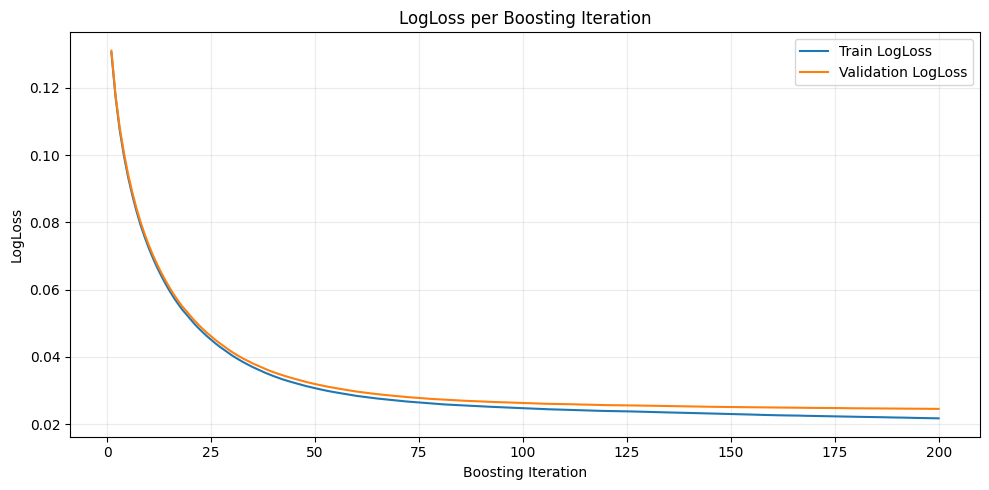

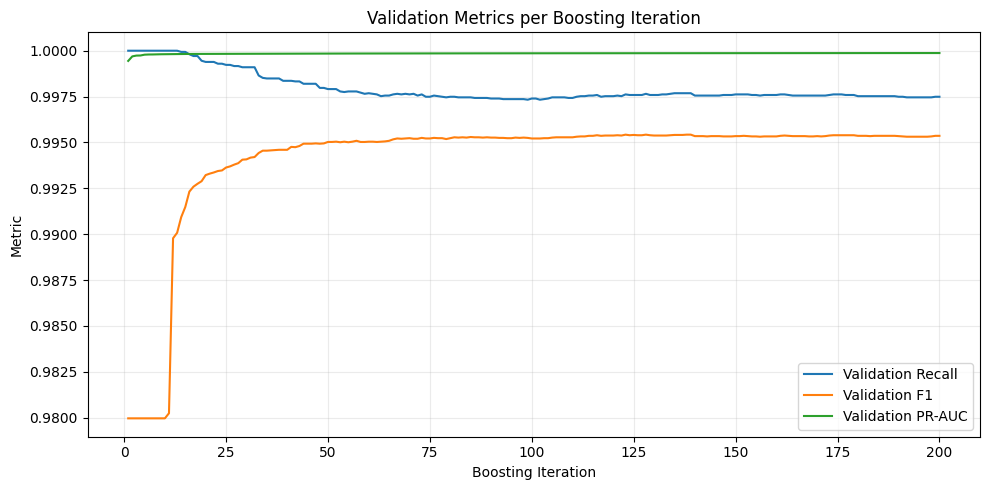

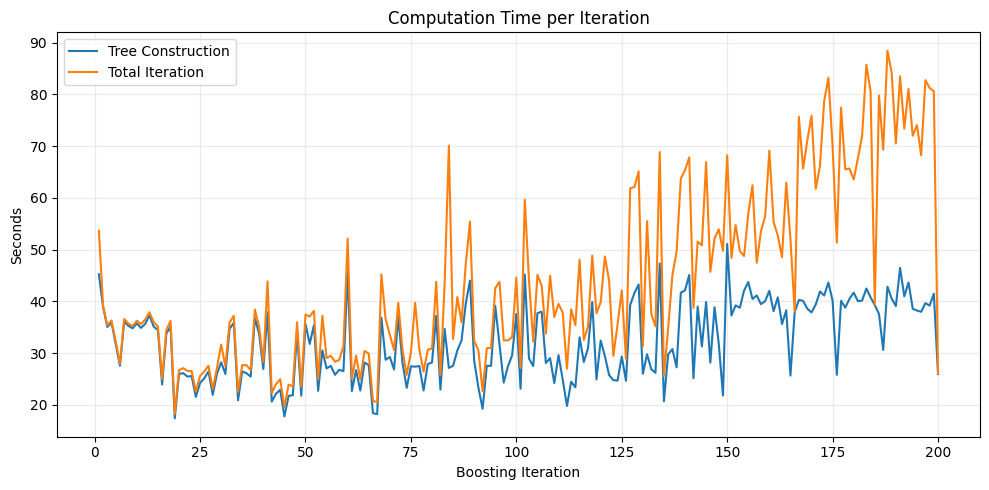

In [10]:
# ============================================================
# 9. PLOTS
# ============================================================
log_df = pd.DataFrame(iteration_logs)

plt.figure(figsize=(10,5))
plt.plot(log_df["iteration"], log_df["train_logloss"], label="Train LogLoss")
plt.plot(log_df["iteration"], log_df["valid_logloss"], label="Validation LogLoss")
plt.xlabel("Boosting Iteration")
plt.ylabel("LogLoss")
plt.title("LogLoss per Boosting Iteration")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "logloss_per_iteration.png"), dpi=150)
plt.show()

plt.figure(figsize=(10,5))
plt.plot(log_df["iteration"], log_df["valid_recall"], label="Validation Recall")
plt.plot(log_df["iteration"], log_df["valid_f1"], label="Validation F1")
plt.plot(log_df["iteration"], log_df["valid_prauc"], label="Validation PR-AUC")
plt.xlabel("Boosting Iteration")
plt.ylabel("Metric")
plt.title("Validation Metrics per Boosting Iteration")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "validation_metrics.png"), dpi=150)
plt.show()

plt.figure(figsize=(10,5))
plt.plot(log_df["iteration"], log_df["tree_time"], label="Tree Construction")
plt.plot(log_df["iteration"], log_df["iteration_time"], label="Total Iteration")
plt.xlabel("Boosting Iteration")
plt.ylabel("Seconds")
plt.title("Computation Time per Iteration")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "plots", "training_time_per_iteration.png"), dpi=150)
plt.show()


MASTER CELL — MANUAL TREE-SHAP + COMPLETE ANALYSIS

IMPORTANT:
- TreeSHAP AKAN DIHITUNG ULANG.
- Tidak menggunakan SHAP lama sebagai input utama.
- Output manual_treeshap_values.npy akan ditimpa.

1. LOAD X_TEST
X_test : (32348, 651)

2. LOAD FEATURE NAMES
Feature names : 651

3. LOAD NODE DETAILS
Rows : 13,704
Trees: 200

4. LOAD SELECTED SPLITS
Selected splits: 6,722
Trees: 199

6. RECONSTRUCTING TREES
Tree 001/199: nodes=105, depth=6, splits=52/52
Tree 020/199: nodes=65, depth=6, splits=32/32
Tree 040/199: nodes=69, depth=6, splits=34/34
Tree 060/199: nodes=87, depth=6, splits=43/43
Tree 080/199: nodes=53, depth=6, splits=26/26
Tree 100/199: nodes=85, depth=6, splits=42/42
Tree 120/199: nodes=43, depth=6, splits=21/21
Tree 140/199: nodes=103, depth=6, splits=51/51
Tree 160/199: nodes=117, depth=6, splits=58/58
Tree 180/199: nodes=89, depth=6, splits=44/44
Tree 199/199: nodes=103, depth=6, splits=51/51

✓ Semua 199 tree berhasil direconstruct.

7. APPLY LEARNING RATE
Learning rate = 

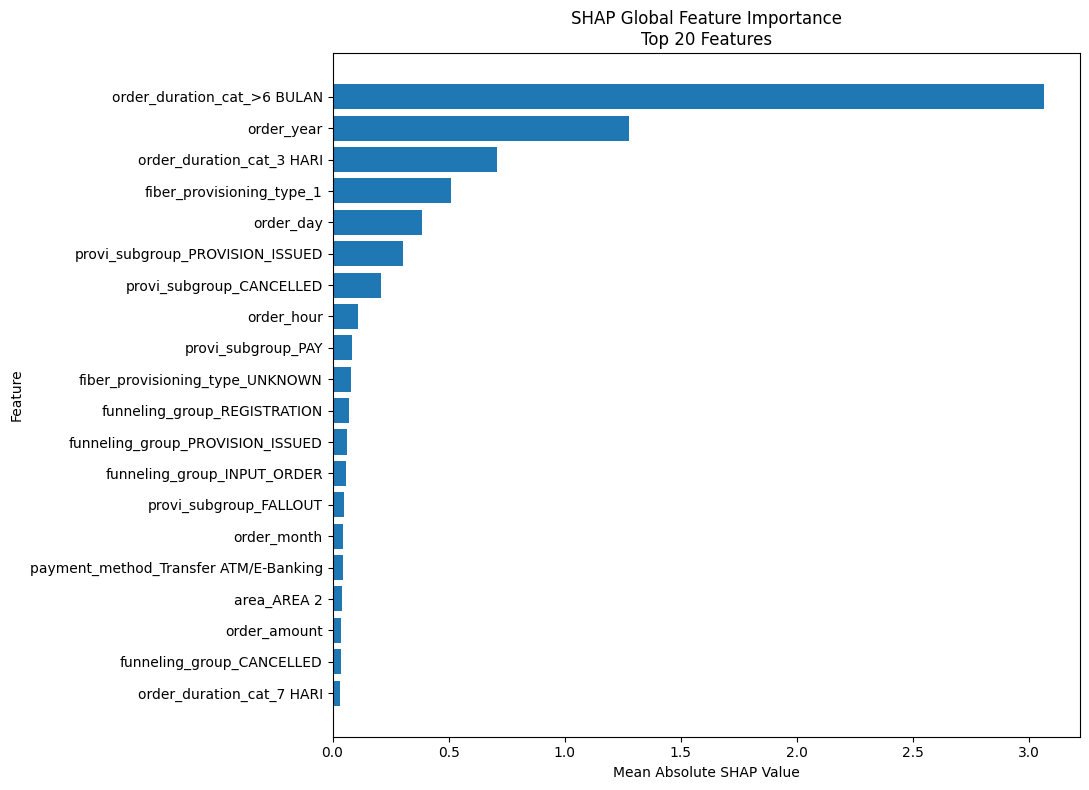


16. SHAP SUMMARY PLOT


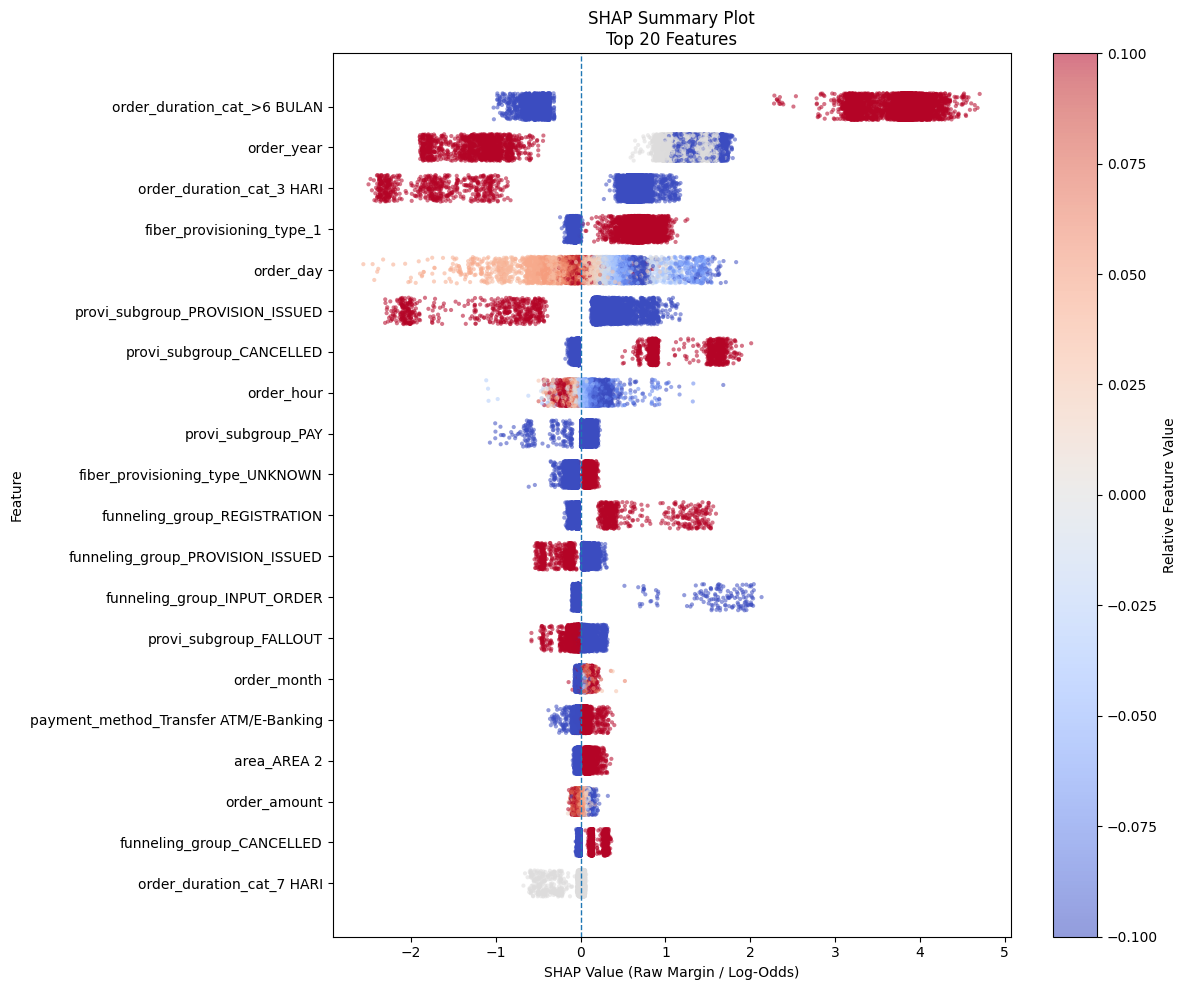

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/SHAP_SUMMARY_PLOT_FINAL.png

17. SHAP DEPENDENCE PLOTS


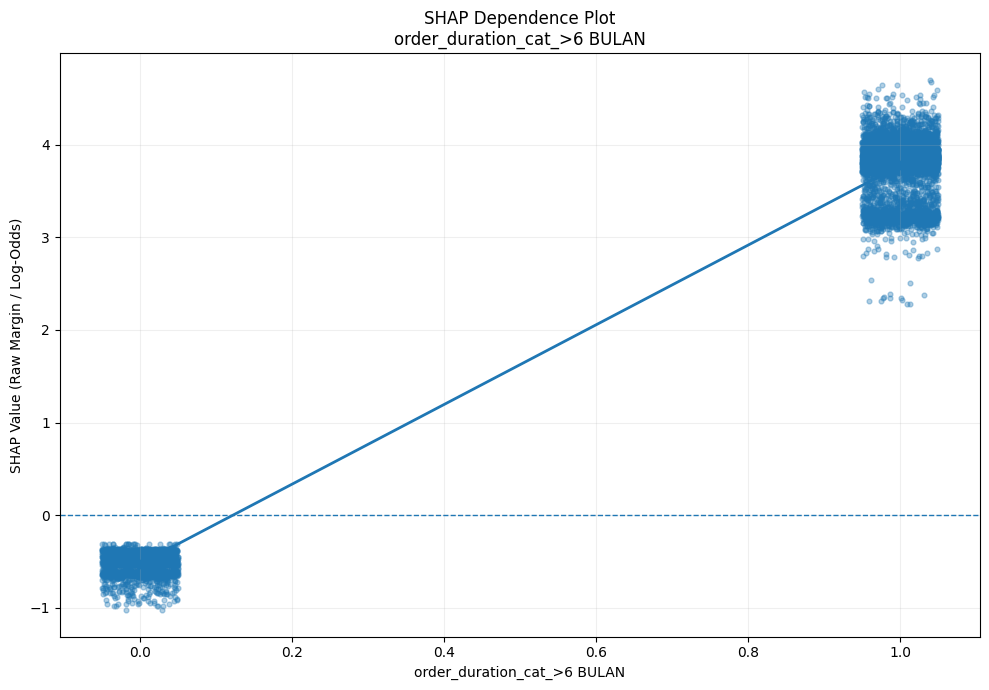

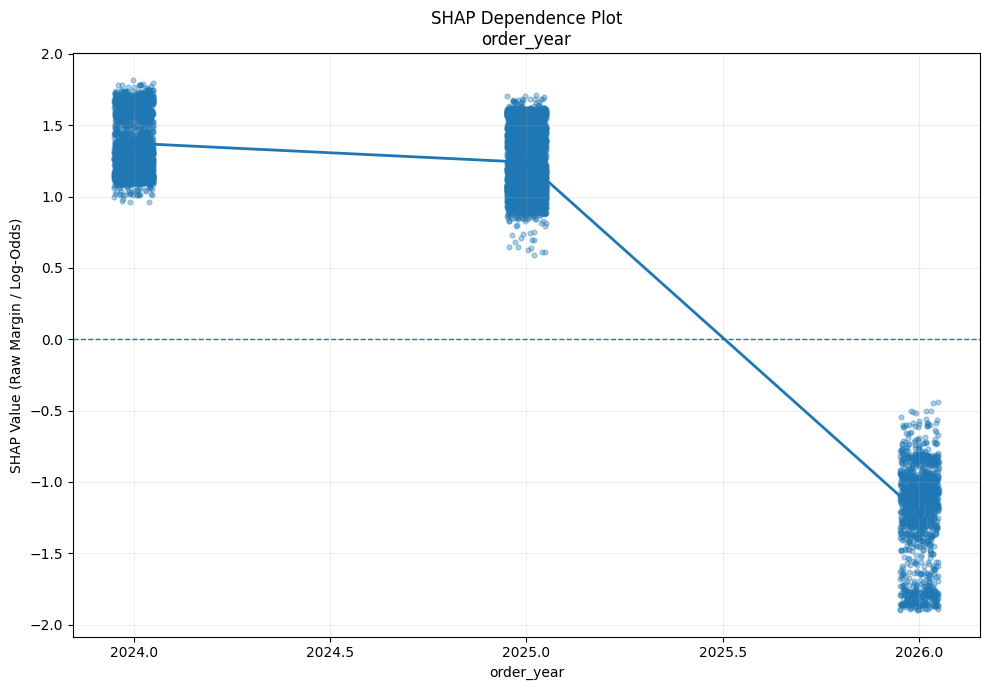

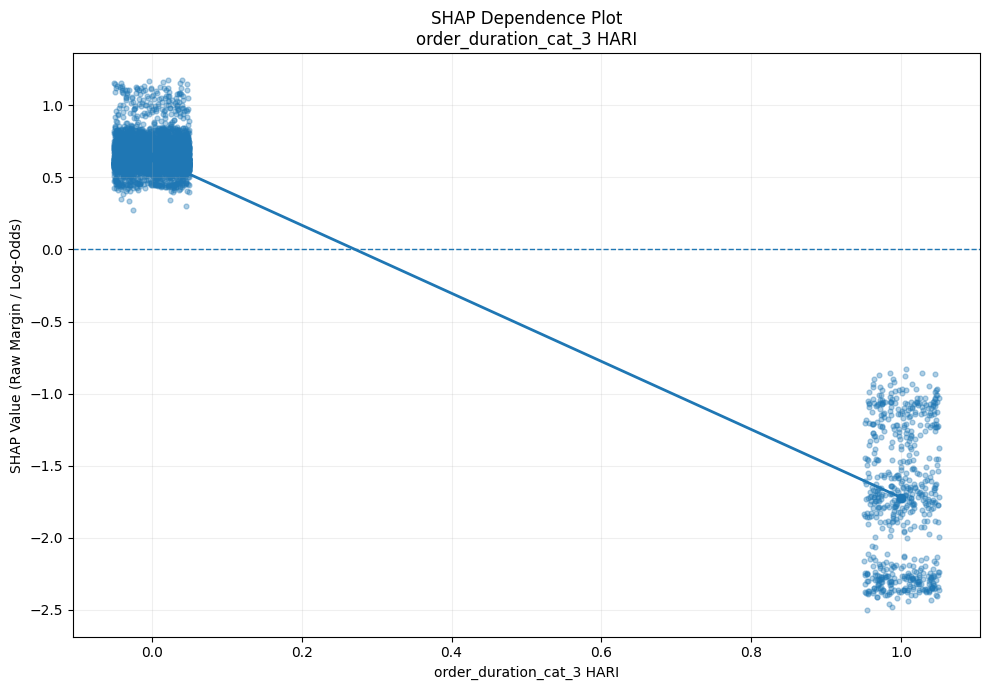

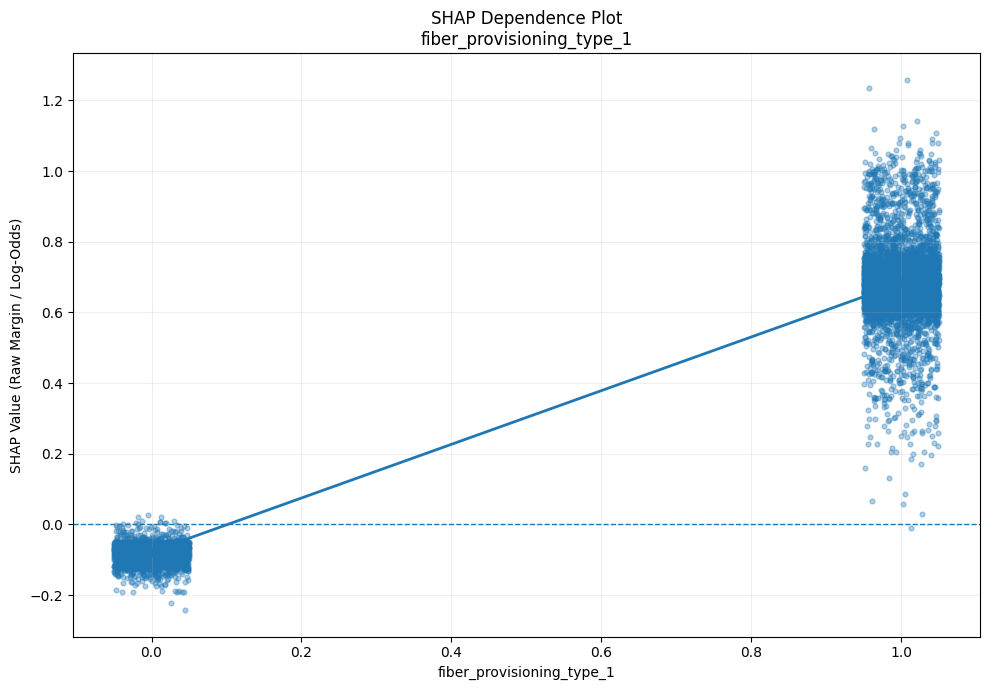

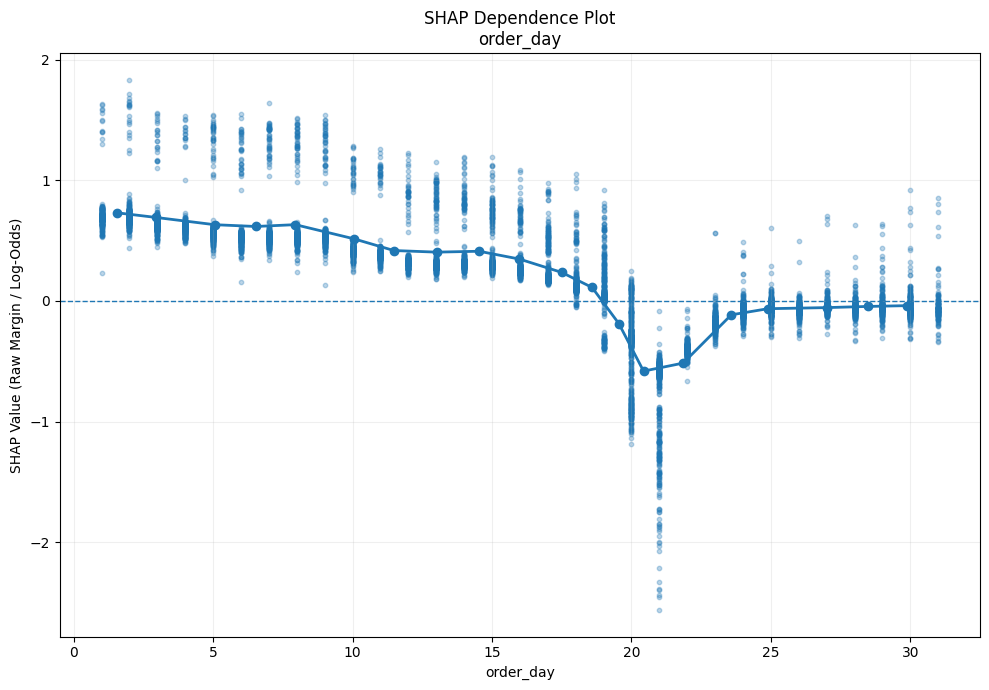

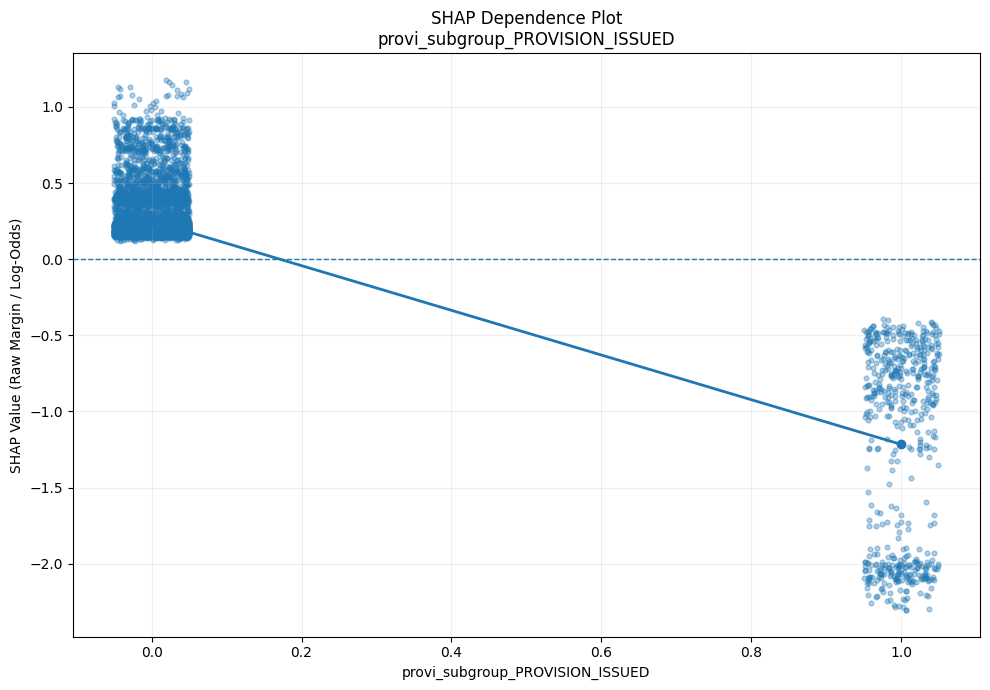

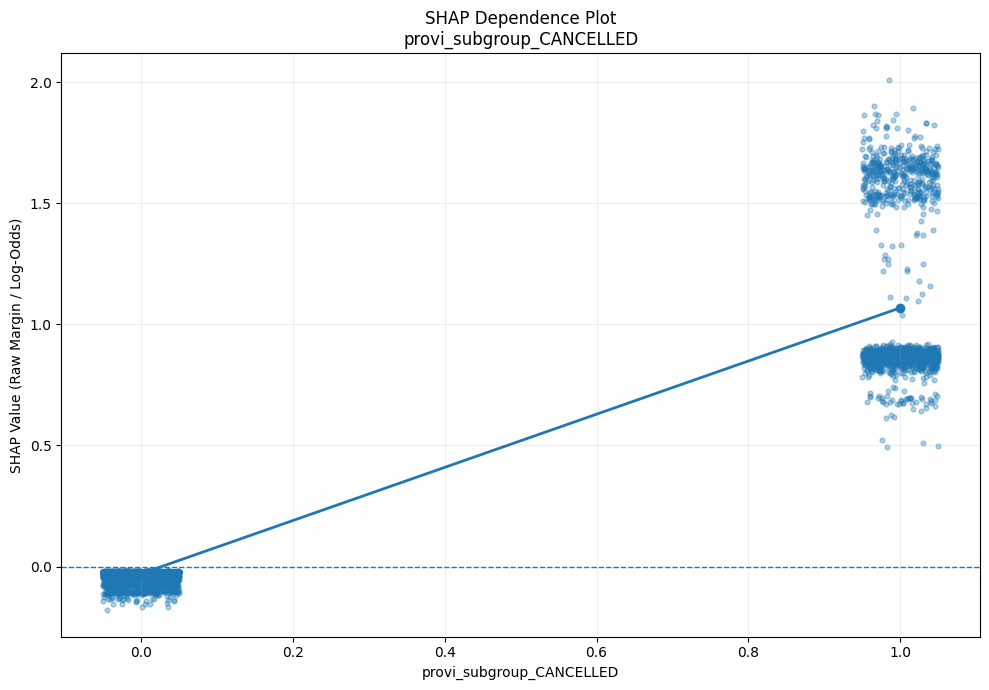

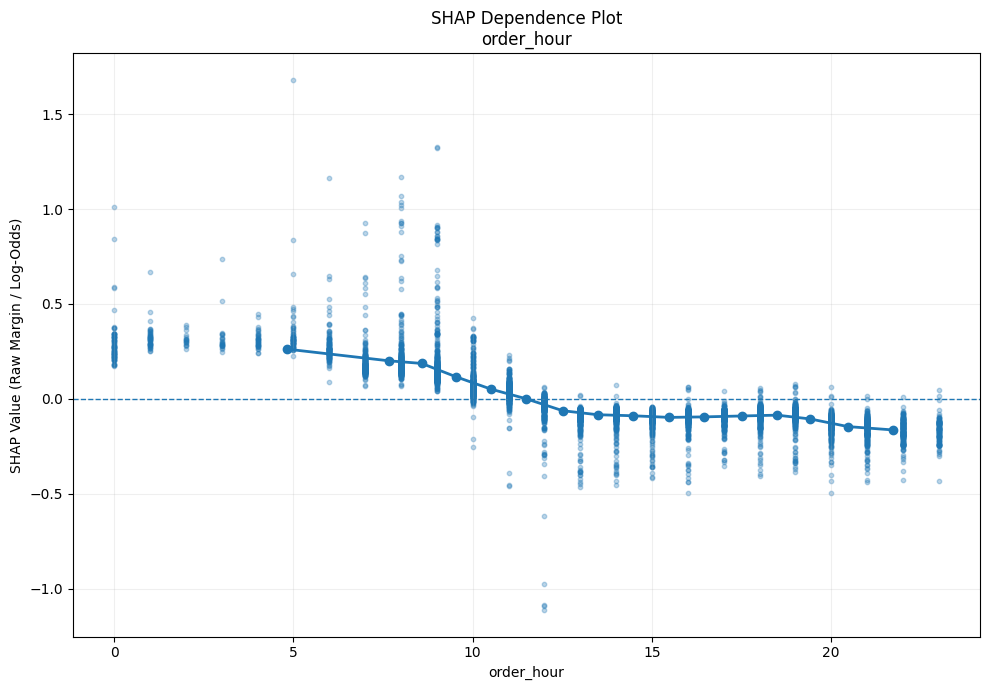

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/SHAP_DEPENDENCE_SUMMARY_FINAL.csv

18. ORIGINAL VARIABLE IMPORTANCE
      original_variable  n_encoded_features  mean_abs_shap  mean_shap                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [24]:
# ============================================================
# MASTER CELL — FINAL MANUAL TREE-SHAP + COMPLETE ANALYSIS
# ============================================================
#
# CELL INI MENGERJAKAN SEMUANYA DARI AWAL:
#
# A. LOAD MODEL TREE DARI LOG
# B. RECONSTRUCT 199 TREES
# C. MANUAL TREE-SHAP
# D. SAVE manual_treeshap_values.npy
# E. EXPECTED VALUE
# F. ADDITIVITY CHECK
# G. GLOBAL FEATURE IMPORTANCE
# H. SHAP SUMMARY PLOT
# I. SHAP DEPENDENCE PLOTS
# J. ORIGINAL VARIABLE IMPORTANCE
# K. REGION MAPPING
# L. REGIONAL SHAP
# M. TOP 10 FACTORS PER REGION
# N. GLOBAL VS REGIONAL
# O. REGIONAL RANKING MATRIX
# P. AUTOMATIC INTERPRETATION
#
# TIDAK PERLU MENJALANKAN CELL SHAP LAMA.
# REPLACE DENGAN CELL INI.
#
# ============================================================


import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")


# ============================================================
# 0. CONFIGURATION
# ============================================================

BASE_DIR = "/content/drive/MyDrive/SKRIPSI/FMC_2_8_MODELING"

RAW_DATA_PATH = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_FEATURE_ENGINEERING_FINAL.csv"
)

NODE_DETAILS_PATH = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_XGBOOST_HISTOGRAM_DETAILED/"
    "logs/node_details.csv"
)

SPLIT_DETAILS_PATH = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_XGBOOST_HISTOGRAM_DETAILED/"
    "logs/split_details.csv"
)

SHAP_DIR = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_SHAP_MANUAL_TREESHAP"
)

X_TEST_PATH = os.path.join(
    BASE_DIR,
    "X_test.npz"
)

Y_TRAIN_PATH = os.path.join(
    BASE_DIR,
    "y_train.csv"
)

Y_TEST_PATH = os.path.join(
    BASE_DIR,
    "y_test.csv"
)

FEATURE_NAMES_PATH = os.path.join(
    BASE_DIR,
    "feature_names_after_encoding.csv"
)

SHAP_VALUES_PATH = os.path.join(
    SHAP_DIR,
    "manual_treeshap_values.npy"
)

LEARNING_RATE = 0.05

N_TREES = 199

RANDOM_STATE = 42

TOP_N_GLOBAL = 20

TOP_N_DEPENDENCE = 8

TOP_N_REGION = 10

MAX_PLOT_OBS = 10000

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


print("=" * 80)
print("MASTER CELL — MANUAL TREE-SHAP + COMPLETE ANALYSIS")
print("=" * 80)
print()
print("IMPORTANT:")
print("- TreeSHAP AKAN DIHITUNG ULANG.")
print("- Tidak menggunakan SHAP lama sebagai input utama.")
print("- Output manual_treeshap_values.npy akan ditimpa.")
print()


# ============================================================
# 1. LOAD X_TEST
# ============================================================

print("=" * 80)
print("1. LOAD X_TEST")
print("=" * 80)

X_test_sparse = sp.load_npz(
    X_TEST_PATH
).tocsr()

N_TEST, N_FEATURES = X_test_sparse.shape

print(
    f"X_test : {X_test_sparse.shape}"
)

if N_TEST != 32348:
    print(
        "WARNING: jumlah test observation "
        f"={N_TEST}, bukan 32,348."
    )

if N_FEATURES != 651:
    print(
        "WARNING: jumlah fitur "
        f"={N_FEATURES}, bukan 651."
    )


# ============================================================
# 2. LOAD FEATURE NAMES
# ============================================================

print()
print("=" * 80)
print("2. LOAD FEATURE NAMES")
print("=" * 80)

feature_df = pd.read_csv(
    FEATURE_NAMES_PATH
)

candidate_feature_columns = [
    "feature",
    "feature_name",
    "features",
    "Feature",
    "Feature Name",
    "feature_names"
]

feature_col = None

for col in candidate_feature_columns:
    if col in feature_df.columns:
        feature_col = col
        break

if feature_col is None:
    feature_col = feature_df.columns[0]

feature_names = (
    feature_df[feature_col]
    .astype(str)
    .tolist()
)

if len(feature_names) != N_FEATURES:
    raise ValueError(
        f"Feature name count = {len(feature_names)}, "
        f"tetapi X_test memiliki {N_FEATURES} features."
    )

print(
    f"Feature names : {len(feature_names)}"
)


# ============================================================
# 3. LOAD NODE DETAILS
# ============================================================

print()
print("=" * 80)
print("3. LOAD NODE DETAILS")
print("=" * 80)

node_raw = pd.read_csv(
    NODE_DETAILS_PATH
)

# normalisasi nama kolom
node_raw.columns = [
    str(c).strip().lower()
    for c in node_raw.columns
]

required_node_columns = [
    "tree",
    "node",
    "depth",
    "samples",
    "g",
    "h",
    "leaf_weight"
]

missing_node_cols = [
    c
    for c in required_node_columns
    if c not in node_raw.columns
]

if missing_node_cols:
    raise ValueError(
        "Kolom node_details tidak ditemukan: "
        + str(missing_node_cols)
    )

node_raw = node_raw[
    required_node_columns
].copy()

node_raw["tree"] = pd.to_numeric(
    node_raw["tree"],
    errors="coerce"
)

node_raw["node"] = pd.to_numeric(
    node_raw["node"],
    errors="coerce"
)

node_raw["depth"] = pd.to_numeric(
    node_raw["depth"],
    errors="coerce"
)

node_raw["samples"] = pd.to_numeric(
    node_raw["samples"],
    errors="coerce"
)

node_raw["g"] = pd.to_numeric(
    node_raw["g"],
    errors="coerce"
)

node_raw["h"] = pd.to_numeric(
    node_raw["h"],
    errors="coerce"
)

node_raw["leaf_weight"] = pd.to_numeric(
    node_raw["leaf_weight"],
    errors="coerce"
)

node_raw = node_raw.dropna(
    subset=[
        "tree",
        "node",
        "depth",
        "g",
        "h"
    ]
)

node_raw["tree"] = node_raw[
    "tree"
].astype(int)

node_raw["node"] = node_raw[
    "node"
].astype(int)

node_raw["depth"] = node_raw[
    "depth"
].astype(int)

node_raw = node_raw.sort_values(
    ["tree", "node"]
).reset_index(drop=True)

print(
    f"Rows : {len(node_raw):,}"
)

print(
    "Trees:",
    node_raw["tree"].nunique()
)


# ============================================================
# 4. LOAD SELECTED SPLITS ONLY
# ============================================================

print()
print("=" * 80)
print("4. LOAD SELECTED SPLITS")
print("=" * 80)

# Karena split_details.csv sangat besar,
# kita baca chunk dan hanya simpan tree 1-199.

split_header = pd.read_csv(
    SPLIT_DETAILS_PATH,
    nrows=0
)

split_columns_raw = [
    str(c).strip()
    for c in split_header.columns
]

split_lower_map = {
    str(c).strip().lower(): c
    for c in split_columns_raw
}

required_split_lower = [
    "tree",
    "depth",
    "feature_idx",
    "feature_name",
    "threshold",
    "missing_direction",
    "g_parent",
    "h_parent",
    "g_left",
    "h_left",
    "g_right",
    "h_right"
]

missing_split = [
    c
    for c in required_split_lower
    if c not in split_lower_map
]

if missing_split:
    raise ValueError(
        "Kolom split_details tidak ditemukan: "
        + str(missing_split)
    )

usecols_actual = [
    split_lower_map[c]
    for c in required_split_lower
]

selected_split_chunks = []

for chunk in pd.read_csv(
    SPLIT_DETAILS_PATH,
    usecols=usecols_actual,
    chunksize=250000
):

    chunk.columns = [
        str(c).strip().lower()
        for c in chunk.columns
    ]

    chunk["tree"] = pd.to_numeric(
        chunk["tree"],
        errors="coerce"
    )

    chunk = chunk[
        chunk["tree"].between(
            1,
            N_TREES
        )
    ]

    if len(chunk) > 0:
        selected_split_chunks.append(
            chunk
        )

selected_splits = pd.concat(
    selected_split_chunks,
    ignore_index=True
)

for col in [
    "depth",
    "feature_idx"
]:
    selected_splits[col] = pd.to_numeric(
        selected_splits[col],
        errors="coerce"
    )

for col in [
    "threshold",
    "g_parent",
    "h_parent",
    "g_left",
    "h_left",
    "g_right",
    "h_right"
]:
    selected_splits[col] = pd.to_numeric(
        selected_splits[col],
        errors="coerce"
    )

selected_splits["tree"] = (
    selected_splits["tree"]
    .astype(int)
)

selected_splits = selected_splits.dropna(
    subset=[
        "depth",
        "feature_idx",
        "threshold",
        "g_parent",
        "h_parent",
        "g_left",
        "h_left",
        "g_right",
        "h_right"
    ]
).copy()

selected_splits["depth"] = (
    selected_splits["depth"]
    .astype(int)
)

selected_splits["feature_idx"] = (
    selected_splits["feature_idx"]
    .astype(int)
)

selected_splits = selected_splits.sort_values(
    ["tree", "depth"]
).reset_index(drop=True)

print(
    "Selected splits:",
    f"{len(selected_splits):,}"
)

print(
    "Trees:",
    selected_splits["tree"].nunique()
)


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def close_float(a, b):
    """
    Matching G/H antara node_details dan split_details.
    """
    if not np.isfinite(a) or not np.isfinite(b):
        return False

    return np.isclose(
        float(a),
        float(b),
        rtol=2e-5,
        atol=1e-7
    )


def get_right_child(
    depths,
    left_index,
    parent_depth
):
    """
    Node details menggunakan preorder/DFS.
    Setelah subtree kiri selesai,
    node berikutnya dengan depth parent+1
    adalah child kanan.
    """

    for j in range(
        left_index + 1,
        len(depths)
    ):
        if depths[j] == parent_depth + 1:
            return j

        if depths[j] <= parent_depth:
            return -1

    return -1


# ============================================================
# 6. RECONSTRUCT TREE STRUCTURE
# ============================================================

print()
print("=" * 80)
print("6. RECONSTRUCTING TREES")
print("=" * 80)

trees = []

mapping_failures = []

for tree_id in range(
    1,
    N_TREES + 1
):

    tree_nodes = node_raw[
        node_raw["tree"] == tree_id
    ].sort_values(
        "node"
    ).reset_index(drop=True)

    if len(tree_nodes) == 0:
        raise ValueError(
            f"Tree {tree_id} tidak ditemukan."
        )

    m = len(tree_nodes)

    depths = tree_nodes[
        "depth"
    ].to_numpy(
        dtype=np.int32
    )

    g_values = tree_nodes[
        "g"
    ].to_numpy(
        dtype=np.float64
    )

    h_values = tree_nodes[
        "h"
    ].to_numpy(
        dtype=np.float64
    )

    leaf_weights = tree_nodes[
        "leaf_weight"
    ].fillna(0.0).to_numpy(
        dtype=np.float64
    )

    children_left = np.full(
        m,
        -1,
        dtype=np.int32
    )

    children_right = np.full(
        m,
        -1,
        dtype=np.int32
    )

    children_default = np.full(
        m,
        -1,
        dtype=np.int32
    )

    features = np.full(
        m,
        -1,
        dtype=np.int32
    )

    thresholds = np.zeros(
        m,
        dtype=np.float64
    )

    split_rows = selected_splits[
        selected_splits["tree"]
        == tree_id
    ].copy()

    # --------------------------------------------------------
    # map selected split -> local node
    # --------------------------------------------------------

    used_split_indices = set()

    for local_node in range(m):

        node_depth = depths[
            local_node
        ]

        node_g = g_values[
            local_node
        ]

        node_h = h_values[
            local_node
        ]

        candidates = split_rows[
            split_rows["depth"]
            == node_depth
        ]

        if len(candidates) == 0:
            continue

        # Parent G/H harus cocok
        candidates = candidates[
            candidates.apply(
                lambda r:
                    close_float(
                        r["g_parent"],
                        node_g
                    )
                    and
                    close_float(
                        r["h_parent"],
                        node_h
                    ),
                axis=1
            )
        ]

        if len(candidates) == 0:
            continue

        # child kiri
        if local_node + 1 >= m:
            continue

        left_child = local_node + 1

        right_child = get_right_child(
            depths,
            left_child,
            node_depth
        )

        if right_child < 0:
            continue

        left_g = g_values[
            left_child
        ]

        left_h = h_values[
            left_child
        ]

        right_g = g_values[
            right_child
        ]

        right_h = h_values[
            right_child
        ]

        matched = None

        for idx, row in candidates.iterrows():

            same_order = (
                close_float(
                    row["g_left"],
                    left_g
                )
                and
                close_float(
                    row["h_left"],
                    left_h
                )
                and
                close_float(
                    row["g_right"],
                    right_g
                )
                and
                close_float(
                    row["h_right"],
                    right_h
                )
            )

            reverse_order = (
                close_float(
                    row["g_left"],
                    right_g
                )
                and
                close_float(
                    row["h_left"],
                    right_h
                )
                and
                close_float(
                    row["g_right"],
                    left_g
                )
                and
                close_float(
                    row["h_right"],
                    left_h
                )
            )

            if same_order or reverse_order:
                matched = (
                    idx,
                    row,
                    same_order
                )
                break

        if matched is None:
            continue

        split_idx, row, same_order = matched

        if split_idx in used_split_indices:
            continue

        used_split_indices.add(
            split_idx
        )

        children_left[
            local_node
        ] = left_child

        children_right[
            local_node
        ] = right_child

        feature_idx = int(
            row["feature_idx"]
        )

        if (
            feature_idx < 0
            or feature_idx >= N_FEATURES
        ):
            raise ValueError(
                f"Invalid feature_idx "
                f"{feature_idx} "
                f"di tree {tree_id}, "
                f"node {local_node}"
            )

        features[
            local_node
        ] = feature_idx

        thresholds[
            local_node
        ] = float(
            row["threshold"]
        )

        missing_direction = str(
            row["missing_direction"]
        ).strip().upper()

        if missing_direction == "LEFT":
            children_default[
                local_node
            ] = left_child

        elif missing_direction == "RIGHT":
            children_default[
                local_node
            ] = right_child

        else:
            raise ValueError(
                f"Missing direction tidak dikenal: "
                f"{missing_direction}"
            )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    internal_nodes = np.where(
        children_right >= 0
    )[0]

    mapped_splits = len(
        internal_nodes
    )

    expected_splits = len(
        split_rows
    )

    if mapped_splits != expected_splits:

        mapping_failures.append({
            "tree": tree_id,
            "expected_splits": expected_splits,
            "mapped_splits": mapped_splits
        })

    # --------------------------------------------------------
    # Tree object
    # --------------------------------------------------------

    trees.append({
        "tree": tree_id,
        "children_left": children_left,
        "children_right": children_right,
        "children_default": children_default,
        "features": features,
        "thresholds": thresholds,
        "leaf_weights": leaf_weights,
        "cover": h_values,
        "depth": int(
            np.max(depths)
        )
    })

    if (
        tree_id == 1
        or tree_id % 20 == 0
        or tree_id == N_TREES
    ):

        print(
            f"Tree {tree_id:03d}/{N_TREES}: "
            f"nodes={m}, "
            f"depth={np.max(depths)}, "
            f"splits={mapped_splits}/{expected_splits}"
        )


print()

if mapping_failures:

    print(
        "WARNING: terdapat tree dengan "
        "mapping split tidak sempurna:"
    )

    for x in mapping_failures[:20]:
        print(x)

    raise ValueError(
        "Reconstruction tree gagal. "
        "Jangan lanjut ke SHAP."
    )

else:

    print(
        "✓ Semua 199 tree berhasil "
        "direconstruct."
    )


# ============================================================
# 7. APPLY LEARNING RATE TO LEAF VALUES
# ============================================================

print()
print("=" * 80)
print("7. APPLY LEARNING RATE")
print("=" * 80)

for tree in trees:

    tree["values"] = (
        tree["leaf_weights"]
        * LEARNING_RATE
    )

print(
    f"Learning rate = {LEARNING_RATE}"
)


# ============================================================
# 8. LOAD TRAIN TARGET FOR BASE MARGIN
# ============================================================

print()
print("=" * 80)
print("8. CALCULATE BASE MARGIN")
print("=" * 80)

y_train_df = pd.read_csv(
    Y_TRAIN_PATH
)

if y_train_df.shape[1] == 1:
    y_train = y_train_df.iloc[
        :, 0
    ].to_numpy()
else:

    # cari kolom numerik pertama
    numeric_candidates = []

    for c in y_train_df.columns:

        vals = pd.to_numeric(
            y_train_df[c],
            errors="coerce"
        )

        if vals.notna().all():
            numeric_candidates.append(
                c
            )

    if len(numeric_candidates) == 0:
        raise ValueError(
            "Tidak menemukan y_train."
        )

    y_train = y_train_df[
        numeric_candidates[0]
    ].to_numpy()

y_train = pd.to_numeric(
    y_train,
    errors="coerce"
).astype(int)

train_positive_rate = np.mean(
    y_train
)

train_positive_rate = np.clip(
    train_positive_rate,
    1e-15,
    1 - 1e-15
)

base_margin = np.log(
    train_positive_rate
    / (
        1 - train_positive_rate
    )
)

print(
    f"Train positive rate : "
    f"{train_positive_rate:.12f}"
)

print(
    f"Base margin         : "
    f"{base_margin:.12f}"
)


# ============================================================
# 9. NUMBA TREE-SHAP FUNCTIONS
# ============================================================

print()
print("=" * 80)
print("9. PREPARE MANUAL TREE-SHAP ENGINE")
print("=" * 80)

from numba import njit, prange


@njit(cache=False)
def extend_path(
    feature_indexes,
    zero_fractions,
    one_fractions,
    pweights,
    unique_depth,
    zero_fraction,
    one_fraction,
    feature_index
):

    feature_indexes[
        unique_depth
    ] = feature_index

    zero_fractions[
        unique_depth
    ] = zero_fraction

    one_fractions[
        unique_depth
    ] = one_fraction

    if unique_depth == 0:

        pweights[
            unique_depth
        ] = 1.0

    else:

        pweights[
            unique_depth
        ] = 0.0

    for i in range(
        unique_depth - 1,
        -1,
        -1
    ):

        pweights[
            i + 1
        ] += (
            one_fraction
            * pweights[i]
            * (i + 1.0)
            / (unique_depth + 1.0)
        )

        pweights[
            i
        ] = (
            zero_fraction
            * pweights[i]
            * (unique_depth - i)
            / (unique_depth + 1.0)
        )


@njit(cache=False)
def unwind_path(
    feature_indexes,
    zero_fractions,
    one_fractions,
    pweights,
    unique_depth,
    path_index
):

    one_fraction = one_fractions[
        path_index
    ]

    zero_fraction = zero_fractions[
        path_index
    ]

    next_one_portion = pweights[
        unique_depth
    ]

    for i in range(
        unique_depth - 1,
        -1,
        -1
    ):

        if one_fraction != 0.0:

            tmp = pweights[i]

            pweights[i] = (
                next_one_portion
                * (unique_depth + 1.0)
                / (
                    (i + 1.0)
                    * one_fraction
                )
            )

            next_one_portion = (
                tmp
                - pweights[i]
                * zero_fraction
                * (
                    (unique_depth - i)
                    / (unique_depth + 1.0)
                )
            )

        else:

            denom = (
                zero_fraction
                * (unique_depth - i)
            )

            if denom != 0.0:

                pweights[i] = (
                    pweights[i]
                    * (unique_depth + 1.0)
                    / denom
                )

    for i in range(
        path_index,
        unique_depth
    ):

        feature_indexes[i] = (
            feature_indexes[i + 1]
        )

        zero_fractions[i] = (
            zero_fractions[i + 1]
        )

        one_fractions[i] = (
            one_fractions[i + 1]
        )


@njit(cache=False)
def unwound_path_sum(
    feature_indexes,
    zero_fractions,
    one_fractions,
    pweights,
    unique_depth,
    path_index
):

    one_fraction = one_fractions[
        path_index
    ]

    zero_fraction = zero_fractions[
        path_index
    ]

    next_one_portion = pweights[
        unique_depth
    ]

    total = 0.0

    for i in range(
        unique_depth - 1,
        -1,
        -1
    ):

        if one_fraction != 0.0:

            tmp = (
                next_one_portion
                * (unique_depth + 1.0)
                / (
                    (i + 1.0)
                    * one_fraction
                )
            )

            total += tmp

            next_one_portion = (
                pweights[i]
                - tmp
                * zero_fraction
                * (
                    (unique_depth - i)
                    / (unique_depth + 1.0)
                )
            )

        else:

            denom = (
                zero_fraction
            )

            if denom != 0.0:

                total += (
                    pweights[i]
                    / denom
                ) / (
                    (unique_depth - i)
                    / (unique_depth + 1.0)
                )

    return total


@njit(cache=False)
def tree_shap_recursive(
    children_left,
    children_right,
    children_default,
    features,
    thresholds,
    values,
    cover,
    x,
    x_missing,
    phi,
    node_index,
    unique_depth,
    parent_feature_indexes,
    parent_zero_fractions,
    parent_one_fractions,
    parent_pweights,
    parent_zero_fraction,
    parent_one_fraction,
    parent_feature_index
):

    # --------------------------------------------------------
    # Copy current path
    # --------------------------------------------------------

    feature_indexes = (
        parent_feature_indexes[
            unique_depth + 1:
        ]
    )

    zero_fractions = (
        parent_zero_fractions[
            unique_depth + 1:
        ]
    )

    one_fractions = (
        parent_one_fractions[
            unique_depth + 1:
        ]
    )

    pweights = (
        parent_pweights[
            unique_depth + 1:
        ]
    )

    for i in range(
        unique_depth + 1
    ):

        feature_indexes[i] = (
            parent_feature_indexes[i]
        )

        zero_fractions[i] = (
            parent_zero_fractions[i]
        )

        one_fractions[i] = (
            parent_one_fractions[i]
        )

        pweights[i] = (
            parent_pweights[i]
        )

    # --------------------------------------------------------
    # Extend path
    # --------------------------------------------------------

    extend_path(
        feature_indexes,
        zero_fractions,
        one_fractions,
        pweights,
        unique_depth,
        parent_zero_fraction,
        parent_one_fraction,
        parent_feature_index
    )

    split_index = features[
        node_index
    ]

    # --------------------------------------------------------
    # LEAF
    # --------------------------------------------------------

    if children_right[
        node_index
    ] == -1:

        for i in range(
            1,
            unique_depth + 1
        ):

            w = unwound_path_sum(
                feature_indexes,
                zero_fractions,
                one_fractions,
                pweights,
                unique_depth,
                i
            )

            phi[
                feature_indexes[i]
            ] += (
                w
                * (
                    one_fractions[i]
                    - zero_fractions[i]
                )
                * values[node_index]
            )

        return

    # --------------------------------------------------------
    # INTERNAL NODE
    # --------------------------------------------------------

    cleft = children_left[
        node_index
    ]

    cright = children_right[
        node_index
    ]

    # --------------------------------------------------------
    # MODEL MANUAL CONVENTION:
    #
    # missing -> default direction
    # x <= threshold -> LEFT
    # x > threshold  -> RIGHT
    # --------------------------------------------------------

    if x_missing[
        split_index
    ]:

        hot_index = children_default[
            node_index
        ]

    elif (
        x[split_index]
        <= thresholds[node_index]
    ):

        hot_index = cleft

    else:

        hot_index = cright

    if hot_index == cleft:

        cold_index = cright

    else:

        cold_index = cleft

    parent_cover = cover[
        node_index
    ]

    if parent_cover <= 0.0:
        return

    hot_zero_fraction = (
        cover[hot_index]
        / parent_cover
    )

    cold_zero_fraction = (
        cover[cold_index]
        / parent_cover
    )

    incoming_zero_fraction = 1.0
    incoming_one_fraction = 1.0

    # --------------------------------------------------------
    # Repeated feature:
    # unwind previous occurrence
    # --------------------------------------------------------

    path_index = 0

    while path_index <= unique_depth:

        if (
            feature_indexes[path_index]
            == split_index
        ):
            break

        path_index += 1

    if path_index != (
        unique_depth + 1
    ):

        incoming_zero_fraction = (
            zero_fractions[path_index]
        )

        incoming_one_fraction = (
            one_fractions[path_index]
        )

        unwind_path(
            feature_indexes,
            zero_fractions,
            one_fractions,
            pweights,
            unique_depth,
            path_index
        )

        unique_depth -= 1

    # --------------------------------------------------------
    # HOT BRANCH
    # --------------------------------------------------------

    tree_shap_recursive(
        children_left,
        children_right,
        children_default,
        features,
        thresholds,
        values,
        cover,
        x,
        x_missing,
        phi,
        hot_index,
        unique_depth + 1,
        feature_indexes,
        zero_fractions,
        one_fractions,
        pweights,
        hot_zero_fraction
        * incoming_zero_fraction,
        incoming_one_fraction,
        split_index
    )

    # --------------------------------------------------------
    # COLD BRANCH
    # --------------------------------------------------------

    tree_shap_recursive(
        children_left,
        children_right,
        children_default,
        features,
        thresholds,
        values,
        cover,
        x,
        x_missing,
        phi,
        cold_index,
        unique_depth + 1,
        feature_indexes,
        zero_fractions,
        one_fractions,
        pweights,
        cold_zero_fraction
        * incoming_zero_fraction,
        0.0,
        split_index
    )


# ============================================================
# 10. TREE-SHAP ONE OBSERVATION
# ============================================================

@njit(cache=False)
def explain_one_tree(
    x,
    children_left,
    children_right,
    children_default,
    features,
    thresholds,
    values,
    cover,
    max_depth,
    n_features
):

    phi = np.zeros(
        n_features,
        dtype=np.float64
    )

    x_missing = np.zeros(
        n_features,
        dtype=np.bool_
    )

    for j in range(
        n_features
    ):

        x_missing[j] = np.isnan(
            x[j]
        )

    # triangular path storage
    path_size = (
        (max_depth + 2)
        * (max_depth + 3)
    ) // 2

    feature_indexes = np.zeros(
        path_size,
        dtype=np.int32
    )

    zero_fractions = np.zeros(
        path_size,
        dtype=np.float64
    )

    one_fractions = np.zeros(
        path_size,
        dtype=np.float64
    )

    pweights = np.zeros(
        path_size,
        dtype=np.float64
    )

    # root path
    parent_feature_indexes = (
        feature_indexes
    )

    parent_zero_fractions = (
        zero_fractions
    )

    parent_one_fractions = (
        one_fractions
    )

    parent_pweights = (
        pweights
    )

    tree_shap_recursive(
        children_left,
        children_right,
        children_default,
        features,
        thresholds,
        values,
        cover,
        x,
        x_missing,
        phi,
        0,
        0,
        parent_feature_indexes,
        parent_zero_fractions,
        parent_one_fractions,
        parent_pweights,
        1.0,
        1.0,
        -1
    )

    return phi


# ============================================================
# 11. COMPILE TEST
# ============================================================

print()
print("=" * 80)
print("10. NUMBA COMPILE TEST")
print("=" * 80)

compile_start = time.time()

test_x = (
    X_test_sparse[0]
    .toarray()
    .ravel()
    .astype(np.float64)
)

_ = explain_one_tree(
    test_x,
    trees[0]["children_left"],
    trees[0]["children_right"],
    trees[0]["children_default"],
    trees[0]["features"],
    trees[0]["thresholds"],
    trees[0]["values"],
    trees[0]["cover"],
    trees[0]["depth"],
    N_FEATURES
)

print(
    f"Compile/test time : "
    f"{time.time() - compile_start:.2f}s"
)


# ============================================================
# 12. TREE EXPECTED VALUE
# ============================================================

print()
print("=" * 80)
print("11. TREE EXPECTED VALUES")
print("=" * 80)

tree_expected_values = []

for tree in trees:

    # weighted average of leaves
    # using Hessian cover
    children_left = tree[
        "children_left"
    ]

    children_right = tree[
        "children_right"
    ]

    values = tree[
        "values"
    ]

    cover = tree[
        "cover"
    ]

    # recursively calculate expectation
    def recursive_expectation(
        node
    ):

        if children_right[
            node
        ] == -1:

            return values[
                node
            ]

        left = recursive_expectation(
            children_left[node]
        )

        right = recursive_expectation(
            children_right[node]
        )

        left_cover = cover[
            children_left[node]
        ]

        right_cover = cover[
            children_right[node]
        ]

        total_cover = (
            left_cover
            + right_cover
        )

        if total_cover <= 0:
            return 0.0

        return (
            left_cover * left
            + right_cover * right
        ) / total_cover

    expected_tree = (
        recursive_expectation(0)
    )

    tree_expected_values.append(
        expected_tree
    )

tree_expected_values = np.asarray(
    tree_expected_values,
    dtype=np.float64
)

tree_contribution = np.sum(
    tree_expected_values
)

expected_value = (
    base_margin
    + tree_contribution
)

print(
    f"Base margin       : "
    f"{base_margin:.10f}"
)

print(
    f"Tree contribution : "
    f"{tree_contribution:.10f}"
)

print(
    f"Expected value    : "
    f"{expected_value:.10f}"
)


# ============================================================
# 13. CALCULATE MANUAL TREE-SHAP
# ============================================================

print()
print("=" * 80)
print("12. MANUAL TREE-SHAP — ACTUAL CALCULATION")
print("=" * 80)

print(
    f"Observations : {N_TEST:,}"
)

print(
    f"Features     : {N_FEATURES:,}"
)

print(
    f"Trees        : {N_TREES}"
)

print(
    "Output       : raw margin / log-odds"
)

print(
    "Algorithm    : Manual TreeSHAP "
    "path-dependent"
)

print()

# ------------------------------------------------------------
# Dense test matrix
# ------------------------------------------------------------

print(
    "Converting X_test to dense float64..."
)

dense_start = time.time()

X_test_dense = (
    X_test_sparse
    .toarray()
    .astype(np.float64)
)

print(
    f"Dense conversion : "
    f"{time.time() - dense_start:.2f}s"
)

# ------------------------------------------------------------
# SHAP result
# ------------------------------------------------------------

manual_shap = np.zeros(
    (
        N_TEST,
        N_FEATURES
    ),
    dtype=np.float64
)

shap_start = time.time()

for tree_no, tree in enumerate(
    trees,
    start=1
):

    tree_start = time.time()

    # --------------------------------------------------------
    # Per tree
    # --------------------------------------------------------

    for i in range(
        N_TEST
    ):

        manual_shap[
            i
        ] += explain_one_tree(
            X_test_dense[i],
            tree["children_left"],
            tree["children_right"],
            tree["children_default"],
            tree["features"],
            tree["thresholds"],
            tree["values"],
            tree["cover"],
            tree["depth"],
            N_FEATURES
        )

    elapsed = (
        time.time()
        - shap_start
    )

    percent = (
        tree_no
        / N_TREES
        * 100
    )

    eta = (
        elapsed
        / tree_no
        * (N_TREES - tree_no)
    )

    print(
        f"[{tree_no:03d}/{N_TREES}] "
        f"{percent:6.2f}% | "
        f"tree={time.time()-tree_start:.2f}s | "
        f"elapsed={elapsed/60:.2f}m | "
        f"ETA={eta/60:.2f}m"
    )

total_shap_time = (
    time.time()
    - shap_start
)

print()
print(
    f"TOTAL TREE-SHAP TIME : "
    f"{total_shap_time:.2f}s "
    f"({total_shap_time/60:.2f} menit)"
)


# ============================================================
# 14. SAVE RAW SHAP VALUES
# ============================================================

print()
print("=" * 80)
print("13. SAVE TREE-SHAP VALUES")
print("=" * 80)

np.save(
    SHAP_VALUES_PATH,
    manual_shap
)

print(
    "Saved:",
    SHAP_VALUES_PATH
)

print(
    "Shape:",
    manual_shap.shape
)


# ============================================================
# 15. MANUAL MODEL PREDICTION
# ============================================================

def predict_tree_python(
    x,
    tree
):

    node = 0

    while (
        tree["children_right"][node]
        != -1
    ):

        feature = tree[
            "features"
        ][node]

        value = x[
            feature
        ]

        if np.isnan(value):

            node = tree[
                "children_default"
            ][node]

        elif (
            value
            <= tree["thresholds"][node]
        ):

            node = tree[
                "children_left"
            ][node]

        else:

            node = tree[
                "children_right"
            ][node]

    return tree[
        "values"
    ][node]


# ============================================================
# 16. ADDITIVITY CHECK
# ============================================================

print()
print("=" * 80)
print("14. ADDITIVITY CHECK")
print("=" * 80)

CHECK_N = min(
    100,
    N_TEST
)

errors = []

for i in range(
    CHECK_N
):

    x = X_test_dense[i]

    manual_model_margin = (
        base_margin
    )

    for tree in trees:

        manual_model_margin += (
            predict_tree_python(
                x,
                tree
            )
        )

    shap_reconstructed_margin = (
        expected_value
        + np.sum(
            manual_shap[i]
        )
    )

    errors.append(
        abs(
            manual_model_margin
            - shap_reconstructed_margin
        )
    )

errors = np.asarray(
    errors
)

max_error = float(
    np.max(errors)
)

mean_error = float(
    np.mean(errors)
)

print(
    f"Checked observations : "
    f"{CHECK_N}"
)

print(
    f"Max |error|          : "
    f"{max_error:.12e}"
)

print(
    f"Mean |error|         : "
    f"{mean_error:.12e}"
)

# threshold konservatif
ADDITIVITY_TOL = 1e-5

if max_error <= ADDITIVITY_TOL:

    print()
    print(
        "✓ ADDITIVITY PASS"
    )

else:

    print()
    print(
        "✗ ADDITIVITY FAIL"
    )

    raise ValueError(
        "Additivity check gagal. "
        "JANGAN gunakan hasil SHAP untuk skripsi "
        "sebelum reconstruction diperbaiki."
    )


# ============================================================
# 17. GLOBAL FEATURE IMPORTANCE
# ============================================================

print()
print("=" * 80)
print("15. GLOBAL FEATURE IMPORTANCE")
print("=" * 80)

mean_abs_shap = np.mean(
    np.abs(manual_shap),
    axis=0
)

mean_shap = np.mean(
    manual_shap,
    axis=0
)

global_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap,
    "mean_shap": mean_shap
})

global_df = global_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(
    drop=True
)

global_df["rank"] = (
    np.arange(
        1,
        len(global_df) + 1
    )
)

global_df["direction"] = np.where(
    global_df["mean_shap"] > 0,
    "Mendorong STUCK",
    np.where(
        global_df["mean_shap"] < 0,
        "Mendorong NOT-STUCK",
        "Netral"
    )
)

global_path = os.path.join(
    SHAP_DIR,
    "SHAP_GLOBAL_IMPORTANCE_FINAL.csv"
)

global_df.to_csv(
    global_path,
    index=False
)

print(
    global_df.head(
        TOP_N_GLOBAL
    ).to_string(
        index=False
    )
)

print()
print(
    "Saved:",
    global_path
)


# ============================================================
# 18. GLOBAL IMPORTANCE PLOT
# ============================================================

plot_df = (
    global_df
    .head(TOP_N_GLOBAL)
    .sort_values(
        "mean_abs_shap"
    )
)

plt.figure(
    figsize=(11, 8)
)

plt.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "SHAP Global Feature Importance\n"
    "Top 20 Features"
)

plt.tight_layout()

global_plot_path = os.path.join(
    SHAP_DIR,
    "SHAP_GLOBAL_FEATURE_IMPORTANCE_FINAL.png"
)

plt.savefig(
    global_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 19. SHAP SUMMARY PLOT
# ============================================================

print()
print("=" * 80)
print("16. SHAP SUMMARY PLOT")
print("=" * 80)

summary_features = (
    global_df
    .head(TOP_N_GLOBAL)
    ["feature"]
    .tolist()
)

summary_indices = [
    feature_names.index(f)
    for f in summary_features
]

rng = np.random.default_rng(
    RANDOM_STATE
)

if N_TEST > MAX_PLOT_OBS:

    plot_idx = rng.choice(
        N_TEST,
        size=MAX_PLOT_OBS,
        replace=False
    )

else:

    plot_idx = np.arange(
        N_TEST
    )

X_summary = X_test_dense[
    np.ix_(
        plot_idx,
        summary_indices
    )
]

SHAP_summary = manual_shap[
    np.ix_(
        plot_idx,
        summary_indices
    )
]

fig, ax = plt.subplots(
    figsize=(12, 10)
)

for row in range(
    len(summary_features)
):

    x = SHAP_summary[
        :, row
    ]

    feature_value = X_summary[
        :, row
    ]

    jitter = (
        rng.random(
            len(x)
        ) - 0.5
    ) * 0.65

    y = (
        len(summary_features)
        - 1
        - row
        + jitter
    )

    finite = feature_value[
        np.isfinite(feature_value)
    ]

    if (
        len(finite) > 0
        and
        np.nanmax(finite)
        !=
        np.nanmin(finite)
    ):

        low = np.nanpercentile(
            finite,
            5
        )

        high = np.nanpercentile(
            finite,
            95
        )

        normalized = (
            np.clip(
                feature_value,
                low,
                high
            )
            - low
        ) / max(
            high - low,
            1e-12
        )

    else:

        normalized = np.full(
            len(feature_value),
            0.5
        )

    normalized = np.nan_to_num(
        normalized,
        nan=0.5
    )

    sc = ax.scatter(
        x,
        y,
        c=normalized,
        cmap="coolwarm",
        s=9,
        alpha=0.55,
        linewidths=0
    )

ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(
    np.arange(
        len(summary_features)
    )
)

ax.set_yticklabels(
    summary_features[::-1]
)

ax.set_xlabel(
    "SHAP Value "
    "(Raw Margin / Log-Odds)"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "SHAP Summary Plot\n"
    "Top 20 Features"
)

cbar = plt.colorbar(
    sc,
    ax=ax
)

cbar.set_label(
    "Relative Feature Value"
)

plt.tight_layout()

summary_path = os.path.join(
    SHAP_DIR,
    "SHAP_SUMMARY_PLOT_FINAL.png"
)

plt.savefig(
    summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(
    "Saved:",
    summary_path
)


# ============================================================
# 20. DEPENDENCE PLOT
# ============================================================

print()
print("=" * 80)
print("17. SHAP DEPENDENCE PLOTS")
print("=" * 80)


def safe_filename(
    text
):

    return re.sub(
        r"[^A-Za-z0-9_\-]+",
        "_",
        str(text)
    )[:100]


dependence_records = []

for rank, feature_name in enumerate(
    summary_features[:TOP_N_DEPENDENCE],
    start=1
):

    feature_idx = (
        feature_names.index(
            feature_name
        )
    )

    x = X_test_dense[
        plot_idx,
        feature_idx
    ]

    y = manual_shap[
        plot_idx,
        feature_idx
    ]

    valid = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    unique_values = np.unique(
        x
    )

    if len(unique_values) <= 10:

        jitter = (
            rng.random(
                len(x)
            ) - 0.5
        ) * 0.10

        ax.scatter(
            x + jitter,
            y,
            s=12,
            alpha=0.35
        )

        category_x = []
        category_y = []

        for value in unique_values:

            mask = (
                x == value
            )

            if np.sum(mask) >= 1:

                category_x.append(
                    value
                )

                category_y.append(
                    np.mean(
                        y[mask]
                    )
                )

        if len(
            category_x
        ) > 1:

            ax.plot(
                category_x,
                category_y,
                marker="o",
                linewidth=2
            )

    else:

        ax.scatter(
            x,
            y,
            s=10,
            alpha=0.30
        )

        # trend menggunakan quantile bins
        try:

            bins = np.quantile(
                x,
                np.linspace(
                    0,
                    1,
                    21
                )
            )

            bins = np.unique(
                bins
            )

            centers = []
            means = []

            for lo, hi in zip(
                bins[:-1],
                bins[1:]
            ):

                mask = (
                    (x >= lo)
                    &
                    (x <= hi)
                )

                if np.sum(mask) >= 5:

                    centers.append(
                        np.mean(
                            x[mask]
                        )
                    )

                    means.append(
                        np.mean(
                            y[mask]
                        )
                    )

            if len(
                centers
            ) > 1:

                ax.plot(
                    centers,
                    means,
                    marker="o",
                    linewidth=2
                )

        except Exception:
            pass

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        feature_name
    )

    ax.set_ylabel(
        "SHAP Value "
        "(Raw Margin / Log-Odds)"
    )

    ax.set_title(
        "SHAP Dependence Plot\n"
        + feature_name
    )

    ax.grid(
        alpha=0.20
    )

    plt.tight_layout()

    dependence_path = os.path.join(
        SHAP_DIR,
        "SHAP_DEPENDENCE_"
        + safe_filename(
            feature_name
        )
        + "_FINAL.png"
    )

    plt.savefig(
        dependence_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    row = global_df[
        global_df["feature"]
        == feature_name
    ].iloc[0]

    dependence_records.append({
        "global_rank": rank,
        "feature": feature_name,
        "mean_abs_shap": row[
            "mean_abs_shap"
        ],
        "mean_shap": row[
            "mean_shap"
        ],
        "direction": row[
            "direction"
        ],
        "plot_path": dependence_path
    })

dependence_df = pd.DataFrame(
    dependence_records
)

dependence_csv = os.path.join(
    SHAP_DIR,
    "SHAP_DEPENDENCE_SUMMARY_FINAL.csv"
)

dependence_df.to_csv(
    dependence_csv,
    index=False
)

print(
    "Saved:",
    dependence_csv
)


# ============================================================
# 21. ORIGINAL VARIABLE MAPPING
# ============================================================

print()
print("=" * 80)
print("18. ORIGINAL VARIABLE IMPORTANCE")
print("=" * 80)

raw_header = pd.read_csv(
    RAW_DATA_PATH,
    sep="~",
    nrows=0
)

raw_columns = [
    str(c)
    for c in raw_header.columns
]


def map_original_variable(
    feature
):

    # exact match
    if feature in raw_columns:
        return feature

    # longest prefix
    candidates = []

    for col in raw_columns:

        if feature.startswith(
            str(col) + "_"
        ):

            candidates.append(
                col
            )

    if candidates:

        return max(
            candidates,
            key=len
        )

    engineered = [
        "order_year",
        "order_month",
        "order_day",
        "order_dayofweek",
        "order_hour",
        "order_is_weekend"
    ]

    if feature in engineered:
        return feature

    return feature


original_variable = [
    map_original_variable(f)
    for f in feature_names
]

mapping_df = pd.DataFrame({
    "feature": feature_names,
    "original_variable": original_variable
})

mapping_path = os.path.join(
    SHAP_DIR,
    "SHAP_FEATURE_ORIGINAL_VARIABLE_MAPPING_FINAL.csv"
)

mapping_df.to_csv(
    mapping_path,
    index=False
)

# ------------------------------------------------------------
# Combine one-hot features by original variable
# ------------------------------------------------------------

original_records = []

for original in sorted(
    mapping_df[
        "original_variable"
    ].unique()
):

    idx = np.where(
        np.asarray(
            original_variable
        )
        == original
    )[0]

    if len(idx) == 0:
        continue

    # combine SHAP contribution per observation
    combined = np.sum(
        manual_shap[:, idx],
        axis=1
    )

    original_records.append({
        "original_variable": original,
        "n_encoded_features": len(idx),
        "mean_abs_shap": np.mean(
            np.abs(combined)
        ),
        "mean_shap": np.mean(
            combined
        ),
        "encoded_features": " | ".join(
            feature_names[i]
            for i in idx
        )
    })

original_global_df = pd.DataFrame(
    original_records
)

original_global_df = (
    original_global_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

original_global_df["rank"] = (
    np.arange(
        1,
        len(original_global_df) + 1
    )
)

original_global_df["direction"] = np.where(
    original_global_df["mean_shap"] > 0,
    "Mendorong STUCK",
    np.where(
        original_global_df["mean_shap"] < 0,
        "Mendorong NOT-STUCK",
        "Netral"
    )
)

original_global_path = os.path.join(
    SHAP_DIR,
    "SHAP_GLOBAL_ORIGINAL_VARIABLE_FINAL.csv"
)

original_global_df.to_csv(
    original_global_path,
    index=False
)

print(
    original_global_df.head(
        20
    ).to_string(
        index=False
    )
)

print()
print(
    "Saved:",
    original_global_path
)


# ============================================================
# 22. REGION MAPPING
# ============================================================

print()
print("=" * 80)
print("19. REGION MAPPING")
print("=" * 80)

# Hanya load region + target
raw_region_target = pd.read_csv(
    RAW_DATA_PATH,
    sep="~",
    usecols=lambda c: (
        c == "region"
        or str(c).lower()
        in [
            "label",
            "target",
            "status",
            "stuck"
        ]
    )
)

if "region" not in raw_region_target.columns:

    raise ValueError(
        "Kolom region tidak ditemukan."
    )

target_col = None

for c in raw_region_target.columns:

    if str(c).lower() in [
        "label",
        "target",
        "status",
        "stuck"
    ]:

        target_col = c
        break

if target_col is None:

    raise ValueError(
        "Kolom target tidak ditemukan."
    )

raw_y = pd.to_numeric(
    raw_region_target[
        target_col
    ],
    errors="coerce"
)

if raw_y.isna().all():

    raw_y = (
        raw_region_target[
            target_col
        ]
        .astype(str)
        .str.upper()
        .map({
            "STUCK": 1,
            "NOT-STUCK": 0,
            "NOT_STUCK": 0
        })
    )

raw_y = pd.to_numeric(
    raw_y,
    errors="coerce"
)

valid = raw_y.notna()

raw_y = raw_y[
    valid
].astype(int).to_numpy()

raw_region = (
    raw_region_target[
        "region"
    ][valid]
    .astype(str)
    .to_numpy()
)

# ------------------------------------------------------------
# reconstruct exact 80/10/10 split
# ------------------------------------------------------------

all_indices = np.arange(
    len(raw_y)
)

train_idx, temp_idx = (
    train_test_split(
        all_indices,
        test_size=0.20,
        stratify=raw_y,
        random_state=RANDOM_STATE
    )
)

valid_idx, test_idx = (
    train_test_split(
        temp_idx,
        test_size=0.50,
        stratify=raw_y[temp_idx],
        random_state=RANDOM_STATE
    )
)

region_test = raw_region[
    test_idx
]

if len(region_test) != N_TEST:

    raise ValueError(
        f"Region mapping mismatch: "
        f"{len(region_test)} vs {N_TEST}"
    )

print(
    "✓ Region mapping cocok."
)

print()
print(
    pd.Series(
        region_test
    ).value_counts()
)


# ============================================================
# 23. REGIONAL SHAP
# ============================================================

print()
print("=" * 80)
print("20. REGIONAL SHAP")
print("=" * 80)

regional_records = []

regions = sorted(
    np.unique(
        region_test
    )
)

for region in regions:

    mask = (
        region_test == region
    )

    region_shap = manual_shap[
        mask
    ]

    region_abs = np.mean(
        np.abs(
            region_shap
        ),
        axis=0
    )

    region_mean = np.mean(
        region_shap,
        axis=0
    )

    n_region = int(
        np.sum(mask)
    )

    for j, feature in enumerate(
        feature_names
    ):

        regional_records.append({
            "region": region,
            "feature": feature,
            "mean_abs_shap": region_abs[j],
            "mean_shap": region_mean[j],
            "n_observations": n_region
        })

regional_df = pd.DataFrame(
    regional_records
)

regional_df["rank"] = (
    regional_df
    .groupby("region")[
        "mean_abs_shap"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

regional_df["direction"] = np.where(
    regional_df["mean_shap"] > 0,
    "Mendorong STUCK",
    np.where(
        regional_df["mean_shap"] < 0,
        "Mendorong NOT-STUCK",
        "Netral"
    )
)

regional_df = regional_df.sort_values(
    [
        "region",
        "rank"
    ]
)

regional_path = os.path.join(
    SHAP_DIR,
    "SHAP_IMPORTANCE_BY_REGION_FINAL.csv"
)

regional_df.to_csv(
    regional_path,
    index=False
)

print(
    "Saved:",
    regional_path
)


# ============================================================
# 24. TOP 10 PER REGION
# ============================================================

print()
print("=" * 80)
print("21. TOP 10 FACTORS PER REGION")
print("=" * 80)

regional_top10 = regional_df[
    regional_df["rank"]
    <= TOP_N_REGION
].copy()

regional_top_path = os.path.join(
    SHAP_DIR,
    "DOMINANT_FACTORS_REGION_TOP10_FINAL.csv"
)

regional_top10.to_csv(
    regional_top_path,
    index=False
)

for region in regions:

    temp = regional_top10[
        regional_top10["region"]
        == region
    ]

    print()
    print(
        "=" * 70
    )

    print(
        f"REGION: {region}"
    )

    print(
        "=" * 70
    )

    print(
        temp[
            [
                "rank",
                "feature",
                "mean_abs_shap",
                "mean_shap",
                "direction",
                "n_observations"
            ]
        ].to_string(
            index=False
        )
    )


# ============================================================
# 25. REGIONAL FEATURE MATRIX
# ============================================================

regional_matrix = regional_df.pivot(
    index="region",
    columns="feature",
    values="mean_abs_shap"
)

regional_matrix_path = os.path.join(
    SHAP_DIR,
    "SHAP_REGION_FEATURE_MATRIX_FINAL.csv"
)

regional_matrix.to_csv(
    regional_matrix_path
)


# ============================================================
# 26. GLOBAL VS REGIONAL
# ============================================================

print()
print("=" * 80)
print("22. GLOBAL VS REGIONAL COMPARISON")
print("=" * 80)

global_lookup = global_df.set_index(
    "feature"
)["mean_abs_shap"]

comparison_records = []

for region in regions:

    temp = regional_df[
        regional_df["region"]
        == region
    ]

    for _, row in temp.iterrows():

        feature = row[
            "feature"
        ]

        global_value = float(
            global_lookup[
                feature
            ]
        )

        regional_value = float(
            row[
                "mean_abs_shap"
            ]
        )

        ratio = (
            regional_value
            / global_value
            if global_value != 0
            else np.nan
        )

        comparison_records.append({
            "region": region,
            "feature": feature,
            "global_mean_abs_shap": global_value,
            "regional_mean_abs_shap": regional_value,
            "difference_region_minus_global":
                regional_value - global_value,
            "regional_to_global_ratio":
                ratio,
            "regional_rank":
                int(row["rank"]),
            "regional_mean_shap":
                row["mean_shap"],
            "direction":
                row["direction"]
        })

comparison_df = pd.DataFrame(
    comparison_records
)

comparison_path = os.path.join(
    SHAP_DIR,
    "SHAP_GLOBAL_VS_REGIONAL_COMPARISON_FINAL.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ============================================================
# 27. REGIONAL RANKING MATRIX
# ============================================================

ranking_matrix = regional_df.pivot(
    index="feature",
    columns="region",
    values="rank"
)

global_rank_series = (
    global_df
    .set_index("feature")[
        "rank"
    ]
)

ranking_matrix.insert(
    0,
    "GLOBAL",
    global_rank_series
)

ranking_matrix = ranking_matrix.sort_values(
    "GLOBAL"
)

ranking_matrix_path = os.path.join(
    SHAP_DIR,
    "SHAP_REGIONAL_RANKING_MATRIX_FINAL.csv"
)

ranking_matrix.to_csv(
    ranking_matrix_path
)


# ============================================================
# 28. REGIONAL FACTOR CONSISTENCY
# ============================================================

consistency_records = []

for feature in feature_names:

    if feature not in ranking_matrix.index:
        continue

    ranks = ranking_matrix.loc[
        feature
    ].drop(
        labels=["GLOBAL"],
        errors="ignore"
    ).dropna()

    if len(ranks) == 0:
        continue

    ranks = ranks.astype(float)

    consistency_records.append({
        "feature": feature,
        "global_rank": int(
            ranking_matrix.loc[
                feature,
                "GLOBAL"
            ]
        ),
        "regions_rank_1": int(
            np.sum(
                ranks == 1
            )
        ),
        "regions_top_3": int(
            np.sum(
                ranks <= 3
            )
        ),
        "regions_top_5": int(
            np.sum(
                ranks <= 5
            )
        ),
        "mean_regional_rank":
            float(
                ranks.mean()
            ),
        "min_regional_rank":
            int(
                ranks.min()
            ),
        "max_regional_rank":
            int(
                ranks.max()
            )
    })

consistency_df = pd.DataFrame(
    consistency_records
)

consistency_df = consistency_df.sort_values(
    [
        "regions_top_5",
        "global_rank"
    ],
    ascending=[
        False,
        True
    ]
)

consistency_path = os.path.join(
    SHAP_DIR,
    "SHAP_FACTOR_REGIONAL_CONSISTENCY_FINAL.csv"
)

consistency_df.to_csv(
    consistency_path,
    index=False
)


# ============================================================
# 29. AUTOMATIC GLOBAL INTERPRETATION
# ============================================================

print()
print("=" * 80)
print("23. AUTOMATIC GLOBAL INTERPRETATION")
print("=" * 80)

interpretation_records = []

for _, row in global_df.head(
    TOP_N_GLOBAL
).iterrows():

    feature = row[
        "feature"
    ]

    mean_abs = row[
        "mean_abs_shap"
    ]

    mean_value = row[
        "mean_shap"
    ]

    rank = int(
        row["rank"]
    )

    direction = row[
        "direction"
    ]

    if direction == "Mendorong STUCK":

        text = (
            f"Fitur {feature} menempati "
            f"peringkat {rank} dengan Mean "
            f"Absolute SHAP sebesar "
            f"{mean_abs:.6f}. Nilai Mean SHAP "
            f"sebesar {mean_value:.6f} menunjukkan "
            f"bahwa fitur tersebut secara rata-rata "
            f"memberikan kontribusi positif terhadap "
            f"output model dan cenderung mendorong "
            f"prediksi ke arah kelas STUCK."
        )

    elif direction == "Mendorong NOT-STUCK":

        text = (
            f"Fitur {feature} menempati "
            f"peringkat {rank} dengan Mean "
            f"Absolute SHAP sebesar "
            f"{mean_abs:.6f}. Nilai Mean SHAP "
            f"sebesar {mean_value:.6f} menunjukkan "
            f"bahwa fitur tersebut secara rata-rata "
            f"memberikan kontribusi negatif terhadap "
            f"output model dan cenderung mendorong "
            f"prediksi ke arah kelas NOT-STUCK."
        )

    else:

        text = (
            f"Fitur {feature} menempati "
            f"peringkat {rank} dengan Mean "
            f"Absolute SHAP sebesar "
            f"{mean_abs:.6f}. Nilai Mean SHAP "
            f"yang relatif mendekati nol menunjukkan "
            f"bahwa arah kontribusi rata-ratanya "
            f"cenderung netral."
        )

    interpretation_records.append({
        "rank": rank,
        "feature": feature,
        "mean_abs_shap": mean_abs,
        "mean_shap": mean_value,
        "direction": direction,
        "interpretation": text
    })

interpretation_global_df = pd.DataFrame(
    interpretation_records
)

interpretation_global_path = os.path.join(
    SHAP_DIR,
    "SHAP_INTERPRETATION_GLOBAL_FINAL.csv"
)

interpretation_global_df.to_csv(
    interpretation_global_path,
    index=False
)

for _, row in interpretation_global_df.head(
    10
).iterrows():

    print()
    print(
        f"{int(row['rank'])}. "
        f"{row['interpretation']}"
    )


# ============================================================
# 30. AUTOMATIC REGIONAL INTERPRETATION
# ============================================================

print()
print("=" * 80)
print("24. AUTOMATIC REGIONAL INTERPRETATION")
print("=" * 80)

regional_interpretations = []

for region in regions:

    temp = regional_top10[
        regional_top10["region"]
        == region
    ].sort_values(
        "rank"
    )

    if len(temp) == 0:
        continue

    top = temp.iloc[0]

    if top["mean_shap"] > 0:

        direction_text = (
            "mendorong prediksi STUCK"
        )

    elif top["mean_shap"] < 0:

        direction_text = (
            "mendorong prediksi NOT-STUCK"
        )

    else:

        direction_text = (
            "memberikan kontribusi relatif netral"
        )

    text = (
        f"Pada region {region}, faktor "
        f"{top['feature']} menjadi faktor "
        f"yang paling dominan dengan Mean "
        f"Absolute SHAP sebesar "
        f"{top['mean_abs_shap']:.6f}. "
        f"Nilai Mean SHAP sebesar "
        f"{top['mean_shap']:.6f} menunjukkan "
        f"bahwa faktor tersebut secara rata-rata "
        f"{direction_text}."
    )

    regional_interpretations.append({
        "region": region,
        "rank": int(
            top["rank"]
        ),
        "feature": top["feature"],
        "mean_abs_shap":
            top["mean_abs_shap"],
        "mean_shap":
            top["mean_shap"],
        "direction":
            top["direction"],
        "n_observations":
            top["n_observations"],
        "interpretation":
            text
    })

regional_interpretation_df = pd.DataFrame(
    regional_interpretations
)

regional_interpretation_path = os.path.join(
    SHAP_DIR,
    "SHAP_INTERPRETATION_REGION_FINAL.csv"
)

regional_interpretation_df.to_csv(
    regional_interpretation_path,
    index=False
)

for _, row in regional_interpretation_df.iterrows():

    print()
    print(
        row["interpretation"]
    )


# ============================================================
# 31. IMPORTANT ORDER_DURATION CHECK
# ============================================================

print()
print("=" * 80)
print("25. IMPORTANT CHECK — ORDER DURATION")
print("=" * 80)

duration_features = [
    f
    for f in feature_names
    if f.startswith(
        "order_duration_cat"
    )
]

duration_df = global_df[
    global_df["feature"].isin(
        duration_features
    )
]

print(
    duration_df.to_string(
        index=False
    )
)

duration_warning_path = os.path.join(
    SHAP_DIR,
    "IMPORTANT_CHECK_ORDER_DURATION_CAT.txt"
)

with open(
    duration_warning_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "IMPORTANT METHODOLOGICAL CHECK\n"
    )

    f.write(
        "================================\n\n"
    )

    f.write(
        "order_duration_cat termasuk faktor "
        "dengan kontribusi SHAP terbesar.\n\n"
    )

    f.write(
        "Sebelum digunakan sebagai kesimpulan "
        "faktor dominan dalam skripsi, pastikan "
        "variabel ini tersedia pada saat order "
        "diprediksi dan bukan informasi yang "
        "baru diketahui setelah outcome STUCK.\n\n"
    )

    f.write(
        "SHAP menunjukkan kontribusi fitur terhadap "
        "prediksi model, bukan hubungan kausal.\n"
    )


# ============================================================
# 32. FINAL REPORT
# ============================================================

print()
print("=" * 80)
print("26. GENERATE FINAL REPORT")
print("=" * 80)

report_path = os.path.join(
    SHAP_DIR,
    "SHAP_FINAL_ANALYSIS_REPORT.txt"
)

best = global_df.iloc[0]

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "FINAL MANUAL TREE-SHAP ANALYSIS REPORT\n"
    )

    f.write(
        "========================================\n\n"
    )

    f.write(
        f"Test observations : {N_TEST:,}\n"
    )

    f.write(
        f"Features          : {N_FEATURES:,}\n"
    )

    f.write(
        f"Trees             : {N_TREES}\n"
    )

    f.write(
        f"Learning rate     : {LEARNING_RATE}\n"
    )

    f.write(
        "Algorithm         : Manual TreeSHAP "
        "path-dependent\n"
    )

    f.write(
        "Output            : Raw margin / log-odds\n\n"
    )

    f.write(
        "ADDITIVITY CHECK\n"
    )

    f.write(
        "----------------\n"
    )

    f.write(
        f"Max error  : {max_error:.12e}\n"
    )

    f.write(
        f"Mean error : {mean_error:.12e}\n"
    )

    f.write(
        "Status     : PASS\n\n"
    )

    f.write(
        "TOP 20 GLOBAL FACTORS\n"
    )

    f.write(
        "---------------------\n"
    )

    for _, row in global_df.head(
        TOP_N_GLOBAL
    ).iterrows():

        f.write(
            f"{int(row['rank'])}. "
            f"{row['feature']} | "
            f"MeanAbsSHAP="
            f"{row['mean_abs_shap']:.6f} | "
            f"MeanSHAP="
            f"{row['mean_shap']:.6f} | "
            f"{row['direction']}\n"
        )

    f.write(
        "\nFAKTOR GLOBAL PALING DOMINAN\n"
    )

    f.write(
        "----------------------------\n"
    )

    f.write(
        f"{best['feature']} "
        f"(Mean Absolute SHAP = "
        f"{best['mean_abs_shap']:.6f}, "
        f"Mean SHAP = "
        f"{best['mean_shap']:.6f})\n"
    )

    f.write(
        "\nREGIONAL TOP FACTOR\n"
    )

    f.write(
        "-------------------\n"
    )

    for _, row in regional_interpretation_df.iterrows():

        f.write(
            f"{row['region']}: "
            f"{row['feature']} | "
            f"MeanAbsSHAP="
            f"{row['mean_abs_shap']:.6f} | "
            f"MeanSHAP="
            f"{row['mean_shap']:.6f}\n"
        )

    f.write(
        "\nMETHODOLOGICAL NOTE\n"
    )

    f.write(
        "-------------------\n"
    )

    f.write(
        "SHAP digunakan untuk menjelaskan "
        "kontribusi fitur terhadap keputusan "
        "model, bukan untuk membuktikan hubungan "
        "kausal.\n"
    )

    f.write(
        "order_duration_cat perlu diverifikasi "
        "terhadap kemungkinan post-outcome "
        "information/data leakage.\n"
    )


# ============================================================
# 33. FINAL OUTPUT
# ============================================================

print()
print("=" * 80)
print("FINAL OUTPUT")
print("=" * 80)

important_files = [
    "manual_treeshap_values.npy",
    "SHAP_GLOBAL_IMPORTANCE_FINAL.csv",
    "SHAP_GLOBAL_FEATURE_IMPORTANCE_FINAL.png",
    "SHAP_SUMMARY_PLOT_FINAL.png",
    "SHAP_GLOBAL_ORIGINAL_VARIABLE_FINAL.csv",
    "SHAP_DEPENDENCE_SUMMARY_FINAL.csv",
    "SHAP_IMPORTANCE_BY_REGION_FINAL.csv",
    "DOMINANT_FACTORS_REGION_TOP10_FINAL.csv",
    "SHAP_REGION_FEATURE_MATRIX_FINAL.csv",
    "SHAP_GLOBAL_VS_REGIONAL_COMPARISON_FINAL.csv",
    "SHAP_REGIONAL_RANKING_MATRIX_FINAL.csv",
    "SHAP_FACTOR_REGIONAL_CONSISTENCY_FINAL.csv",
    "SHAP_INTERPRETATION_GLOBAL_FINAL.csv",
    "SHAP_INTERPRETATION_REGION_FINAL.csv",
    "IMPORTANT_CHECK_ORDER_DURATION_CAT.txt",
    "SHAP_FINAL_ANALYSIS_REPORT.txt"
]

for filename in important_files:

    path = os.path.join(
        SHAP_DIR,
        filename
    )

    if os.path.exists(path):

        if filename.endswith(
            ".npy"
        ):

            size = (
                os.path.getsize(path)
                / (1024 ** 2)
            )

            print(
                f"✓ {filename} "
                f"({size:.2f} MB)"
            )

        else:

            print(
                f"✓ {filename}"
            )

dependence_files = [
    f
    for f in os.listdir(
        SHAP_DIR
    )
    if (
        f.startswith(
            "SHAP_DEPENDENCE_"
        )
        and f.endswith(
            ".png"
        )
    )
]

print()
print(
    f"✓ Dependence plots: "
    f"{len(dependence_files)}"
)

print()
print("=" * 80)
print("TOP 20 GLOBAL FACTORS")
print("=" * 80)

print(
    global_df.head(
        TOP_N_GLOBAL
    ).to_string(
        index=False
    )
)

print()
print("=" * 80)
print("FINAL STATUS")
print("=" * 80)

print(
    "✓ Tree reconstruction PASS"
)

print(
    "✓ Manual TreeSHAP calculated"
)

print(
    "✓ manual_treeshap_values.npy saved"
)

print(
    f"✓ Additivity max error = "
    f"{max_error:.12e}"
)

print(
    "✓ ADDITIVITY PASS"
)

print(
    "✓ Global Feature Importance"
)

print(
    "✓ Summary Plot"
)

print(
    "✓ Dependence Plot"
)

print(
    "✓ Original Variable Importance"
)

print(
    "✓ Regional SHAP"
)

print(
    "✓ Top 10 Regional Factors"
)

print(
    "✓ Global vs Regional"
)

print(
    "✓ Automatic Interpretation"
)

print()
print(
    "OUTPUT DIRECTORY:"
)

print(
    SHAP_DIR
)

print()
print("=" * 80)
print("SELESAI")
print("=" * 80)

MASTER CELL — MANUAL TREE-SHAP
WITHOUT REGIONAL ANALYSIS

TreeSHAP akan dihitung ulang dari scratch.
manual_treeshap_values.npy akan ditimpa setelah
perhitungan SHAP selesai dan additivity diverifikasi.

1. LOAD X_TEST
X_test : (32348, 651)

2. LOAD FEATURE NAMES
Feature names : 651

3. LOAD NODE DETAILS
Rows : 13,704
Trees: 200

4. LOAD SELECTED SPLITS
Selected splits: 6,722
Trees: 199

6. RECONSTRUCTING TREES
Tree 001/199: nodes=105, depth=6, splits=52/52
Tree 020/199: nodes=65, depth=6, splits=32/32
Tree 040/199: nodes=69, depth=6, splits=34/34
Tree 060/199: nodes=87, depth=6, splits=43/43
Tree 080/199: nodes=53, depth=6, splits=26/26
Tree 100/199: nodes=85, depth=6, splits=42/42
Tree 120/199: nodes=43, depth=6, splits=21/21
Tree 140/199: nodes=103, depth=6, splits=51/51
Tree 160/199: nodes=117, depth=6, splits=58/58
Tree 180/199: nodes=89, depth=6, splits=44/44
Tree 199/199: nodes=103, depth=6, splits=51/51

✓ Semua 199 tree berhasil direconstruct.

7. APPLY LEARNING RATE
Learning 

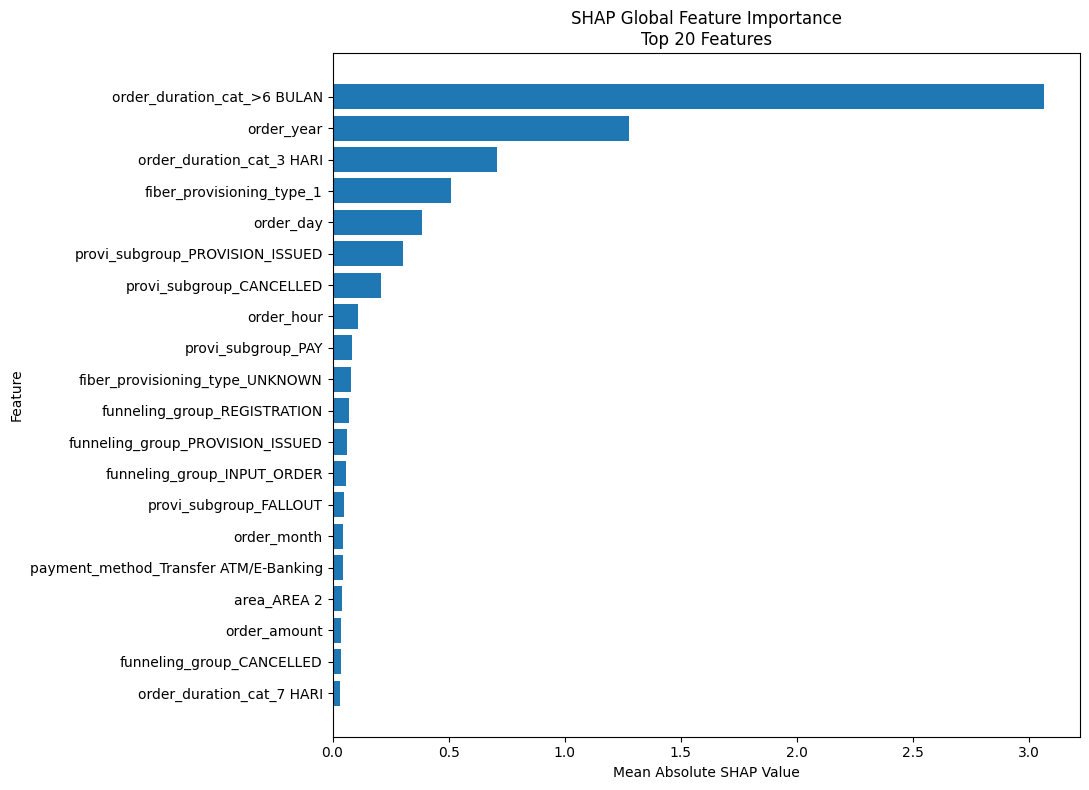


16. SHAP SUMMARY PLOT


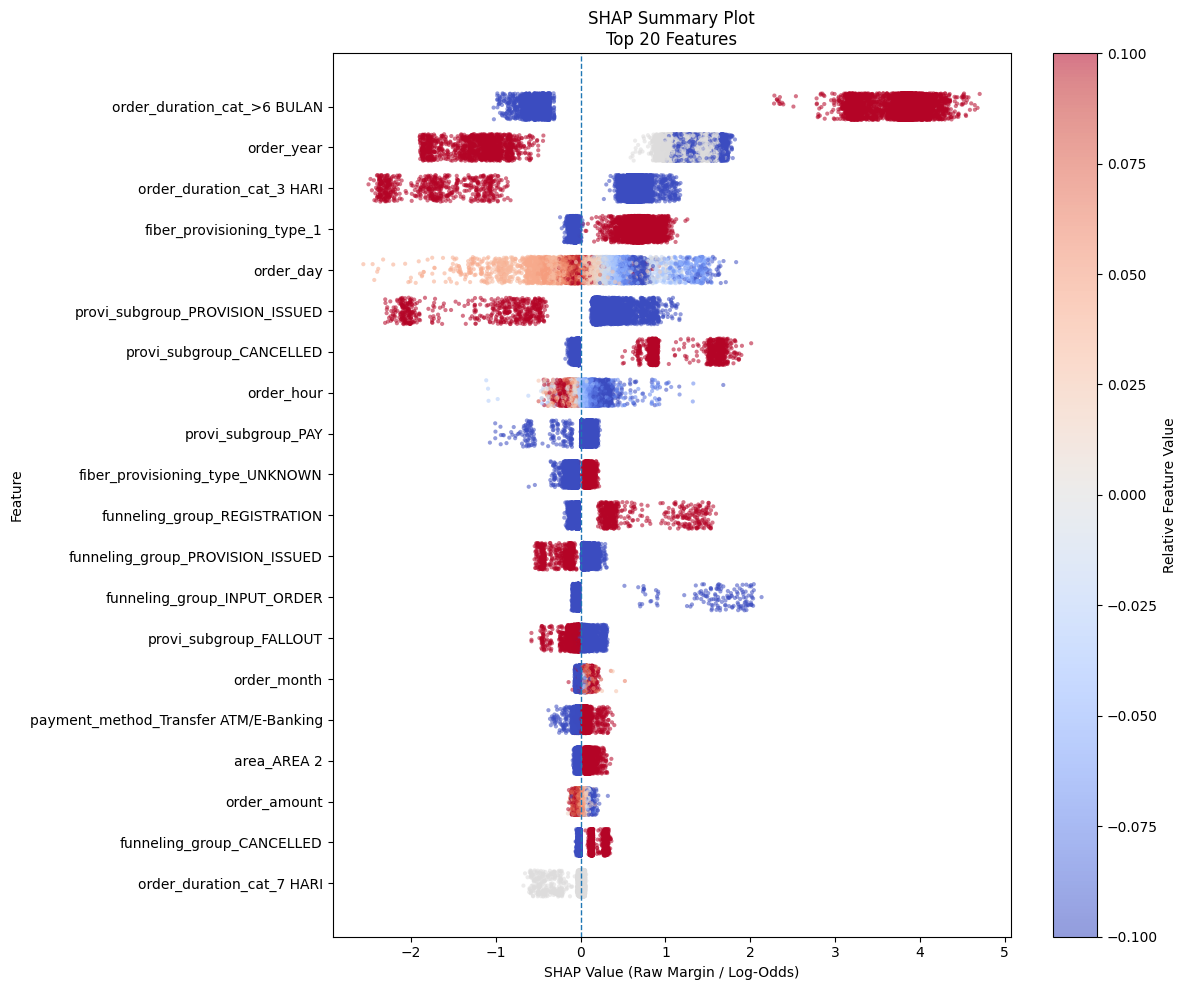

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/SHAP_SUMMARY_PLOT_FINAL.png

17. SHAP DEPENDENCE PLOTS


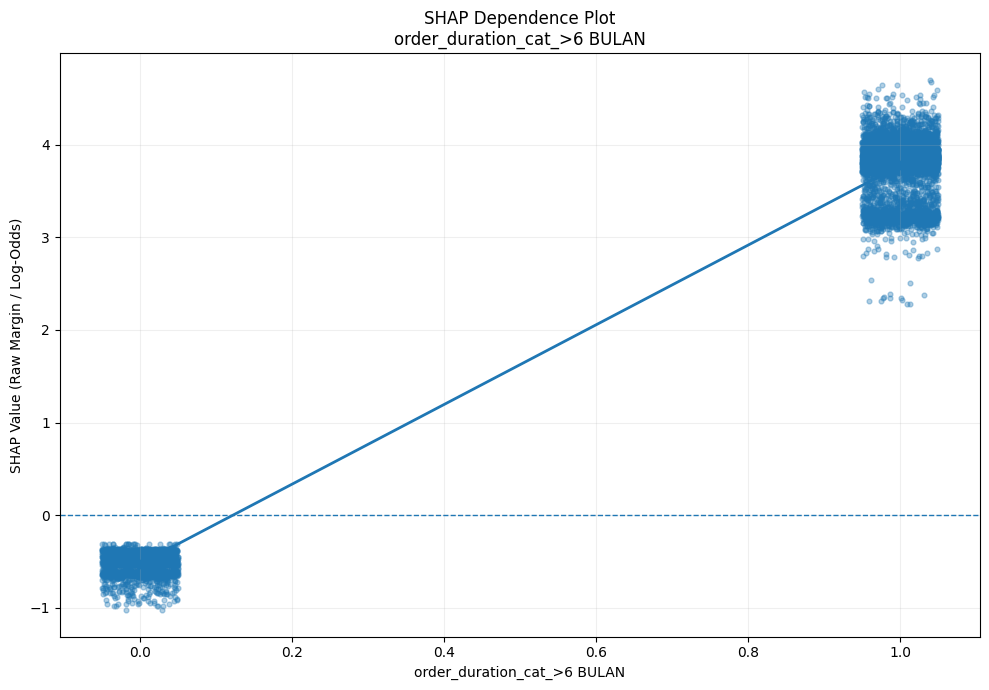

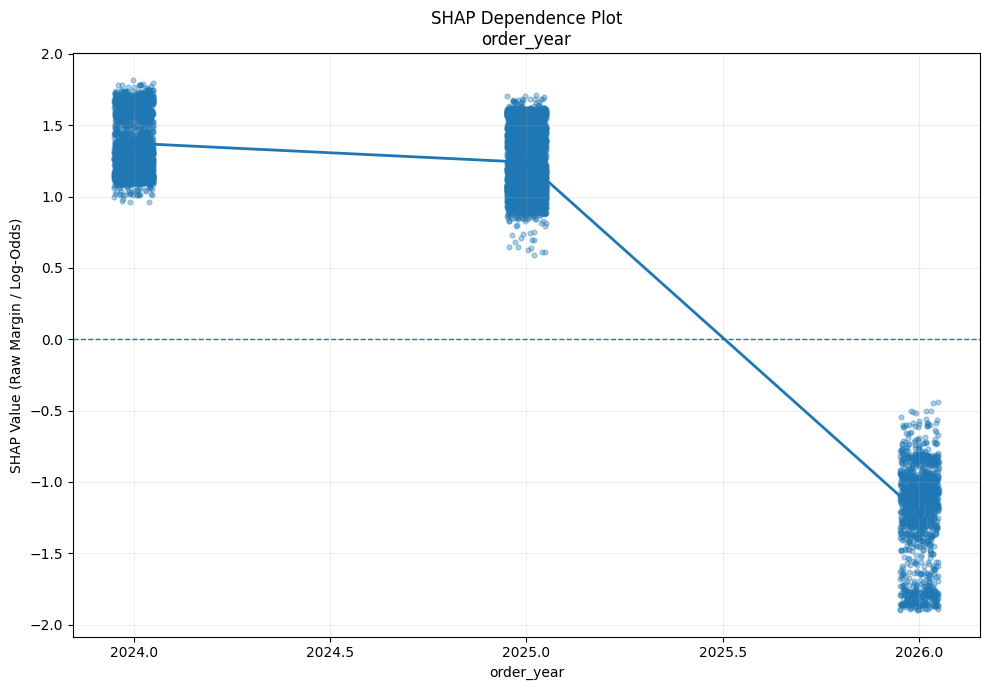

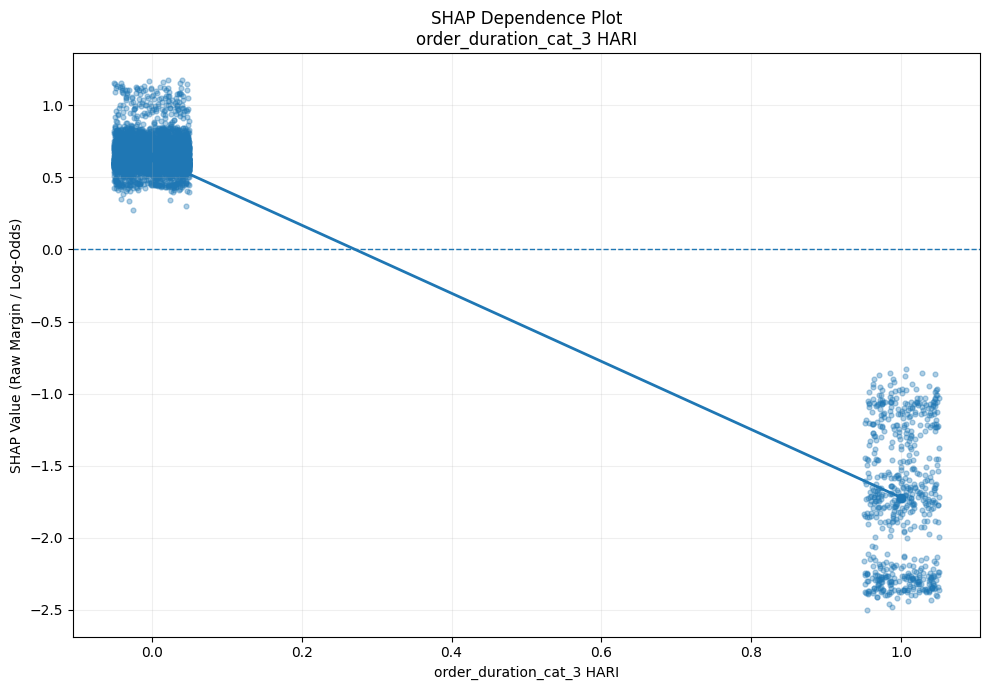

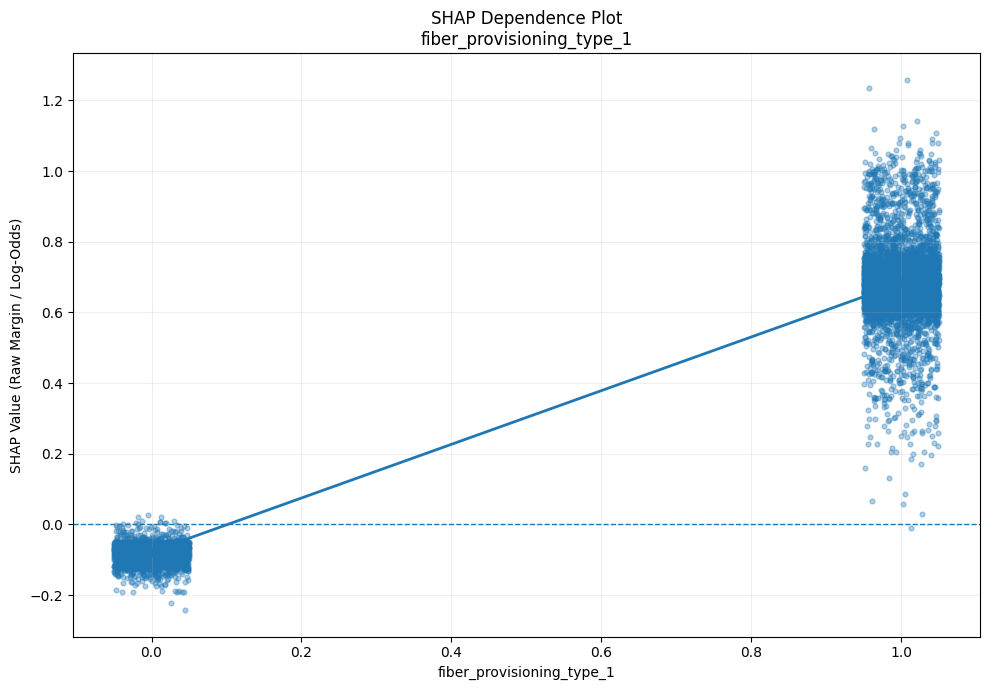

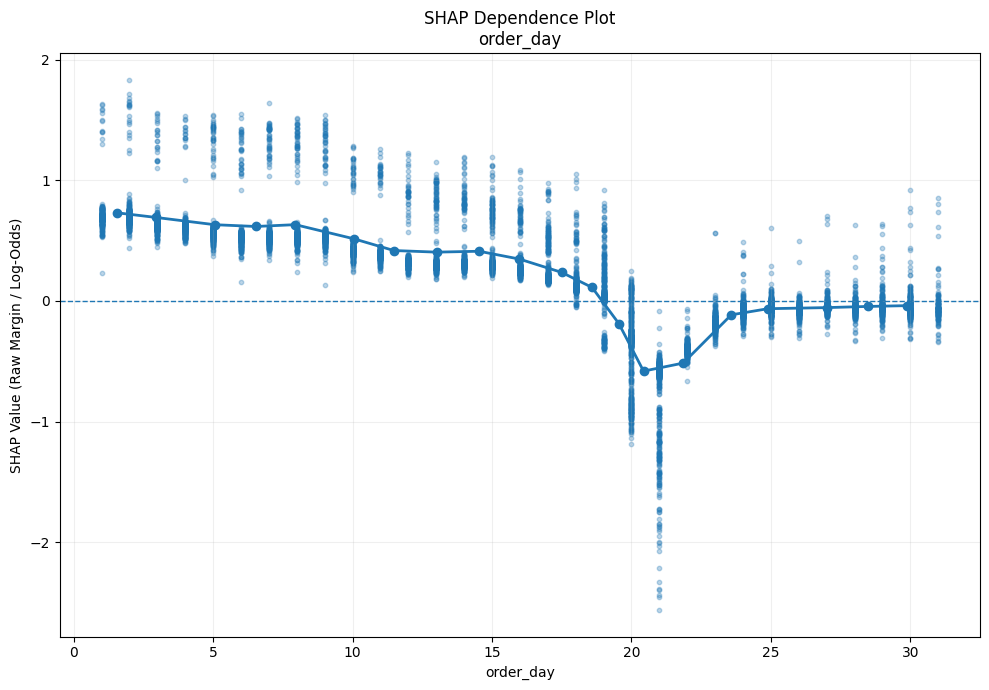

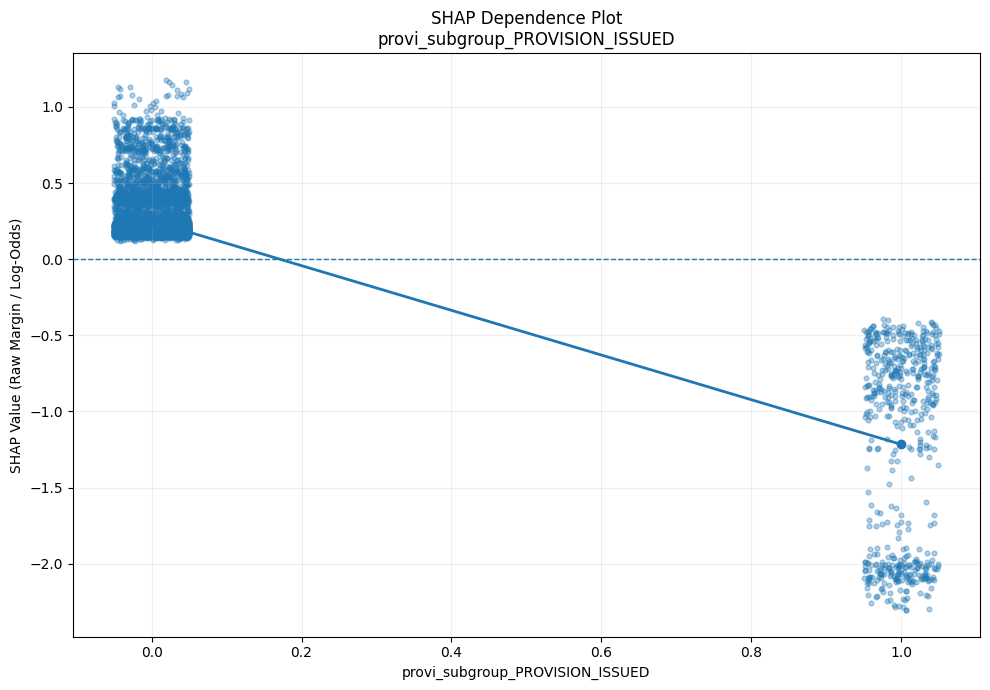

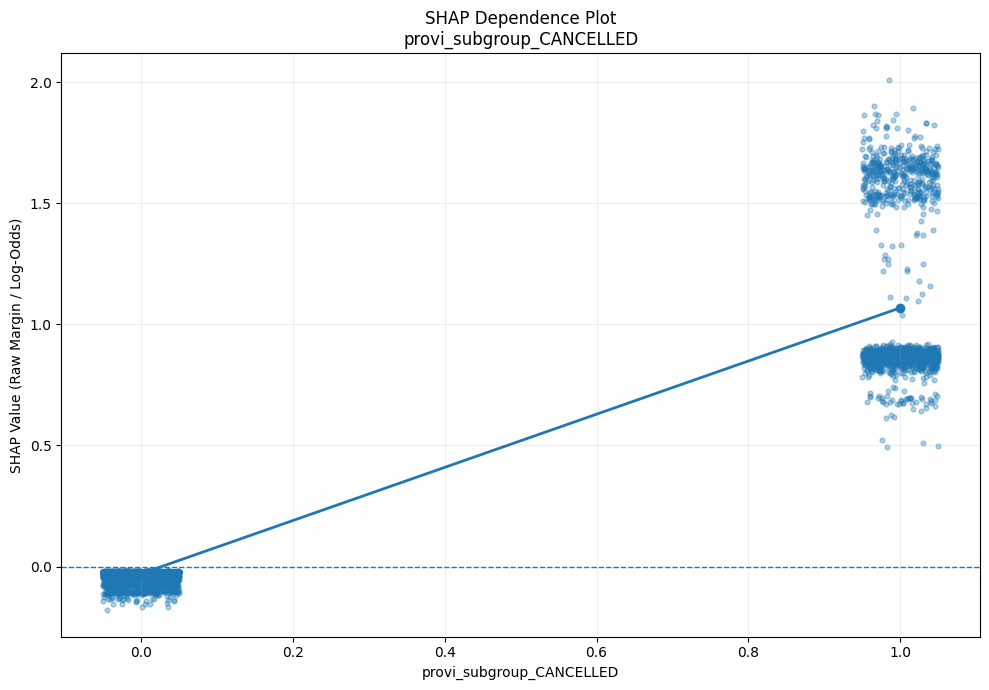

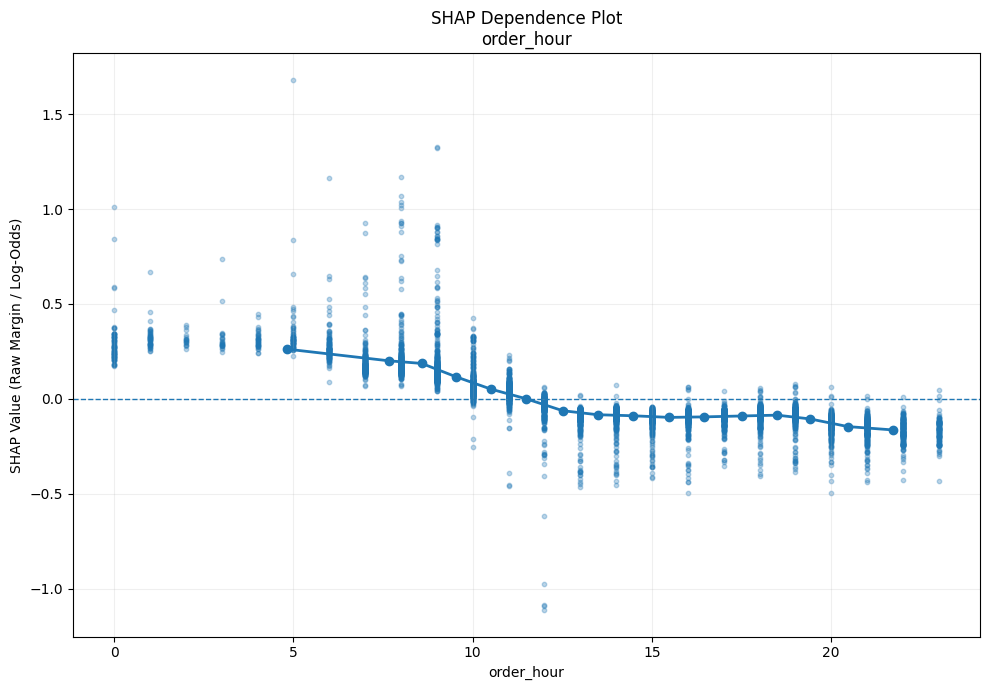

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/SHAP_DEPENDENCE_SUMMARY_FINAL.csv

18. ORIGINAL VARIABLE IMPORTANCE
      original_variable  n_encoded_features  mean_abs_shap  mean_shap                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [25]:
# ============================================================
# MASTER CELL — FINAL MANUAL TREE-SHAP
# TANPA ANALISIS REGION
# ============================================================
#
# CELL INI MENGERJAKAN:
#
# A. LOAD MODEL TREE DARI LOG
# B. RECONSTRUCT 199 TREES
# C. MANUAL TREE-SHAP FROM SCRATCH
# D. SAVE manual_treeshap_values.npy
# E. EXPECTED VALUE
# F. ADDITIVITY CHECK
# G. GLOBAL FEATURE IMPORTANCE
# H. SHAP SUMMARY PLOT
# I. SHAP DEPENDENCE PLOTS
# J. ORIGINAL VARIABLE IMPORTANCE
# K. IMPORTANT ORDER DURATION CHECK
# L. FINAL REPORT
#
# TIDAK ADA ANALISIS REGION DI CELL INI.
#
# ============================================================


import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ============================================================
# 0. CONFIGURATION
# ============================================================

BASE_DIR = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_2_8_MODELING"
)

RAW_DATA_PATH = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_FEATURE_ENGINEERING_FINAL.csv"
)

NODE_DETAILS_PATH = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_XGBOOST_HISTOGRAM_DETAILED/"
    "logs/node_details.csv"
)

SPLIT_DETAILS_PATH = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_XGBOOST_HISTOGRAM_DETAILED/"
    "logs/split_details.csv"
)

SHAP_DIR = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_SHAP_MANUAL_TREESHAP"
)

X_TEST_PATH = os.path.join(
    BASE_DIR,
    "X_test.npz"
)

Y_TRAIN_PATH = os.path.join(
    BASE_DIR,
    "y_train.csv"
)

FEATURE_NAMES_PATH = os.path.join(
    BASE_DIR,
    "feature_names_after_encoding.csv"
)

SHAP_VALUES_PATH = os.path.join(
    SHAP_DIR,
    "manual_treeshap_values.npy"
)

LEARNING_RATE = 0.05

N_TREES = 199

RANDOM_STATE = 42

TOP_N_GLOBAL = 20

TOP_N_DEPENDENCE = 8

MAX_PLOT_OBS = 10000

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


print("=" * 80)
print("MASTER CELL — MANUAL TREE-SHAP")
print("WITHOUT REGIONAL ANALYSIS")
print("=" * 80)

print()
print("TreeSHAP akan dihitung ulang dari scratch.")
print("manual_treeshap_values.npy akan ditimpa setelah")
print("perhitungan SHAP selesai dan additivity diverifikasi.")
print()


# ============================================================
# 1. LOAD X_TEST
# ============================================================

print("=" * 80)
print("1. LOAD X_TEST")
print("=" * 80)

X_test_sparse = sp.load_npz(
    X_TEST_PATH
).tocsr()

N_TEST, N_FEATURES = X_test_sparse.shape

print(
    f"X_test : {X_test_sparse.shape}"
)

if N_TEST != 32348:

    print(
        "WARNING: jumlah test observation "
        f"={N_TEST}, bukan 32,348."
    )

if N_FEATURES != 651:

    print(
        "WARNING: jumlah fitur "
        f"={N_FEATURES}, bukan 651."
    )


# ============================================================
# 2. LOAD FEATURE NAMES
# ============================================================

print()
print("=" * 80)
print("2. LOAD FEATURE NAMES")
print("=" * 80)

feature_df = pd.read_csv(
    FEATURE_NAMES_PATH
)

candidate_feature_columns = [
    "feature",
    "feature_name",
    "features",
    "Feature",
    "Feature Name",
    "feature_names"
]

feature_col = None

for col in candidate_feature_columns:

    if col in feature_df.columns:

        feature_col = col
        break

if feature_col is None:

    feature_col = feature_df.columns[0]

feature_names = (
    feature_df[feature_col]
    .astype(str)
    .tolist()
)

if len(feature_names) != N_FEATURES:

    raise ValueError(
        f"Feature name count = "
        f"{len(feature_names)}, "
        f"tetapi X_test memiliki "
        f"{N_FEATURES} features."
    )

print(
    f"Feature names : {len(feature_names)}"
)


# ============================================================
# 3. LOAD NODE DETAILS
# ============================================================

print()
print("=" * 80)
print("3. LOAD NODE DETAILS")
print("=" * 80)

node_raw = pd.read_csv(
    NODE_DETAILS_PATH
)

node_raw.columns = [
    str(c).strip().lower()
    for c in node_raw.columns
]

required_node_columns = [
    "tree",
    "node",
    "depth",
    "samples",
    "g",
    "h",
    "leaf_weight"
]

missing_node_cols = [
    c
    for c in required_node_columns
    if c not in node_raw.columns
]

if missing_node_cols:

    raise ValueError(
        "Kolom node_details tidak ditemukan: "
        + str(missing_node_cols)
    )

node_raw = node_raw[
    required_node_columns
].copy()

node_raw["tree"] = pd.to_numeric(
    node_raw["tree"],
    errors="coerce"
)

node_raw["node"] = pd.to_numeric(
    node_raw["node"],
    errors="coerce"
)

node_raw["depth"] = pd.to_numeric(
    node_raw["depth"],
    errors="coerce"
)

node_raw["samples"] = pd.to_numeric(
    node_raw["samples"],
    errors="coerce"
)

node_raw["g"] = pd.to_numeric(
    node_raw["g"],
    errors="coerce"
)

node_raw["h"] = pd.to_numeric(
    node_raw["h"],
    errors="coerce"
)

node_raw["leaf_weight"] = pd.to_numeric(
    node_raw["leaf_weight"],
    errors="coerce"
)

node_raw = node_raw.dropna(
    subset=[
        "tree",
        "node",
        "depth",
        "g",
        "h"
    ]
)

node_raw["tree"] = (
    node_raw["tree"]
    .astype(int)
)

node_raw["node"] = (
    node_raw["node"]
    .astype(int)
)

node_raw["depth"] = (
    node_raw["depth"]
    .astype(int)
)

node_raw = node_raw.sort_values(
    ["tree", "node"]
).reset_index(drop=True)

print(
    f"Rows : {len(node_raw):,}"
)

print(
    "Trees:",
    node_raw["tree"].nunique()
)


# ============================================================
# 4. LOAD SELECTED SPLITS
# ============================================================

print()
print("=" * 80)
print("4. LOAD SELECTED SPLITS")
print("=" * 80)

split_header = pd.read_csv(
    SPLIT_DETAILS_PATH,
    nrows=0
)

split_columns_raw = [
    str(c).strip()
    for c in split_header.columns
]

split_lower_map = {
    str(c).strip().lower(): c
    for c in split_columns_raw
}

required_split_lower = [
    "tree",
    "depth",
    "feature_idx",
    "feature_name",
    "threshold",
    "missing_direction",
    "g_parent",
    "h_parent",
    "g_left",
    "h_left",
    "g_right",
    "h_right"
]

missing_split = [
    c
    for c in required_split_lower
    if c not in split_lower_map
]

if missing_split:

    raise ValueError(
        "Kolom split_details tidak ditemukan: "
        + str(missing_split)
    )

usecols_actual = [
    split_lower_map[c]
    for c in required_split_lower
]

selected_split_chunks = []

for chunk in pd.read_csv(
    SPLIT_DETAILS_PATH,
    usecols=usecols_actual,
    chunksize=250000
):

    chunk.columns = [
        str(c).strip().lower()
        for c in chunk.columns
    ]

    chunk["tree"] = pd.to_numeric(
        chunk["tree"],
        errors="coerce"
    )

    chunk = chunk[
        chunk["tree"].between(
            1,
            N_TREES
        )
    ]

    if len(chunk) > 0:

        selected_split_chunks.append(
            chunk
        )

selected_splits = pd.concat(
    selected_split_chunks,
    ignore_index=True
)

for col in [
    "depth",
    "feature_idx"
]:

    selected_splits[col] = pd.to_numeric(
        selected_splits[col],
        errors="coerce"
    )

for col in [
    "threshold",
    "g_parent",
    "h_parent",
    "g_left",
    "h_left",
    "g_right",
    "h_right"
]:

    selected_splits[col] = pd.to_numeric(
        selected_splits[col],
        errors="coerce"
    )

selected_splits["tree"] = (
    selected_splits["tree"]
    .astype(int)
)

selected_splits = selected_splits.dropna(
    subset=[
        "depth",
        "feature_idx",
        "threshold",
        "g_parent",
        "h_parent",
        "g_left",
        "h_left",
        "g_right",
        "h_right"
    ]
).copy()

selected_splits["depth"] = (
    selected_splits["depth"]
    .astype(int)
)

selected_splits["feature_idx"] = (
    selected_splits["feature_idx"]
    .astype(int)
)

selected_splits = selected_splits.sort_values(
    ["tree", "depth"]
).reset_index(drop=True)

print(
    "Selected splits:",
    f"{len(selected_splits):,}"
)

print(
    "Trees:",
    selected_splits["tree"].nunique()
)


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def close_float(a, b):

    if not np.isfinite(a) or not np.isfinite(b):

        return False

    return np.isclose(
        float(a),
        float(b),
        rtol=2e-5,
        atol=1e-7
    )


def get_right_child(
    depths,
    left_index,
    parent_depth
):

    for j in range(
        left_index + 1,
        len(depths)
    ):

        if depths[j] == parent_depth + 1:

            return j

        if depths[j] <= parent_depth:

            return -1

    return -1


# ============================================================
# 6. RECONSTRUCT TREE STRUCTURE
# ============================================================

print()
print("=" * 80)
print("6. RECONSTRUCTING TREES")
print("=" * 80)

trees = []

mapping_failures = []

for tree_id in range(
    1,
    N_TREES + 1
):

    tree_nodes = node_raw[
        node_raw["tree"] == tree_id
    ].sort_values(
        "node"
    ).reset_index(drop=True)

    if len(tree_nodes) == 0:

        raise ValueError(
            f"Tree {tree_id} tidak ditemukan."
        )

    m = len(tree_nodes)

    depths = tree_nodes[
        "depth"
    ].to_numpy(
        dtype=np.int32
    )

    g_values = tree_nodes[
        "g"
    ].to_numpy(
        dtype=np.float64
    )

    h_values = tree_nodes[
        "h"
    ].to_numpy(
        dtype=np.float64
    )

    leaf_weights = tree_nodes[
        "leaf_weight"
    ].fillna(0.0).to_numpy(
        dtype=np.float64
    )

    children_left = np.full(
        m,
        -1,
        dtype=np.int32
    )

    children_right = np.full(
        m,
        -1,
        dtype=np.int32
    )

    children_default = np.full(
        m,
        -1,
        dtype=np.int32
    )

    features = np.full(
        m,
        -1,
        dtype=np.int32
    )

    thresholds = np.zeros(
        m,
        dtype=np.float64
    )

    split_rows = selected_splits[
        selected_splits["tree"]
        == tree_id
    ].copy()

    used_split_indices = set()

    for local_node in range(m):

        node_depth = depths[
            local_node
        ]

        node_g = g_values[
            local_node
        ]

        node_h = h_values[
            local_node
        ]

        candidates = split_rows[
            split_rows["depth"]
            == node_depth
        ]

        if len(candidates) == 0:

            continue

        candidates = candidates[
            candidates.apply(
                lambda r:
                    close_float(
                        r["g_parent"],
                        node_g
                    )
                    and
                    close_float(
                        r["h_parent"],
                        node_h
                    ),
                axis=1
            )
        ]

        if len(candidates) == 0:

            continue

        if local_node + 1 >= m:

            continue

        left_child = local_node + 1

        right_child = get_right_child(
            depths,
            left_child,
            node_depth
        )

        if right_child < 0:

            continue

        left_g = g_values[
            left_child
        ]

        left_h = h_values[
            left_child
        ]

        right_g = g_values[
            right_child
        ]

        right_h = h_values[
            right_child
        ]

        matched = None

        for idx, row in candidates.iterrows():

            same_order = (
                close_float(
                    row["g_left"],
                    left_g
                )
                and
                close_float(
                    row["h_left"],
                    left_h
                )
                and
                close_float(
                    row["g_right"],
                    right_g
                )
                and
                close_float(
                    row["h_right"],
                    right_h
                )
            )

            reverse_order = (
                close_float(
                    row["g_left"],
                    right_g
                )
                and
                close_float(
                    row["h_left"],
                    right_h
                )
                and
                close_float(
                    row["g_right"],
                    left_g
                )
                and
                close_float(
                    row["h_right"],
                    left_h
                )
            )

            if same_order or reverse_order:

                matched = (
                    idx,
                    row,
                    same_order
                )

                break

        if matched is None:

            continue

        split_idx, row, same_order = matched

        if split_idx in used_split_indices:

            continue

        used_split_indices.add(
            split_idx
        )

        children_left[
            local_node
        ] = left_child

        children_right[
            local_node
        ] = right_child

        feature_idx = int(
            row["feature_idx"]
        )

        if (
            feature_idx < 0
            or feature_idx >= N_FEATURES
        ):

            raise ValueError(
                f"Invalid feature_idx "
                f"{feature_idx} "
                f"di tree {tree_id}, "
                f"node {local_node}"
            )

        features[
            local_node
        ] = feature_idx

        thresholds[
            local_node
        ] = float(
            row["threshold"]
        )

        missing_direction = str(
            row["missing_direction"]
        ).strip().upper()

        if missing_direction == "LEFT":

            children_default[
                local_node
            ] = left_child

        elif missing_direction == "RIGHT":

            children_default[
                local_node
            ] = right_child

        else:

            raise ValueError(
                f"Missing direction tidak dikenal: "
                f"{missing_direction}"
            )

    internal_nodes = np.where(
        children_right >= 0
    )[0]

    mapped_splits = len(
        internal_nodes
    )

    expected_splits = len(
        split_rows
    )

    if mapped_splits != expected_splits:

        mapping_failures.append({
            "tree": tree_id,
            "expected_splits": expected_splits,
            "mapped_splits": mapped_splits
        })

    trees.append({
        "tree": tree_id,
        "children_left": children_left,
        "children_right": children_right,
        "children_default": children_default,
        "features": features,
        "thresholds": thresholds,
        "leaf_weights": leaf_weights,
        "cover": h_values,
        "depth": int(
            np.max(depths)
        )
    })

    if (
        tree_id == 1
        or tree_id % 20 == 0
        or tree_id == N_TREES
    ):

        print(
            f"Tree {tree_id:03d}/{N_TREES}: "
            f"nodes={m}, "
            f"depth={np.max(depths)}, "
            f"splits={mapped_splits}/{expected_splits}"
        )


print()

if mapping_failures:

    print(
        "WARNING: terdapat tree dengan "
        "mapping split tidak sempurna:"
    )

    for x in mapping_failures[:20]:

        print(x)

    raise ValueError(
        "Reconstruction tree gagal. "
        "Jangan lanjut ke SHAP."
    )

else:

    print(
        "✓ Semua 199 tree berhasil "
        "direconstruct."
    )


# ============================================================
# 7. APPLY LEARNING RATE
# ============================================================

print()
print("=" * 80)
print("7. APPLY LEARNING RATE")
print("=" * 80)

for tree in trees:

    tree["values"] = (
        tree["leaf_weights"]
        * LEARNING_RATE
    )

print(
    f"Learning rate = {LEARNING_RATE}"
)


# ============================================================
# 8. BASE MARGIN
# ============================================================

print()
print("=" * 80)
print("8. CALCULATE BASE MARGIN")
print("=" * 80)

y_train_df = pd.read_csv(
    Y_TRAIN_PATH
)

if y_train_df.shape[1] == 1:

    y_train = (
        y_train_df.iloc[:, 0]
        .to_numpy()
    )

else:

    numeric_candidates = []

    for c in y_train_df.columns:

        vals = pd.to_numeric(
            y_train_df[c],
            errors="coerce"
        )

        if vals.notna().all():

            numeric_candidates.append(c)

    if len(numeric_candidates) == 0:

        raise ValueError(
            "Tidak menemukan y_train."
        )

    y_train = (
        y_train_df[
            numeric_candidates[0]
        ]
        .to_numpy()
    )

y_train = pd.to_numeric(
    y_train,
    errors="coerce"
).astype(int)

train_positive_rate = np.mean(
    y_train
)

train_positive_rate = np.clip(
    train_positive_rate,
    1e-15,
    1 - 1e-15
)

base_margin = np.log(
    train_positive_rate
    /
    (1 - train_positive_rate)
)

print(
    f"Train positive rate : "
    f"{train_positive_rate:.12f}"
)

print(
    f"Base margin         : "
    f"{base_margin:.12f}"
)


# ============================================================
# 9. MANUAL TREE-SHAP ENGINE
# ============================================================

print()
print("=" * 80)
print("9. PREPARE MANUAL TREE-SHAP ENGINE")
print("=" * 80)

from numba import njit


@njit(cache=False)
def extend_path(
    feature_indexes,
    zero_fractions,
    one_fractions,
    pweights,
    unique_depth,
    zero_fraction,
    one_fraction,
    feature_index
):

    feature_indexes[
        unique_depth
    ] = feature_index

    zero_fractions[
        unique_depth
    ] = zero_fraction

    one_fractions[
        unique_depth
    ] = one_fraction

    if unique_depth == 0:

        pweights[
            unique_depth
        ] = 1.0

    else:

        pweights[
            unique_depth
        ] = 0.0

    for i in range(
        unique_depth - 1,
        -1,
        -1
    ):

        pweights[
            i + 1
        ] += (
            one_fraction
            * pweights[i]
            * (i + 1.0)
            / (unique_depth + 1.0)
        )

        pweights[
            i
        ] = (
            zero_fraction
            * pweights[i]
            * (unique_depth - i)
            / (unique_depth + 1.0)
        )


@njit(cache=False)
def unwind_path(
    feature_indexes,
    zero_fractions,
    one_fractions,
    pweights,
    unique_depth,
    path_index
):

    one_fraction = one_fractions[
        path_index
    ]

    zero_fraction = zero_fractions[
        path_index
    ]

    next_one_portion = pweights[
        unique_depth
    ]

    for i in range(
        unique_depth - 1,
        -1,
        -1
    ):

        if one_fraction != 0.0:

            tmp = pweights[i]

            pweights[i] = (
                next_one_portion
                * (unique_depth + 1.0)
                /
                (
                    (i + 1.0)
                    * one_fraction
                )
            )

            next_one_portion = (
                tmp
                - pweights[i]
                * zero_fraction
                * (
                    (unique_depth - i)
                    /
                    (unique_depth + 1.0)
                )
            )

        else:

            denom = (
                zero_fraction
                * (unique_depth - i)
            )

            if denom != 0.0:

                pweights[i] = (
                    pweights[i]
                    * (unique_depth + 1.0)
                    / denom
                )

    for i in range(
        path_index,
        unique_depth
    ):

        feature_indexes[i] = (
            feature_indexes[i + 1]
        )

        zero_fractions[i] = (
            zero_fractions[i + 1]
        )

        one_fractions[i] = (
            one_fractions[i + 1]
        )


@njit(cache=False)
def unwound_path_sum(
    feature_indexes,
    zero_fractions,
    one_fractions,
    pweights,
    unique_depth,
    path_index
):

    one_fraction = one_fractions[
        path_index
    ]

    zero_fraction = zero_fractions[
        path_index
    ]

    next_one_portion = pweights[
        unique_depth
    ]

    total = 0.0

    for i in range(
        unique_depth - 1,
        -1,
        -1
    ):

        if one_fraction != 0.0:

            tmp = (
                next_one_portion
                * (unique_depth + 1.0)
                /
                (
                    (i + 1.0)
                    * one_fraction
                )
            )

            total += tmp

            next_one_portion = (
                pweights[i]
                - tmp
                * zero_fraction
                * (
                    (unique_depth - i)
                    /
                    (unique_depth + 1.0)
                )
            )

        else:

            denom = zero_fraction

            if denom != 0.0:

                total += (
                    pweights[i]
                    / denom
                ) / (
                    (unique_depth - i)
                    /
                    (unique_depth + 1.0)
                )

    return total


@njit(cache=False)
def tree_shap_recursive(
    children_left,
    children_right,
    children_default,
    features,
    thresholds,
    values,
    cover,
    x,
    x_missing,
    phi,
    node_index,
    unique_depth,
    parent_feature_indexes,
    parent_zero_fractions,
    parent_one_fractions,
    parent_pweights,
    parent_zero_fraction,
    parent_one_fraction,
    parent_feature_index
):

    feature_indexes = (
        parent_feature_indexes[
            unique_depth + 1:
        ]
    )

    zero_fractions = (
        parent_zero_fractions[
            unique_depth + 1:
        ]
    )

    one_fractions = (
        parent_one_fractions[
            unique_depth + 1:
        ]
    )

    pweights = (
        parent_pweights[
            unique_depth + 1:
        ]
    )

    for i in range(
        unique_depth + 1
    ):

        feature_indexes[i] = (
            parent_feature_indexes[i]
        )

        zero_fractions[i] = (
            parent_zero_fractions[i]
        )

        one_fractions[i] = (
            parent_one_fractions[i]
        )

        pweights[i] = (
            parent_pweights[i]
        )

    extend_path(
        feature_indexes,
        zero_fractions,
        one_fractions,
        pweights,
        unique_depth,
        parent_zero_fraction,
        parent_one_fraction,
        parent_feature_index
    )

    split_index = features[
        node_index
    ]

    if children_right[
        node_index
    ] == -1:

        for i in range(
            1,
            unique_depth + 1
        ):

            w = unwound_path_sum(
                feature_indexes,
                zero_fractions,
                one_fractions,
                pweights,
                unique_depth,
                i
            )

            phi[
                feature_indexes[i]
            ] += (
                w
                * (
                    one_fractions[i]
                    - zero_fractions[i]
                )
                * values[node_index]
            )

        return

    cleft = children_left[
        node_index
    ]

    cright = children_right[
        node_index
    ]

    if x_missing[
        split_index
    ]:

        hot_index = children_default[
            node_index
        ]

    elif (
        x[split_index]
        <= thresholds[node_index]
    ):

        hot_index = cleft

    else:

        hot_index = cright

    if hot_index == cleft:

        cold_index = cright

    else:

        cold_index = cleft

    parent_cover = cover[
        node_index
    ]

    if parent_cover <= 0.0:

        return

    hot_zero_fraction = (
        cover[hot_index]
        / parent_cover
    )

    cold_zero_fraction = (
        cover[cold_index]
        / parent_cover
    )

    incoming_zero_fraction = 1.0

    incoming_one_fraction = 1.0

    path_index = 0

    while path_index <= unique_depth:

        if (
            feature_indexes[path_index]
            == split_index
        ):

            break

        path_index += 1

    if path_index != (
        unique_depth + 1
    ):

        incoming_zero_fraction = (
            zero_fractions[path_index]
        )

        incoming_one_fraction = (
            one_fractions[path_index]
        )

        unwind_path(
            feature_indexes,
            zero_fractions,
            one_fractions,
            pweights,
            unique_depth,
            path_index
        )

        unique_depth -= 1

    tree_shap_recursive(
        children_left,
        children_right,
        children_default,
        features,
        thresholds,
        values,
        cover,
        x,
        x_missing,
        phi,
        hot_index,
        unique_depth + 1,
        feature_indexes,
        zero_fractions,
        one_fractions,
        pweights,
        hot_zero_fraction
        * incoming_zero_fraction,
        incoming_one_fraction,
        split_index
    )

    tree_shap_recursive(
        children_left,
        children_right,
        children_default,
        features,
        thresholds,
        values,
        cover,
        x,
        x_missing,
        phi,
        cold_index,
        unique_depth + 1,
        feature_indexes,
        zero_fractions,
        one_fractions,
        pweights,
        cold_zero_fraction
        * incoming_zero_fraction,
        0.0,
        split_index
    )


@njit(cache=False)
def explain_one_tree(
    x,
    children_left,
    children_right,
    children_default,
    features,
    thresholds,
    values,
    cover,
    max_depth,
    n_features
):

    phi = np.zeros(
        n_features,
        dtype=np.float64
    )

    x_missing = np.zeros(
        n_features,
        dtype=np.bool_
    )

    for j in range(
        n_features
    ):

        x_missing[j] = np.isnan(
            x[j]
        )

    path_size = (
        (max_depth + 2)
        * (max_depth + 3)
    ) // 2

    feature_indexes = np.zeros(
        path_size,
        dtype=np.int32
    )

    zero_fractions = np.zeros(
        path_size,
        dtype=np.float64
    )

    one_fractions = np.zeros(
        path_size,
        dtype=np.float64
    )

    pweights = np.zeros(
        path_size,
        dtype=np.float64
    )

    tree_shap_recursive(
        children_left,
        children_right,
        children_default,
        features,
        thresholds,
        values,
        cover,
        x,
        x_missing,
        phi,
        0,
        0,
        feature_indexes,
        zero_fractions,
        one_fractions,
        pweights,
        1.0,
        1.0,
        -1
    )

    return phi


# ============================================================
# 10. NUMBA COMPILE TEST
# ============================================================

print()
print("=" * 80)
print("10. NUMBA COMPILE TEST")
print("=" * 80)

compile_start = time.time()

test_x = (
    X_test_sparse[0]
    .toarray()
    .ravel()
    .astype(np.float64)
)

_ = explain_one_tree(
    test_x,
    trees[0]["children_left"],
    trees[0]["children_right"],
    trees[0]["children_default"],
    trees[0]["features"],
    trees[0]["thresholds"],
    trees[0]["values"],
    trees[0]["cover"],
    trees[0]["depth"],
    N_FEATURES
)

print(
    f"Compile/test time : "
    f"{time.time() - compile_start:.2f}s"
)


# ============================================================
# 11. TREE EXPECTED VALUES
# ============================================================

print()
print("=" * 80)
print("11. TREE EXPECTED VALUES")
print("=" * 80)

tree_expected_values = []

for tree in trees:

    children_left = tree[
        "children_left"
    ]

    children_right = tree[
        "children_right"
    ]

    values = tree[
        "values"
    ]

    cover = tree[
        "cover"
    ]

    def recursive_expectation(
        node
    ):

        if children_right[
            node
        ] == -1:

            return values[
                node
            ]

        left = recursive_expectation(
            children_left[node]
        )

        right = recursive_expectation(
            children_right[node]
        )

        left_cover = cover[
            children_left[node]
        ]

        right_cover = cover[
            children_right[node]
        ]

        total_cover = (
            left_cover
            + right_cover
        )

        if total_cover <= 0:

            return 0.0

        return (
            left_cover * left
            + right_cover * right
        ) / total_cover

    expected_tree = (
        recursive_expectation(0)
    )

    tree_expected_values.append(
        expected_tree
    )

tree_expected_values = np.asarray(
    tree_expected_values,
    dtype=np.float64
)

tree_contribution = np.sum(
    tree_expected_values
)

expected_value = (
    base_margin
    + tree_contribution
)

print(
    f"Base margin       : "
    f"{base_margin:.10f}"
)

print(
    f"Tree contribution : "
    f"{tree_contribution:.10f}"
)

print(
    f"Expected value    : "
    f"{expected_value:.10f}"
)


# ============================================================
# 12. CALCULATE MANUAL TREE-SHAP
# ============================================================

print()
print("=" * 80)
print("12. MANUAL TREE-SHAP — ACTUAL CALCULATION")
print("=" * 80)

print(
    f"Observations : {N_TEST:,}"
)

print(
    f"Features     : {N_FEATURES:,}"
)

print(
    f"Trees        : {N_TREES}"
)

print(
    "Output       : raw margin / log-odds"
)

print(
    "Algorithm    : Manual TreeSHAP "
    "path-dependent"
)

print()

print(
    "Converting X_test to dense float64..."
)

dense_start = time.time()

X_test_dense = (
    X_test_sparse
    .toarray()
    .astype(np.float64)
)

print(
    f"Dense conversion : "
    f"{time.time() - dense_start:.2f}s"
)

manual_shap = np.zeros(
    (
        N_TEST,
        N_FEATURES
    ),
    dtype=np.float64
)

shap_start = time.time()

for tree_no, tree in enumerate(
    trees,
    start=1
):

    tree_start = time.time()

    for i in range(
        N_TEST
    ):

        manual_shap[i] += (
            explain_one_tree(
                X_test_dense[i],
                tree["children_left"],
                tree["children_right"],
                tree["children_default"],
                tree["features"],
                tree["thresholds"],
                tree["values"],
                tree["cover"],
                tree["depth"],
                N_FEATURES
            )
        )

    elapsed = (
        time.time()
        - shap_start
    )

    percent = (
        tree_no
        / N_TREES
        * 100
    )

    eta = (
        elapsed
        / tree_no
        * (
            N_TREES
            - tree_no
        )
    )

    print(
        f"[{tree_no:03d}/{N_TREES}] "
        f"{percent:6.2f}% | "
        f"tree={time.time()-tree_start:.2f}s | "
        f"elapsed={elapsed/60:.2f}m | "
        f"ETA={eta/60:.2f}m"
    )

total_shap_time = (
    time.time()
    - shap_start
)

print()

print(
    f"TOTAL TREE-SHAP TIME : "
    f"{total_shap_time:.2f}s "
    f"({total_shap_time/60:.2f} menit)"
)


# ============================================================
# 13. SAVE SHAP
# ============================================================

print()
print("=" * 80)
print("13. SAVE TREE-SHAP VALUES")
print("=" * 80)

np.save(
    SHAP_VALUES_PATH,
    manual_shap
)

print(
    "Saved:",
    SHAP_VALUES_PATH
)

print(
    "Shape:",
    manual_shap.shape
)


# ============================================================
# 14. MANUAL MODEL PREDICTION
# ============================================================

def predict_tree_python(
    x,
    tree
):

    node = 0

    while (
        tree["children_right"][node]
        != -1
    ):

        feature = tree[
            "features"
        ][node]

        value = x[
            feature
        ]

        if np.isnan(value):

            node = tree[
                "children_default"
            ][node]

        elif (
            value
            <= tree["thresholds"][node]
        ):

            node = tree[
                "children_left"
            ][node]

        else:

            node = tree[
                "children_right"
            ][node]

    return tree[
        "values"
    ][node]


# ============================================================
# 15. ADDITIVITY CHECK
# ============================================================

print()
print("=" * 80)
print("14. ADDITIVITY CHECK")
print("=" * 80)

CHECK_N = min(
    100,
    N_TEST
)

errors = []

for i in range(
    CHECK_N
):

    x = X_test_dense[i]

    manual_model_margin = (
        base_margin
    )

    for tree in trees:

        manual_model_margin += (
            predict_tree_python(
                x,
                tree
            )
        )

    shap_reconstructed_margin = (
        expected_value
        + np.sum(
            manual_shap[i]
        )
    )

    errors.append(
        abs(
            manual_model_margin
            - shap_reconstructed_margin
        )
    )

errors = np.asarray(
    errors
)

max_error = float(
    np.max(errors)
)

mean_error = float(
    np.mean(errors)
)

print(
    f"Checked observations : "
    f"{CHECK_N}"
)

print(
    f"Max |error|          : "
    f"{max_error:.12e}"
)

print(
    f"Mean |error|         : "
    f"{mean_error:.12e}"
)

ADDITIVITY_TOL = 1e-5

if max_error <= ADDITIVITY_TOL:

    print()
    print(
        "✓ ADDITIVITY PASS"
    )

else:

    print()
    print(
        "✗ ADDITIVITY FAIL"
    )

    raise ValueError(
        "Additivity check gagal. "
        "JANGAN gunakan hasil SHAP "
        "sebelum reconstruction diperbaiki."
    )


# ============================================================
# 16. GLOBAL FEATURE IMPORTANCE
# ============================================================

print()
print("=" * 80)
print("15. GLOBAL FEATURE IMPORTANCE")
print("=" * 80)

mean_abs_shap = np.mean(
    np.abs(manual_shap),
    axis=0
)

mean_shap = np.mean(
    manual_shap,
    axis=0
)

global_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap,
    "mean_shap": mean_shap
})

global_df = global_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(
    drop=True
)

global_df["rank"] = (
    np.arange(
        1,
        len(global_df) + 1
    )
)

global_df["direction"] = np.where(
    global_df["mean_shap"] > 0,
    "Mendorong STUCK",
    np.where(
        global_df["mean_shap"] < 0,
        "Mendorong NOT-STUCK",
        "Netral"
    )
)

global_path = os.path.join(
    SHAP_DIR,
    "SHAP_GLOBAL_IMPORTANCE_FINAL.csv"
)

global_df.to_csv(
    global_path,
    index=False
)

print(
    global_df.head(
        TOP_N_GLOBAL
    ).to_string(
        index=False
    )
)

print()
print(
    "Saved:",
    global_path
)


# ============================================================
# 17. GLOBAL IMPORTANCE PLOT
# ============================================================

plot_df = (
    global_df
    .head(TOP_N_GLOBAL)
    .sort_values(
        "mean_abs_shap"
    )
)

plt.figure(
    figsize=(11, 8)
)

plt.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "SHAP Global Feature Importance\n"
    "Top 20 Features"
)

plt.tight_layout()

global_plot_path = os.path.join(
    SHAP_DIR,
    "SHAP_GLOBAL_FEATURE_IMPORTANCE_FINAL.png"
)

plt.savefig(
    global_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 18. SHAP SUMMARY PLOT
# ============================================================

print()
print("=" * 80)
print("16. SHAP SUMMARY PLOT")
print("=" * 80)

summary_features = (
    global_df
    .head(TOP_N_GLOBAL)
    ["feature"]
    .tolist()
)

summary_indices = [
    feature_names.index(f)
    for f in summary_features
]

rng = np.random.default_rng(
    RANDOM_STATE
)

if N_TEST > MAX_PLOT_OBS:

    plot_idx = rng.choice(
        N_TEST,
        size=MAX_PLOT_OBS,
        replace=False
    )

else:

    plot_idx = np.arange(
        N_TEST
    )

X_summary = X_test_dense[
    np.ix_(
        plot_idx,
        summary_indices
    )
]

SHAP_summary = manual_shap[
    np.ix_(
        plot_idx,
        summary_indices
    )
]

fig, ax = plt.subplots(
    figsize=(12, 10)
)

for row in range(
    len(summary_features)
):

    x = SHAP_summary[
        :, row
    ]

    feature_value = X_summary[
        :, row
    ]

    jitter = (
        rng.random(
            len(x)
        )
        - 0.5
    ) * 0.65

    y = (
        len(summary_features)
        - 1
        - row
        + jitter
    )

    finite = feature_value[
        np.isfinite(feature_value)
    ]

    if (
        len(finite) > 0
        and
        np.nanmax(finite)
        !=
        np.nanmin(finite)
    ):

        low = np.nanpercentile(
            finite,
            5
        )

        high = np.nanpercentile(
            finite,
            95
        )

        normalized = (
            np.clip(
                feature_value,
                low,
                high
            )
            - low
        ) / max(
            high - low,
            1e-12
        )

    else:

        normalized = np.full(
            len(feature_value),
            0.5
        )

    normalized = np.nan_to_num(
        normalized,
        nan=0.5
    )

    sc = ax.scatter(
        x,
        y,
        c=normalized,
        cmap="coolwarm",
        s=9,
        alpha=0.55,
        linewidths=0
    )

ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_yticks(
    np.arange(
        len(summary_features)
    )
)

ax.set_yticklabels(
    summary_features[::-1]
)

ax.set_xlabel(
    "SHAP Value "
    "(Raw Margin / Log-Odds)"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "SHAP Summary Plot\n"
    "Top 20 Features"
)

cbar = plt.colorbar(
    sc,
    ax=ax
)

cbar.set_label(
    "Relative Feature Value"
)

plt.tight_layout()

summary_path = os.path.join(
    SHAP_DIR,
    "SHAP_SUMMARY_PLOT_FINAL.png"
)

plt.savefig(
    summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "Saved:",
    summary_path
)


# ============================================================
# 19. DEPENDENCE PLOTS
# ============================================================

print()
print("=" * 80)
print("17. SHAP DEPENDENCE PLOTS")
print("=" * 80)


def safe_filename(text):

    return re.sub(
        r"[^A-Za-z0-9_\-]+",
        "_",
        str(text)
    )[:100]


dependence_records = []

for rank, feature_name in enumerate(
    summary_features[:TOP_N_DEPENDENCE],
    start=1
):

    feature_idx = (
        feature_names.index(
            feature_name
        )
    )

    x = X_test_dense[
        plot_idx,
        feature_idx
    ]

    y = manual_shap[
        plot_idx,
        feature_idx
    ]

    valid_xy = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[valid_xy]
    y = y[valid_xy]

    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    unique_values = np.unique(
        x
    )

    if len(unique_values) <= 10:

        jitter = (
            rng.random(
                len(x)
            )
            - 0.5
        ) * 0.10

        ax.scatter(
            x + jitter,
            y,
            s=12,
            alpha=0.35
        )

        category_x = []
        category_y = []

        for value in unique_values:

            mask = (
                x == value
            )

            if np.sum(mask) >= 1:

                category_x.append(
                    value
                )

                category_y.append(
                    np.mean(
                        y[mask]
                    )
                )

        if len(category_x) > 1:

            ax.plot(
                category_x,
                category_y,
                marker="o",
                linewidth=2
            )

    else:

        ax.scatter(
            x,
            y,
            s=10,
            alpha=0.30
        )

        try:

            bins = np.quantile(
                x,
                np.linspace(
                    0,
                    1,
                    21
                )
            )

            bins = np.unique(
                bins
            )

            centers = []
            means = []

            for lo, hi in zip(
                bins[:-1],
                bins[1:]
            ):

                mask = (
                    (x >= lo)
                    &
                    (x <= hi)
                )

                if np.sum(mask) >= 5:

                    centers.append(
                        np.mean(
                            x[mask]
                        )
                    )

                    means.append(
                        np.mean(
                            y[mask]
                        )
                    )

            if len(centers) > 1:

                ax.plot(
                    centers,
                    means,
                    marker="o",
                    linewidth=2
                )

        except Exception:

            pass

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        feature_name
    )

    ax.set_ylabel(
        "SHAP Value "
        "(Raw Margin / Log-Odds)"
    )

    ax.set_title(
        "SHAP Dependence Plot\n"
        + feature_name
    )

    ax.grid(
        alpha=0.20
    )

    plt.tight_layout()

    dependence_path = os.path.join(
        SHAP_DIR,
        "SHAP_DEPENDENCE_"
        + safe_filename(feature_name)
        + "_FINAL.png"
    )

    plt.savefig(
        dependence_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    row = global_df[
        global_df["feature"]
        == feature_name
    ].iloc[0]

    dependence_records.append({
        "global_rank": rank,
        "feature": feature_name,
        "mean_abs_shap":
            row["mean_abs_shap"],
        "mean_shap":
            row["mean_shap"],
        "direction":
            row["direction"],
        "plot_path":
            dependence_path
    })

dependence_df = pd.DataFrame(
    dependence_records
)

dependence_csv = os.path.join(
    SHAP_DIR,
    "SHAP_DEPENDENCE_SUMMARY_FINAL.csv"
)

dependence_df.to_csv(
    dependence_csv,
    index=False
)

print(
    "Saved:",
    dependence_csv
)


# ============================================================
# 20. ORIGINAL VARIABLE MAPPING
# ============================================================

print()
print("=" * 80)
print("18. ORIGINAL VARIABLE IMPORTANCE")
print("=" * 80)

raw_header = pd.read_csv(
    RAW_DATA_PATH,
    sep="~",
    nrows=0
)

raw_columns = [
    str(c)
    for c in raw_header.columns
]


def map_original_variable(feature):

    if feature in raw_columns:

        return feature

    candidates = []

    for col in raw_columns:

        if feature.startswith(
            str(col) + "_"
        ):

            candidates.append(
                col
            )

    if candidates:

        return max(
            candidates,
            key=len
        )

    engineered = [
        "order_year",
        "order_month",
        "order_day",
        "order_dayofweek",
        "order_hour",
        "order_is_weekend"
    ]

    if feature in engineered:

        return feature

    return feature


original_variable = [
    map_original_variable(f)
    for f in feature_names
]

mapping_df = pd.DataFrame({
    "feature": feature_names,
    "original_variable": original_variable
})

mapping_path = os.path.join(
    SHAP_DIR,
    "SHAP_FEATURE_ORIGINAL_VARIABLE_MAPPING_FINAL.csv"
)

mapping_df.to_csv(
    mapping_path,
    index=False
)

original_records = []

for original in sorted(
    mapping_df[
        "original_variable"
    ].unique()
):

    idx = np.where(
        np.asarray(
            original_variable
        ) == original
    )[0]

    if len(idx) == 0:

        continue

    combined = np.sum(
        manual_shap[:, idx],
        axis=1
    )

    original_records.append({
        "original_variable":
            original,
        "n_encoded_features":
            len(idx),
        "mean_abs_shap":
            np.mean(
                np.abs(
                    combined
                )
            ),
        "mean_shap":
            np.mean(
                combined
            ),
        "encoded_features":
            " | ".join(
                feature_names[i]
                for i in idx
            )
    })

original_global_df = pd.DataFrame(
    original_records
)

original_global_df = (
    original_global_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

original_global_df["rank"] = (
    np.arange(
        1,
        len(original_global_df) + 1
    )
)

original_global_df["direction"] = np.where(
    original_global_df["mean_shap"] > 0,
    "Mendorong STUCK",
    np.where(
        original_global_df["mean_shap"] < 0,
        "Mendorong NOT-STUCK",
        "Netral"
    )
)

original_global_path = os.path.join(
    SHAP_DIR,
    "SHAP_GLOBAL_ORIGINAL_VARIABLE_FINAL.csv"
)

original_global_df.to_csv(
    original_global_path,
    index=False
)

print(
    original_global_df.head(
        20
    ).to_string(
        index=False
    )
)

print()
print(
    "Saved:",
    original_global_path
)


# ============================================================
# 21. IMPORTANT ORDER DURATION CHECK
# ============================================================

print()
print("=" * 80)
print("19. IMPORTANT CHECK — ORDER DURATION")
print("=" * 80)

duration_features = [
    f
    for f in feature_names
    if f.startswith(
        "order_duration_cat"
    )
]

duration_df = global_df[
    global_df["feature"].isin(
        duration_features
    )
]

print(
    duration_df.to_string(
        index=False
    )
)

duration_warning_path = os.path.join(
    SHAP_DIR,
    "IMPORTANT_CHECK_ORDER_DURATION_CAT.txt"
)

with open(
    duration_warning_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "IMPORTANT METHODOLOGICAL CHECK\n"
    )

    f.write(
        "================================\n\n"
    )

    f.write(
        "order_duration_cat termasuk faktor "
        "dengan kontribusi SHAP terbesar.\n\n"
    )

    f.write(
        "Sebelum digunakan sebagai kesimpulan "
        "faktor dominan dalam skripsi, pastikan "
        "variabel ini tersedia pada saat order "
        "diprediksi dan bukan informasi yang "
        "baru diketahui setelah outcome STUCK.\n\n"
    )

    f.write(
        "SHAP menunjukkan kontribusi fitur terhadap "
        "prediksi model, bukan hubungan kausal.\n"
    )


# ============================================================
# 22. FINAL REPORT
# ============================================================

print()
print("=" * 80)
print("20. GENERATE FINAL REPORT")
print("=" * 80)

report_path = os.path.join(
    SHAP_DIR,
    "SHAP_FINAL_ANALYSIS_REPORT.txt"
)

best = global_df.iloc[0]

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "FINAL MANUAL TREE-SHAP ANALYSIS REPORT\n"
    )

    f.write(
        "========================================\n\n"
    )

    f.write(
        f"Test observations : {N_TEST:,}\n"
    )

    f.write(
        f"Features          : {N_FEATURES:,}\n"
    )

    f.write(
        f"Trees             : {N_TREES}\n"
    )

    f.write(
        f"Learning rate     : {LEARNING_RATE}\n"
    )

    f.write(
        "Algorithm         : Manual TreeSHAP "
        "path-dependent\n"
    )

    f.write(
        "Output            : Raw margin / log-odds\n\n"
    )

    f.write(
        "ADDITIVITY CHECK\n"
    )

    f.write(
        "----------------\n"
    )

    f.write(
        f"Max error  : {max_error:.12e}\n"
    )

    f.write(
        f"Mean error : {mean_error:.12e}\n"
    )

    f.write(
        "Status     : PASS\n\n"
    )

    f.write(
        "TOP 20 GLOBAL FACTORS\n"
    )

    f.write(
        "---------------------\n"
    )

    for _, row in global_df.head(
        TOP_N_GLOBAL
    ).iterrows():

        f.write(
            f"{int(row['rank'])}. "
            f"{row['feature']} | "
            f"MeanAbsSHAP="
            f"{row['mean_abs_shap']:.6f} | "
            f"MeanSHAP="
            f"{row['mean_shap']:.6f} | "
            f"{row['direction']}\n"
        )

    f.write(
        "\nFAKTOR GLOBAL PALING DOMINAN\n"
    )

    f.write(
        "----------------------------\n"
    )

    f.write(
        f"{best['feature']} "
        f"(Mean Absolute SHAP = "
        f"{best['mean_abs_shap']:.6f}, "
        f"Mean SHAP = "
        f"{best['mean_shap']:.6f})\n"
    )

    f.write(
        "\nMETHODOLOGICAL NOTE\n"
    )

    f.write(
        "-------------------\n"
    )

    f.write(
        "SHAP digunakan untuk menjelaskan "
        "kontribusi fitur terhadap keputusan "
        "model, bukan untuk membuktikan hubungan "
        "kausal.\n"
    )

    f.write(
        "order_duration_cat perlu diverifikasi "
        "terhadap kemungkinan post-outcome "
        "information/data leakage.\n"
    )


# ============================================================
# 23. FINAL OUTPUT
# ============================================================

print()
print("=" * 80)
print("FINAL OUTPUT")
print("=" * 80)

important_files = [
    "manual_treeshap_values.npy",
    "SHAP_GLOBAL_IMPORTANCE_FINAL.csv",
    "SHAP_GLOBAL_FEATURE_IMPORTANCE_FINAL.png",
    "SHAP_SUMMARY_PLOT_FINAL.png",
    "SHAP_GLOBAL_ORIGINAL_VARIABLE_FINAL.csv",
    "SHAP_FEATURE_ORIGINAL_VARIABLE_MAPPING_FINAL.csv",
    "SHAP_DEPENDENCE_SUMMARY_FINAL.csv",
    "IMPORTANT_CHECK_ORDER_DURATION_CAT.txt",
    "SHAP_FINAL_ANALYSIS_REPORT.txt"
]

for filename in important_files:

    path = os.path.join(
        SHAP_DIR,
        filename
    )

    if os.path.exists(path):

        if filename.endswith(
            ".npy"
        ):

            size = (
                os.path.getsize(path)
                / (1024 ** 2)
            )

            print(
                f"✓ {filename} "
                f"({size:.2f} MB)"
            )

        else:

            print(
                f"✓ {filename}"
            )

dependence_files = [
    f
    for f in os.listdir(
        SHAP_DIR
    )
    if (
        f.startswith(
            "SHAP_DEPENDENCE_"
        )
        and f.endswith(
            ".png"
        )
    )
]

print()
print(
    f"✓ Dependence plots: "
    f"{len(dependence_files)}"
)

print()
print("=" * 80)
print("TOP 20 GLOBAL FACTORS")
print("=" * 80)

print(
    global_df.head(
        TOP_N_GLOBAL
    ).to_string(
        index=False
    )
)

print()
print("=" * 80)
print("FINAL STATUS")
print("=" * 80)

print(
    "✓ Tree reconstruction PASS"
)

print(
    "✓ Manual TreeSHAP calculated"
)

print(
    "✓ manual_treeshap_values.npy saved"
)

print(
    f"✓ Additivity max error = "
    f"{max_error:.12e}"
)

print(
    "✓ ADDITIVITY PASS"
)

print(
    "✓ Global Feature Importance"
)

print(
    "✓ Summary Plot"
)

print(
    "✓ Dependence Plot"
)

print(
    "✓ Original Variable Importance"
)

print()
print(
    "✓ TIDAK ADA ANALISIS REGION "
    "DI MASTER CELL"
)

print()
print(
    "OUTPUT DIRECTORY:"
)

print(
    SHAP_DIR
)

print()
print("=" * 80)
print("MASTER CELL SELESAI")
print("=" * 80)

In [26]:
# ============================================================
# CELL 2 — FINAL REGIONAL SHAP ANALYSIS
# TOP 5 REGION BERDASARKAN JUMLAH STUCK
# ============================================================
#
# CELL INI TIDAK:
#   - reconstruct tree
#   - menghitung TreeSHAP ulang
#   - mengubah manual_treeshap_values.npy
#
# CELL INI HANYA:
#   1. Membaca manual_treeshap_values.npy
#   2. Mapping region ke test set
#   3. Menghitung jumlah STUCK tiap region
#   4. Sorting descending berdasarkan STUCK
#   5. Mengambil TOP 5
#   6. Menghitung SHAP importance per TOP 5 region
#   7. Mengagregasi encoded feature ke original variable
#
# ============================================================


import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split


# ============================================================
# 0. CONFIGURATION
# ============================================================

BASE_DIR = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_2_8_MODELING"
)

RAW_DATA_PATH = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_FEATURE_ENGINEERING_FINAL.csv"
)

SHAP_DIR = (
    "/content/drive/MyDrive/SKRIPSI/"
    "FMC_SHAP_MANUAL_TREESHAP"
)

Y_TEST_PATH = os.path.join(
    BASE_DIR,
    "y_test.csv"
)

FEATURE_NAMES_PATH = os.path.join(
    BASE_DIR,
    "feature_names_after_encoding.csv"
)

SHAP_VALUES_PATH = os.path.join(
    SHAP_DIR,
    "manual_treeshap_values.npy"
)

RANDOM_STATE = 42

TOP_N_REGION = 5

TOP_N_FACTOR = 10

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


# ============================================================
# 1. LOAD MANUAL TREE-SHAP
# ============================================================

print("=" * 80)
print("1. LOAD MANUAL TREE-SHAP")
print("=" * 80)

if not os.path.exists(
    SHAP_VALUES_PATH
):

    raise FileNotFoundError(
        "manual_treeshap_values.npy tidak ditemukan.\n"
        "Jalankan MASTER CELL terlebih dahulu."
    )

manual_shap = np.load(
    SHAP_VALUES_PATH,
    mmap_mode="r"
)

N_TEST, N_FEATURES = (
    manual_shap.shape
)

print(
    f"SHAP shape : "
    f"{manual_shap.shape}"
)


# ============================================================
# 2. LOAD FEATURE NAMES
# ============================================================

print()
print("=" * 80)
print("2. LOAD FEATURE NAMES")
print("=" * 80)

feature_df = pd.read_csv(
    FEATURE_NAMES_PATH
)

candidate_feature_columns = [
    "feature",
    "feature_name",
    "features",
    "Feature",
    "Feature Name",
    "feature_names"
]

feature_col = None

for col in candidate_feature_columns:

    if col in feature_df.columns:

        feature_col = col
        break

if feature_col is None:

    feature_col = (
        feature_df.columns[0]
    )

feature_names = (
    feature_df[feature_col]
    .astype(str)
    .tolist()
)

if len(feature_names) != N_FEATURES:

    raise ValueError(
        f"Feature names = "
        f"{len(feature_names)}, "
        f"SHAP features = "
        f"{N_FEATURES}"
    )

print(
    f"Feature names : "
    f"{len(feature_names)}"
)


# ============================================================
# 3. LOAD Y_TEST
# ============================================================

print()
print("=" * 80)
print("3. LOAD Y_TEST")
print("=" * 80)

y_test_df = pd.read_csv(
    Y_TEST_PATH
)

if y_test_df.shape[1] == 1:

    y_test = (
        pd.to_numeric(
            y_test_df.iloc[:, 0],
            errors="coerce"
        )
        .astype(int)
        .to_numpy()
    )

else:

    numeric_candidates = []

    for col in y_test_df.columns:

        values = pd.to_numeric(
            y_test_df[col],
            errors="coerce"
        )

        if values.notna().all():

            numeric_candidates.append(
                col
            )

    if len(numeric_candidates) == 0:

        raise ValueError(
            "Kolom y_test tidak ditemukan."
        )

    y_test = (
        y_test_df[
            numeric_candidates[0]
        ]
        .astype(int)
        .to_numpy()
    )

if len(y_test) != N_TEST:

    raise ValueError(
        f"y_test = {len(y_test)}, "
        f"SHAP = {N_TEST}"
    )

print(
    f"y_test : "
    f"{len(y_test):,}"
)


# ============================================================
# 4. LOAD REGION DAN TARGET RAW DATA
# ============================================================

print()
print("=" * 80)
print("4. LOAD REGION DATA")
print("=" * 80)

raw = pd.read_csv(
    RAW_DATA_PATH,
    sep="~",
    usecols=lambda c: (
        str(c).strip().lower()
        in [
            "region",
            "label",
            "target",
            "status",
            "stuck"
        ]
    )
)

region_col = None

for col in raw.columns:

    if (
        str(col)
        .strip()
        .lower()
        == "region"
    ):

        region_col = col
        break

if region_col is None:

    raise ValueError(
        "Kolom region tidak ditemukan."
    )

target_col = None

for col in raw.columns:

    if (
        str(col)
        .strip()
        .lower()
        in [
            "label",
            "target",
            "status",
            "stuck"
        ]
    ):

        target_col = col
        break

if target_col is None:

    raise ValueError(
        "Kolom target tidak ditemukan."
    )


# ============================================================
# 5. NORMALISASI TARGET
# ============================================================

raw_y = pd.to_numeric(
    raw[target_col],
    errors="coerce"
)

if raw_y.isna().all():

    raw_y = (
        raw[target_col]
        .astype(str)
        .str.upper()
        .map({
            "STUCK": 1,
            "NOT-STUCK": 0,
            "NOT_STUCK": 0
        })
    )

raw_y = pd.to_numeric(
    raw_y,
    errors="coerce"
)

valid = raw_y.notna()

raw_y = (
    raw_y[valid]
    .astype(int)
    .to_numpy()
)

raw_region = (
    raw.loc[
        valid,
        region_col
    ]
    .astype(str)
    .to_numpy()
)

print(
    f"Raw observations : "
    f"{len(raw_y):,}"
)


# ============================================================
# 6. RECONSTRUCT EXACT 80/10/10 SPLIT
# ============================================================

print()
print("=" * 80)
print("5. RECONSTRUCT EXACT TEST SPLIT")
print("=" * 80)

all_indices = np.arange(
    len(raw_y)
)

train_idx, temp_idx = (
    train_test_split(
        all_indices,
        test_size=0.20,
        stratify=raw_y,
        random_state=RANDOM_STATE
    )
)

valid_idx, test_idx = (
    train_test_split(
        temp_idx,
        test_size=0.50,
        stratify=raw_y[temp_idx],
        random_state=RANDOM_STATE
    )
)

region_test = raw_region[
    test_idx
]

y_test_reconstructed = raw_y[
    test_idx
]

print(
    f"Train : "
    f"{len(train_idx):,}"
)

print(
    f"Valid : "
    f"{len(valid_idx):,}"
)

print(
    f"Test  : "
    f"{len(test_idx):,}"
)


# ============================================================
# 7. VALIDASI
# ============================================================

print()
print("=" * 80)
print("6. VALIDATION")
print("=" * 80)

if not np.array_equal(
    y_test_reconstructed,
    y_test
):

    raise ValueError(
        "y_test hasil reconstruction "
        "TIDAK SAMA dengan y_test.csv."
    )

if len(region_test) != N_TEST:

    raise ValueError(
        f"Region test = "
        f"{len(region_test)}, "
        f"SHAP = {N_TEST}"
    )

print(
    "✓ y_test MATCH"
)

print(
    "✓ Region length MATCH"
)


# ============================================================
# 8. RANKING REGION BERDASARKAN JUMLAH STUCK
# ============================================================

print()
print("=" * 80)
print("7. RANKING REGION BERDASARKAN JUMLAH STUCK")
print("=" * 80)

region_summary = pd.DataFrame({
    "region": region_test,
    "y": y_test
})

region_summary = (
    region_summary
    .groupby("region")
    .agg(
        total_observations=("y", "size"),
        stuck_count=("y", "sum")
    )
    .reset_index()
)

region_summary["not_stuck_count"] = (
    region_summary["total_observations"]
    -
    region_summary["stuck_count"]
)

region_summary["stuck_rate"] = (
    region_summary["stuck_count"]
    /
    region_summary["total_observations"]
    * 100
)

region_summary = (
    region_summary
    .sort_values(
        [
            "stuck_count",
            "total_observations"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

region_summary["rank_stuck"] = (
    np.arange(
        1,
        len(region_summary) + 1
    )
)

print(
    region_summary.to_string(
        index=False
    )
)


# ============================================================
# 9. TOP 5 REGION
# ============================================================

print()
print("=" * 80)
print("8. TOP 5 REGION")
print("=" * 80)

top5_df = (
    region_summary
    .head(TOP_N_REGION)
    .copy()
)

top5_regions = (
    top5_df[
        "region"
    ]
    .tolist()
)

print(
    top5_df[
        [
            "rank_stuck",
            "region",
            "total_observations",
            "stuck_count",
            "not_stuck_count",
            "stuck_rate"
        ]
    ].to_string(
        index=False
    )
)

top5_path = os.path.join(
    SHAP_DIR,
    "TOP_5_REGION_BY_STUCK_FINAL.csv"
)

top5_df.to_csv(
    top5_path,
    index=False
)

print()
print(
    "Saved:",
    top5_path
)


# ============================================================
# 10. REGIONAL SHAP — TOP 5
# ============================================================
#
# Region dipilih berdasarkan JUMLAH STUCK.
#
# Setelah region terpilih, SHAP dihitung dari
# SEMUA observasi test dalam region tersebut.
#
# ============================================================

print()
print("=" * 80)
print("9. REGIONAL SHAP — TOP 5 REGION")
print("=" * 80)

regional_records = []

for region_rank, region in enumerate(
    top5_regions,
    start=1
):

    print()
    print(
        "-" * 80
    )

    print(
        f"REGION #{region_rank}: "
        f"{region}"
    )

    print(
        "-" * 80
    )

    mask = (
        region_test == region
    )

    indices = np.where(
        mask
    )[0]

    region_shap = (
        manual_shap[
            indices
        ]
    )

    n_obs = len(indices)

    n_stuck = int(
        np.sum(
            y_test[
                indices
            ] == 1
        )
    )

    n_not_stuck = int(
        np.sum(
            y_test[
                indices
            ] == 0
        )
    )

    mean_abs = np.mean(
        np.abs(
            region_shap
        ),
        axis=0
    )

    mean_shap = np.mean(
        region_shap,
        axis=0
    )

    temp = pd.DataFrame({
        "region_rank_by_stuck":
            region_rank,
        "region":
            region,
        "feature":
            feature_names,
        "mean_abs_shap":
            mean_abs,
        "mean_shap":
            mean_shap,
        "n_observations":
            n_obs,
        "stuck_count":
            n_stuck,
        "not_stuck_count":
            n_not_stuck
    })

    temp = (
        temp
        .sort_values(
            "mean_abs_shap",
            ascending=False
        )
        .reset_index(drop=True)
    )

    temp["rank"] = (
        np.arange(
            1,
            len(temp) + 1
        )
    )

    temp["direction"] = np.where(
        temp["mean_shap"] > 0,
        "Mendorong STUCK",
        np.where(
            temp["mean_shap"] < 0,
            "Mendorong NOT-STUCK",
            "Netral"
        )
    )

    regional_records.append(
        temp
    )

    print(
        temp.head(
            TOP_N_FACTOR
        )[
            [
                "rank",
                "feature",
                "mean_abs_shap",
                "mean_shap",
                "direction",
                "n_observations",
                "stuck_count",
                "not_stuck_count"
            ]
        ].to_string(
            index=False
        )
    )


regional_df = pd.concat(
    regional_records,
    ignore_index=True
)

regional_path = os.path.join(
    SHAP_DIR,
    "SHAP_IMPORTANCE_TOP_5_REGION_FINAL.csv"
)

regional_df.to_csv(
    regional_path,
    index=False
)

print()
print(
    "Saved:",
    regional_path
)


# ============================================================
# 11. TOP 10 FACTORS PER REGION
# ============================================================

print()
print("=" * 80)
print("10. TOP 10 FACTORS PER TOP 5 REGION")
print("=" * 80)

top10_df = (
    regional_df[
        regional_df["rank"]
        <= TOP_N_FACTOR
    ]
    .copy()
)

top10_path = os.path.join(
    SHAP_DIR,
    "DOMINANT_FACTORS_TOP_5_REGION_FINAL.csv"
)

top10_df.to_csv(
    top10_path,
    index=False
)

for region_rank, region in enumerate(
    top5_regions,
    start=1
):

    temp = top10_df[
        top10_df["region"]
        == region
    ].sort_values(
        "rank"
    )

    print()
    print(
        "=" * 80
    )

    print(
        f"TOP {TOP_N_FACTOR} "
        f"REGION #{region_rank}: "
        f"{region}"
    )

    print(
        "=" * 80
    )

    print(
        temp[
            [
                "rank",
                "feature",
                "mean_abs_shap",
                "mean_shap",
                "direction",
                "n_observations",
                "stuck_count",
                "not_stuck_count"
            ]
        ].to_string(
            index=False
        )
    )


# ============================================================
# 12. ORIGINAL VARIABLE MAPPING
# ============================================================

print()
print("=" * 80)
print("11. ORIGINAL VARIABLE — TOP 5 REGION")
print("=" * 80)

mapping_path = os.path.join(
    SHAP_DIR,
    "SHAP_FEATURE_ORIGINAL_VARIABLE_MAPPING_FINAL.csv"
)

if not os.path.exists(
    mapping_path
):

    raise FileNotFoundError(
        "File mapping original variable "
        "tidak ditemukan.\n"
        "Pastikan MASTER CELL selesai."
    )

mapping_df = pd.read_csv(
    mapping_path
)

mapping_lookup = dict(
    zip(
        mapping_df["feature"],
        mapping_df[
            "original_variable"
        ]
    )
)

original_variables = {}

for feature_idx, feature in enumerate(
    feature_names
):

    original = mapping_lookup.get(
        feature,
        feature
    )

    if original not in original_variables:

        original_variables[
            original
        ] = []

    original_variables[
        original
    ].append(
        feature_idx
    )


# ============================================================
# 13. AGREGASI ORIGINAL VARIABLE PER REGION
# ============================================================

original_records = []

for region_rank, region in enumerate(
    top5_regions,
    start=1
):

    indices = np.where(
        region_test == region
    )[0]

    for original, feature_indices in (
        original_variables.items()
    ):

        # Gabungkan encoded SHAP
        # PER OBSERVASI terlebih dahulu
        combined_shap = np.sum(
            manual_shap[
                np.ix_(
                    indices,
                    feature_indices
                )
            ],
            axis=1
        )

        original_records.append({
            "region_rank_by_stuck":
                region_rank,
            "region":
                region,
            "original_variable":
                original,
            "n_encoded_features":
                len(feature_indices),
            "mean_abs_shap":
                np.mean(
                    np.abs(
                        combined_shap
                    )
                ),
            "mean_shap":
                np.mean(
                    combined_shap
                ),
            "n_observations":
                len(indices)
        })


original_region_df = pd.DataFrame(
    original_records
)

original_region_df = (
    original_region_df
    .sort_values(
        [
            "region",
            "mean_abs_shap"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

original_region_df["rank"] = (
    original_region_df
    .groupby("region")
    .cumcount()
    + 1
)

original_region_df["direction"] = np.where(
    original_region_df["mean_shap"] > 0,
    "Mendorong STUCK",
    np.where(
        original_region_df["mean_shap"] < 0,
        "Mendorong NOT-STUCK",
        "Netral"
    )
)

original_region_path = os.path.join(
    SHAP_DIR,
    "SHAP_ORIGINAL_VARIABLE_TOP_5_REGION_FINAL.csv"
)

original_region_df.to_csv(
    original_region_path,
    index=False
)

print(
    "Saved:",
    original_region_path
)


# ============================================================
# 14. TOP 10 ORIGINAL VARIABLES PER REGION
# ============================================================

print()
print("=" * 80)
print("12. TOP 10 ORIGINAL VARIABLES")
print("=" * 80)

top10_original_df = (
    original_region_df[
        original_region_df["rank"]
        <= TOP_N_FACTOR
    ]
    .copy()
)

top10_original_path = os.path.join(
    SHAP_DIR,
    "DOMINANT_ORIGINAL_VARIABLE_TOP_5_REGION_FINAL.csv"
)

top10_original_df.to_csv(
    top10_original_path,
    index=False
)

for region_rank, region in enumerate(
    top5_regions,
    start=1
):

    temp = top10_original_df[
        top10_original_df["region"]
        == region
    ].sort_values(
        "rank"
    )

    print()
    print(
        "=" * 80
    )

    print(
        f"REGION #{region_rank}: "
        f"{region}"
    )

    print(
        "=" * 80
    )

    print(
        temp[
            [
                "rank",
                "original_variable",
                "n_encoded_features",
                "mean_abs_shap",
                "mean_shap",
                "direction"
            ]
        ].to_string(
            index=False
        )
    )


# ============================================================
# 15. SUMMARY TOP FACTOR
# ============================================================

print()
print("=" * 80)
print("13. SUMMARY TOP FACTOR TOP 5 REGION")
print("=" * 80)

summary_df = (
    top10_original_df[
        top10_original_df["rank"] == 1
    ][
        [
            "region",
            "original_variable",
            "mean_abs_shap",
            "mean_shap",
            "direction"
        ]
    ]
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    summary_df.to_string(
        index=False
    )
)

summary_path = os.path.join(
    SHAP_DIR,
    "SUMMARY_TOP_FACTOR_TOP_5_REGION_FINAL.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)


# ============================================================
# 16. FINAL OUTPUT
# ============================================================

print()
print("=" * 80)
print("REGIONAL ANALYSIS SELESAI")
print("=" * 80)

print()
print(
    "TOP 5 REGION BERDASARKAN JUMLAH STUCK:"
)

print(
    top5_df[
        [
            "rank_stuck",
            "region",
            "total_observations",
            "stuck_count",
            "not_stuck_count",
            "stuck_rate"
        ]
    ].to_string(
        index=False
    )
)

print()
print(
    "OUTPUT FILES:"
)

output_files = [
    "TOP_5_REGION_BY_STUCK_FINAL.csv",
    "SHAP_IMPORTANCE_TOP_5_REGION_FINAL.csv",
    "DOMINANT_FACTORS_TOP_5_REGION_FINAL.csv",
    "SHAP_ORIGINAL_VARIABLE_TOP_5_REGION_FINAL.csv",
    "DOMINANT_ORIGINAL_VARIABLE_TOP_5_REGION_FINAL.csv",
    "SUMMARY_TOP_FACTOR_TOP_5_REGION_FINAL.csv"
]

for filename in output_files:

    path = os.path.join(
        SHAP_DIR,
        filename
    )

    if os.path.exists(path):

        print(
            f"✓ {filename}"
        )

print()
print(
    "✓ manual_treeshap_values.npy "
    "TIDAK diubah."
)

print(
    "✓ TreeSHAP TIDAK dihitung ulang."
)

print(
    "✓ Top 5 dipilih berdasarkan "
    "JUMLAH STUCK."
)

print(
    "✓ SHAP regional menggunakan "
    "SELURUH observasi test "
    "pada masing-masing Top 5 region."
)

print()
print(
    "Output directory:"
)

print(
    SHAP_DIR
)

print()
print("=" * 80)
print("CELL 2 SELESAI")
print("=" * 80)

1. LOAD MANUAL TREE-SHAP
SHAP shape : (32348, 651)

2. LOAD FEATURE NAMES
Feature names : 651

3. LOAD Y_TEST
y_test : 32,348

4. LOAD REGION DATA
Raw observations : 323,472

5. RECONSTRUCT EXACT TEST SPLIT
Train : 258,777
Valid : 32,347
Test  : 32,348

6. VALIDATION
✓ y_test MATCH
✓ Region length MATCH

7. RANKING REGION BERDASARKAN JUMLAH STUCK
           region  total_observations  stuck_count  not_stuck_count  stuck_rate  rank_stuck
         SULAWESI                4066         3918              148   96.360059           1
       KALIMANTAN                3401         3246              155   95.442517           2
            JATIM                3333         3211              122   96.339634           3
            JABAR                2916         2859               57   98.045267           4
EASTERN JABOTABEK                2843         2793               50   98.241294           5
         SUMBAGUT                2395         2233              162   93.235908           6
WESTERN

CELL 3 — VISUALISASI & INTERPRETASI REGIONAL TREE-SHAP

[1] LOAD HASIL TOP 5 REGION
Jumlah region : 5
           region  total_observations  stuck_count  not_stuck_count  stuck_rate  rank_stuck
         SULAWESI                4066         3918              148   96.360059           1
       KALIMANTAN                3401         3246              155   95.442517           2
            JATIM                3333         3211              122   96.339634           3
            JABAR                2916         2859               57   98.045267           4
EASTERN JABOTABEK                2843         2793               50   98.241294           5

[2] MEMBUAT GRAFIK TOP 10 SHAP PER REGION


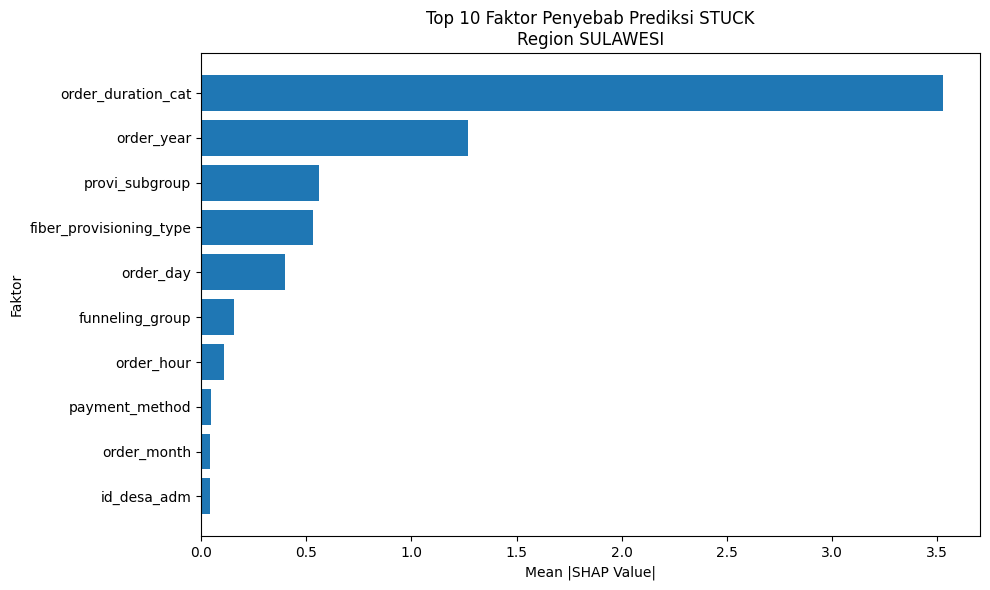

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/INTERPRETASI_REGIONAL/SULAWESI_TOP10_SHAP.png


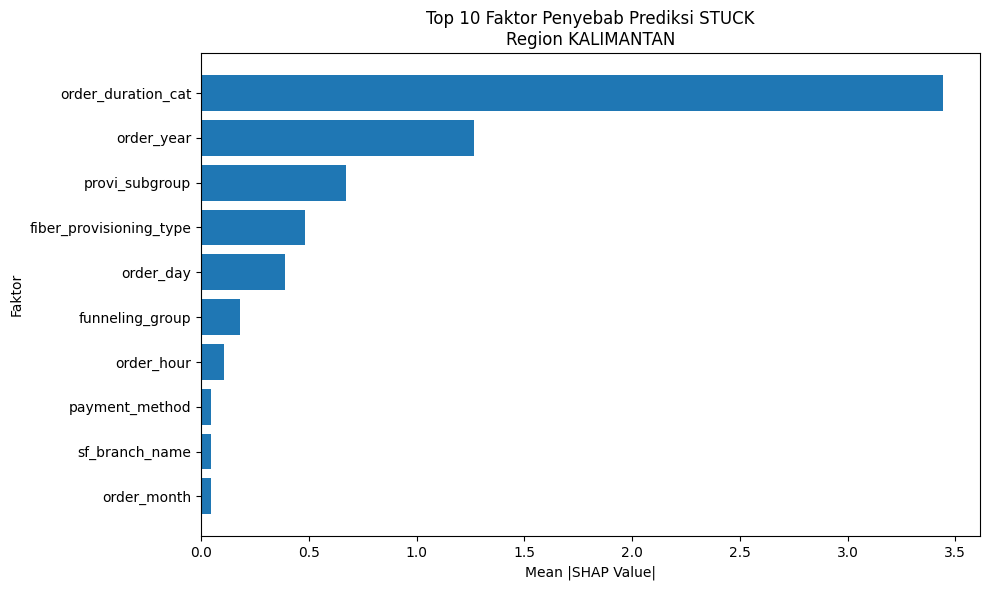

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/INTERPRETASI_REGIONAL/KALIMANTAN_TOP10_SHAP.png


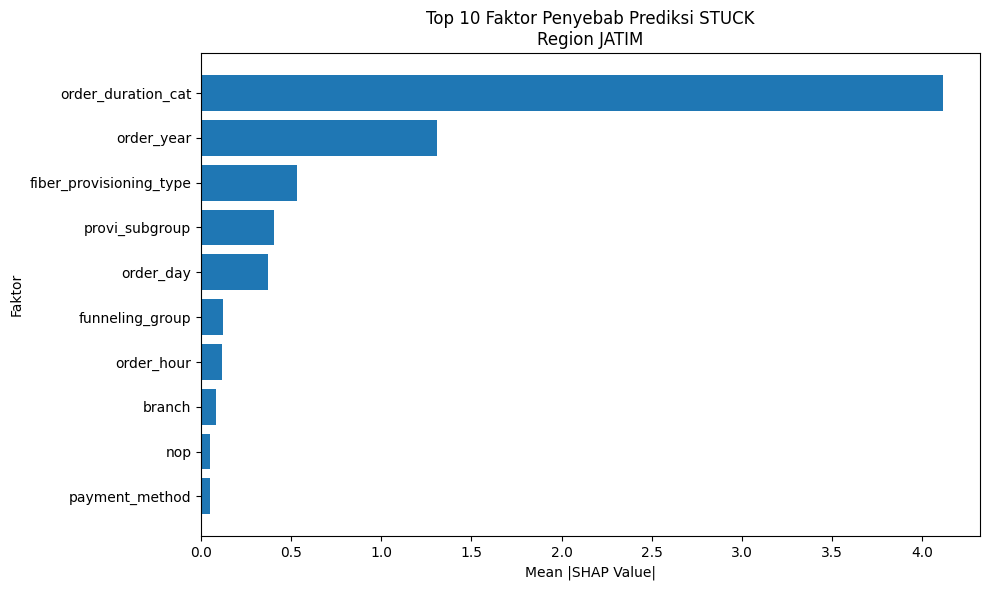

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/INTERPRETASI_REGIONAL/JATIM_TOP10_SHAP.png


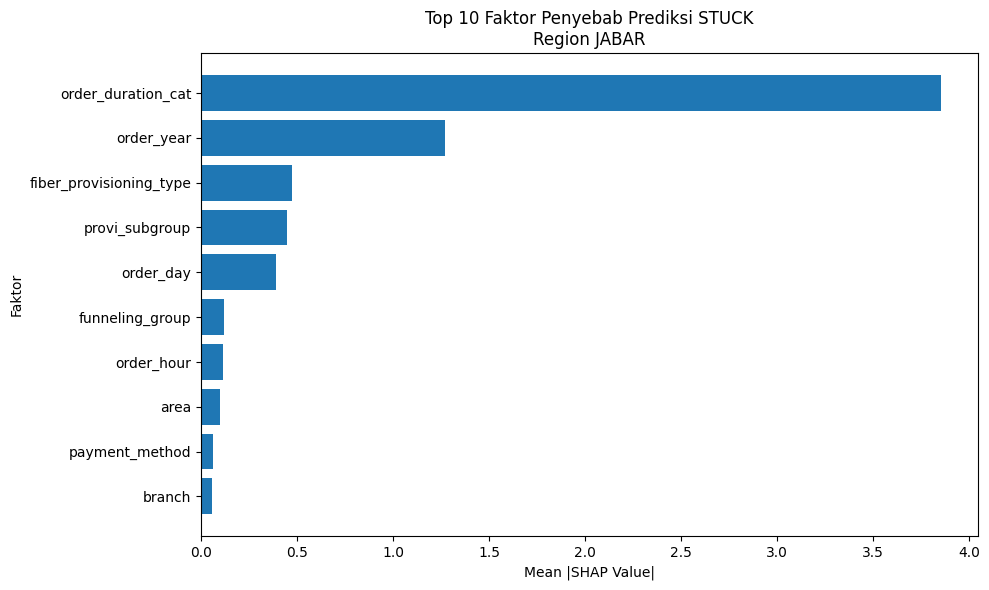

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/INTERPRETASI_REGIONAL/JABAR_TOP10_SHAP.png


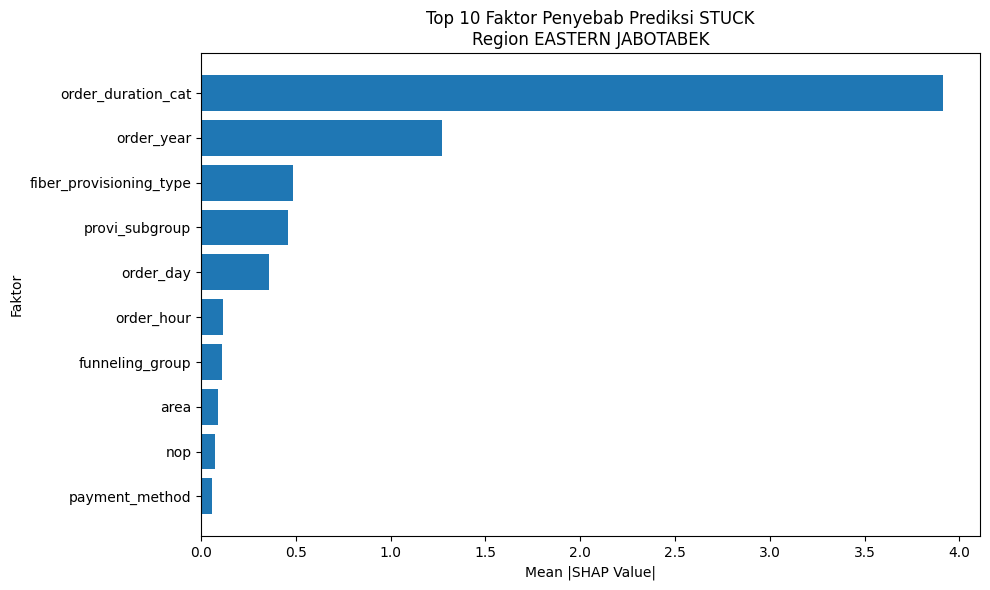

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/INTERPRETASI_REGIONAL/EASTERN_JABOTABEK_TOP10_SHAP.png

[3] MEMBUAT GRAFIK FAKTOR DOMINAN


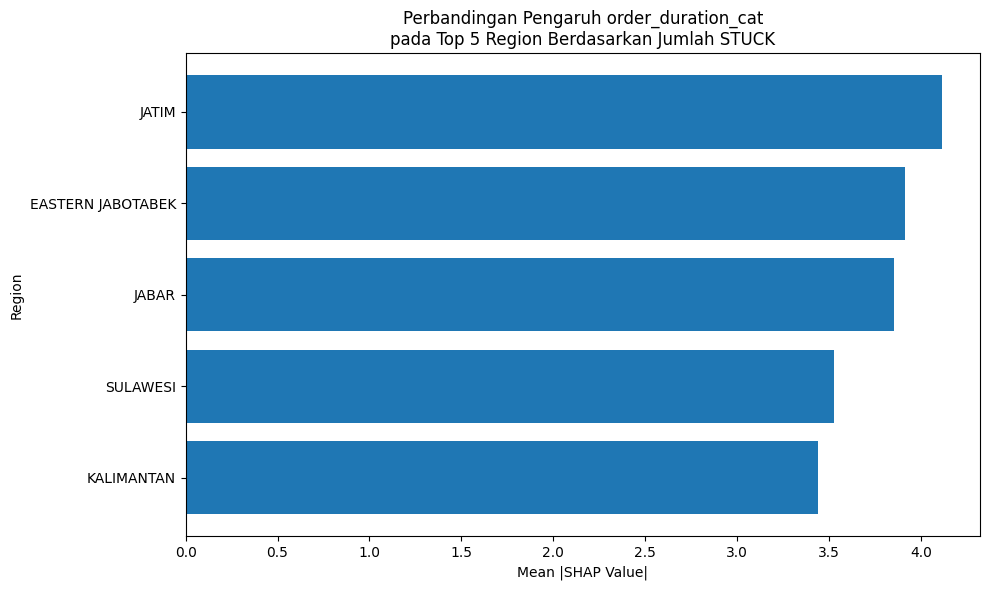

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/INTERPRETASI_REGIONAL/PERBANDINGAN_ORDER_DURATION_CAT.png

[4] MEMBUAT GRAFIK PERBANDINGAN 5 FAKTOR UTAMA


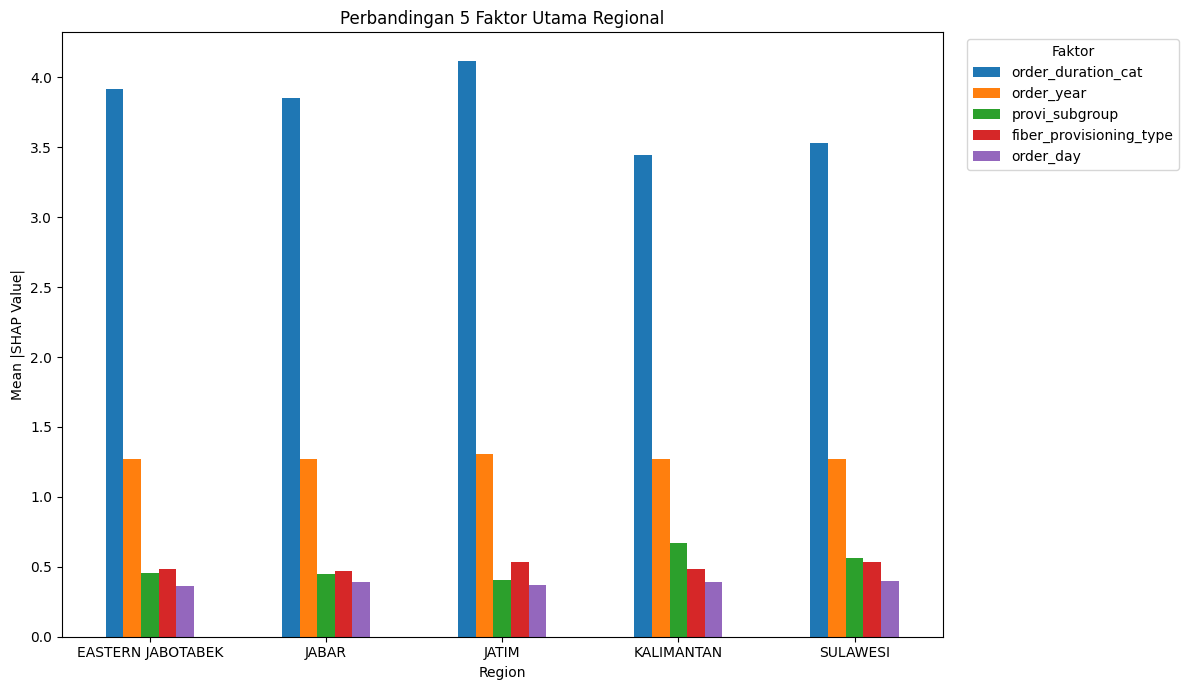

Saved: /content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP/INTERPRETASI_REGIONAL/PERBANDINGAN_5_FAKTOR_UTAMA.png

[5] RINGKASAN FAKTOR UTAMA
           region       faktor_utama  mean_abs_shap  mean_shap            arah
         SULAWESI order_duration_cat       3.527209   3.211819 Mendorong STUCK
       KALIMANTAN order_duration_cat       3.442668   3.093982 Mendorong STUCK
            JATIM order_duration_cat       4.115708   3.817768 Mendorong STUCK
            JABAR order_duration_cat       3.852847   3.677309 Mendorong STUCK
EASTERN JABOTABEK order_duration_cat       3.913522   3.760102 Mendorong STUCK

INTERPRETASI HASIL

INTERPRETASI HASIL ANALISIS REGIONAL TREE-SHAP

Pemilihan region dilakukan berdasarkan jumlah observasi berstatus STUCK. Lima region dengan jumlah STUCK tertinggi adalah SULAWESI, KALIMANTAN, JATIM, JABAR, dan EASTERN JABOTABEK.

Berdasarkan analisis Tree-SHAP pada seluruh observasi test set di masing-masing region, faktor yang paling dominan pada kelima reg

In [27]:
# ============================================================
# CELL 3 — VISUALISASI & INTERPRETASI REGIONAL TREE-SHAP
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PATH
# ------------------------------------------------------------

BASE_SHAP_DIR = "/content/drive/MyDrive/SKRIPSI/FMC_SHAP_MANUAL_TREESHAP"

REGION_RESULT_PATH = os.path.join(
    BASE_SHAP_DIR,
    "TOP_5_REGION_BY_STUCK_FINAL.csv"
)

# Folder output interpretasi
INTERPRETATION_DIR = os.path.join(
    BASE_SHAP_DIR,
    "INTERPRETASI_REGIONAL"
)

os.makedirs(INTERPRETATION_DIR, exist_ok=True)

print("=" * 70)
print("CELL 3 — VISUALISASI & INTERPRETASI REGIONAL TREE-SHAP")
print("=" * 70)


# ------------------------------------------------------------
# 2. LOAD DATA HASIL CELL 2
# ------------------------------------------------------------

print("\n[1] LOAD HASIL TOP 5 REGION")

region_df = pd.read_csv(REGION_RESULT_PATH)

print("Jumlah region :", len(region_df))
print(region_df.to_string(index=False))


# ------------------------------------------------------------
# 3. DATA TOP FACTOR ORIGINAL VARIABLE
# ------------------------------------------------------------
# Nilai berikut berasal dari hasil agregasi SHAP
# berdasarkan ORIGINAL VARIABLE pada Cell 2.
#
# mean_abs_shap = rata-rata absolut SHAP
# mean_shap     = rata-rata SHAP bertanda
#
# Interpretasi:
# mean_abs_shap -> seberapa besar kontribusi/pengaruh model
# mean_shap     -> arah kontribusi terhadap prediksi
#                 positif  = mendorong STUCK
#                 negatif  = mendorong NOT-STUCK

regional_shap = {

    "SULAWESI": [
        ["order_duration_cat", 3.527209, 3.211819],
        ["order_year", 1.271160, 0.921734],
        ["provi_subgroup", 0.559324, 0.396888],
        ["fiber_provisioning_type", 0.531436, 0.473436],
        ["order_day", 0.396911, 0.222831],
        ["funneling_group", 0.157389, 0.054522],
        ["order_hour", 0.108029, -0.003153],
        ["payment_method", 0.044809, 0.005792],
        ["order_month", 0.043644, 0.035999],
        ["id_desa_adm", 0.041742, 0.040390],
    ],

    "KALIMANTAN": [
        ["order_duration_cat", 3.442668, 3.093982],
        ["order_year", 1.268283, 0.888033],
        ["provi_subgroup", 0.671452, 0.499311],
        ["fiber_provisioning_type", 0.482197, 0.447629],
        ["order_day", 0.388403, 0.201365],
        ["funneling_group", 0.179237, 0.078055],
        ["order_hour", 0.106898, -0.007176],
        ["payment_method", 0.046321, 0.008014],
        ["sf_branch_name", 0.045110, 0.016781],
        ["order_month", 0.044824, 0.036231],
    ],

    "JATIM": [
        ["order_duration_cat", 4.115708, 3.817768],
        ["order_year", 1.308164, 1.070721],
        ["fiber_provisioning_type", 0.534461, 0.511484],
        ["provi_subgroup", 0.405462, 0.297286],
        ["order_day", 0.368769, 0.149955],
        ["funneling_group", 0.122960, 0.032872],
        ["order_hour", 0.113503, -0.006673],
        ["branch", 0.084892, 0.050822],
        ["nop", 0.050900, -0.006871],
        ["payment_method", 0.049037, 0.007200],
    ],

    "JABAR": [
        ["order_duration_cat", 3.852847, 3.677309],
        ["order_year", 1.272541, 1.061728],
        ["fiber_provisioning_type", 0.473088, 0.436442],
        ["provi_subgroup", 0.447594, 0.400172],
        ["order_day", 0.390273, 0.185258],
        ["funneling_group", 0.116439, 0.050965],
        ["order_hour", 0.113943, -0.005247],
        ["area", 0.096125, 0.096125],
        ["payment_method", 0.062574, 0.015260],
        ["branch", 0.058336, 0.013810],
    ],

    "EASTERN JABOTABEK": [
        ["order_duration_cat", 3.913522, 3.760102],
        ["order_year", 1.272756, 1.107726],
        ["fiber_provisioning_type", 0.486493, 0.457868],
        ["provi_subgroup", 0.457214, 0.376723],
        ["order_day", 0.360027, 0.201919],
        ["order_hour", 0.115036, -0.017925],
        ["funneling_group", 0.111588, 0.046495],
        ["area", 0.090943, 0.090935],
        ["nop", 0.074788, -0.017891],
        ["payment_method", 0.055960, 0.011879],
    ]
}


# ------------------------------------------------------------
# 4. CONVERT KE DATAFRAME
# ------------------------------------------------------------

rows = []

for region, values in regional_shap.items():

    for rank, row in enumerate(values, start=1):

        feature = row[0]
        mean_abs_shap = row[1]
        mean_shap = row[2]

        if mean_shap > 0:
            direction = "Mendorong STUCK"
        elif mean_shap < 0:
            direction = "Mendorong NOT-STUCK"
        else:
            direction = "Netral"

        rows.append({
            "region": region,
            "rank": rank,
            "feature": feature,
            "mean_abs_shap": mean_abs_shap,
            "mean_shap": mean_shap,
            "direction": direction
        })

regional_df = pd.DataFrame(rows)

regional_csv = os.path.join(
    INTERPRETATION_DIR,
    "REGIONAL_SHAP_INTERPRETATION_DATA.csv"
)

regional_df.to_csv(
    regional_csv,
    index=False
)


# ============================================================
# 5. GRAFIK 1
#    TOP 10 SHAP SETIAP REGION
# ============================================================

print("\n[2] MEMBUAT GRAFIK TOP 10 SHAP PER REGION")

for region in regional_shap:

    temp = regional_df[
        regional_df["region"] == region
    ].copy()

    temp = temp.sort_values(
        "mean_abs_shap",
        ascending=True
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        temp["feature"],
        temp["mean_abs_shap"]
    )

    plt.xlabel("Mean |SHAP Value|")
    plt.ylabel("Faktor")
    plt.title(
        f"Top 10 Faktor Penyebab Prediksi STUCK\n"
        f"Region {region}"
    )

    plt.tight_layout()

    filename = (
        region
        .replace(" ", "_")
        .replace("-", "_")
        + "_TOP10_SHAP.png"
    )

    save_path = os.path.join(
        INTERPRETATION_DIR,
        filename
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", save_path)


# ============================================================
# 6. GRAFIK 2
#    PERBANDINGAN ORDER_DURATION_CAT
# ============================================================

print("\n[3] MEMBUAT GRAFIK FAKTOR DOMINAN")

duration_df = regional_df[
    regional_df["feature"] == "order_duration_cat"
].copy()

# Urutkan berdasarkan SHAP
duration_df = duration_df.sort_values(
    "mean_abs_shap",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    duration_df["region"],
    duration_df["mean_abs_shap"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Region")
plt.title(
    "Perbandingan Pengaruh order_duration_cat\n"
    "pada Top 5 Region Berdasarkan Jumlah STUCK"
)

plt.tight_layout()

duration_plot = os.path.join(
    INTERPRETATION_DIR,
    "PERBANDINGAN_ORDER_DURATION_CAT.png"
)

plt.savefig(
    duration_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", duration_plot)


# ============================================================
# 7. GRAFIK 3
#    PERBANDINGAN 5 FAKTOR UTAMA ANTAR REGION
# ============================================================

print("\n[4] MEMBUAT GRAFIK PERBANDINGAN 5 FAKTOR UTAMA")

top5_features = [
    "order_duration_cat",
    "order_year",
    "provi_subgroup",
    "fiber_provisioning_type",
    "order_day"
]

comparison_df = regional_df[
    regional_df["feature"].isin(top5_features)
].copy()

pivot_df = comparison_df.pivot(
    index="region",
    columns="feature",
    values="mean_abs_shap"
)

# Pastikan urutan faktor
pivot_df = pivot_df[
    [
        "order_duration_cat",
        "order_year",
        "provi_subgroup",
        "fiber_provisioning_type",
        "order_day"
    ]
]

ax = pivot_df.plot(
    kind="bar",
    figsize=(12, 7)
)

ax.set_xlabel("Region")
ax.set_ylabel("Mean |SHAP Value|")
ax.set_title(
    "Perbandingan 5 Faktor Utama Regional"
)

plt.xticks(rotation=0)
plt.legend(
    title="Faktor",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

comparison_plot = os.path.join(
    INTERPRETATION_DIR,
    "PERBANDINGAN_5_FAKTOR_UTAMA.png"
)

plt.savefig(
    comparison_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", comparison_plot)


# ============================================================
# 8. TABEL RINGKASAN FAKTOR UTAMA
# ============================================================

print("\n[5] RINGKASAN FAKTOR UTAMA")

summary_rows = []

for region in regional_shap:

    temp = regional_df[
        regional_df["region"] == region
    ].sort_values(
        "mean_abs_shap",
        ascending=False
    )

    first = temp.iloc[0]

    summary_rows.append({
        "region": region,
        "faktor_utama": first["feature"],
        "mean_abs_shap": first["mean_abs_shap"],
        "mean_shap": first["mean_shap"],
        "arah": first["direction"]
    })

summary_df = pd.DataFrame(summary_rows)

print(
    summary_df.to_string(index=False)
)

summary_path = os.path.join(
    INTERPRETATION_DIR,
    "RINGKASAN_FAKTOR_UTAMA_REGION.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)


# ============================================================
# 9. INTERPRETASI OTOMATIS
# ============================================================

print("\n" + "=" * 70)
print("INTERPRETASI HASIL")
print("=" * 70)

interpretation_lines = []

interpretation_lines.append(
    "INTERPRETASI HASIL ANALISIS REGIONAL TREE-SHAP"
)
interpretation_lines.append("=" * 70)
interpretation_lines.append("")

interpretation_lines.append(
    "Pemilihan region dilakukan berdasarkan jumlah observasi "
    "berstatus STUCK. Lima region dengan jumlah STUCK tertinggi "
    "adalah SULAWESI, KALIMANTAN, JATIM, JABAR, dan "
    "EASTERN JABOTABEK."
)

interpretation_lines.append("")

interpretation_lines.append(
    "Berdasarkan analisis Tree-SHAP pada seluruh observasi "
    "test set di masing-masing region, faktor yang paling "
    "dominan pada kelima region adalah order_duration_cat."
)

interpretation_lines.append("")

# Detail setiap region
for region in regional_shap:

    temp = regional_df[
        regional_df["region"] == region
    ].sort_values(
        "mean_abs_shap",
        ascending=False
    )

    top = temp.iloc[0]

    interpretation_lines.append(
        f"Region {region}:"
    )

    interpretation_lines.append(
        f"- Faktor dengan kontribusi model terbesar adalah "
        f"{top['feature']} dengan mean |SHAP| sebesar "
        f"{top['mean_abs_shap']:.6f}."
    )

    if top["mean_shap"] > 0:

        interpretation_lines.append(
            f"- Nilai mean SHAP sebesar {top['mean_shap']:.6f} "
            f"menunjukkan bahwa faktor tersebut secara rata-rata "
            f"mendorong prediksi model ke kelas STUCK."
        )

    elif top["mean_shap"] < 0:

        interpretation_lines.append(
            f"- Nilai mean SHAP sebesar {top['mean_shap']:.6f} "
            f"menunjukkan bahwa faktor tersebut secara rata-rata "
            f"mendorong prediksi model ke kelas NOT-STUCK."
        )

    interpretation_lines.append(
        f"- Faktor berikutnya yang dominan adalah "
        f"{temp.iloc[1]['feature']} "
        f"(mean |SHAP| = {temp.iloc[1]['mean_abs_shap']:.6f}) "
        f"dan {temp.iloc[2]['feature']} "
        f"(mean |SHAP| = {temp.iloc[2]['mean_abs_shap']:.6f})."
    )

    interpretation_lines.append("")


# ============================================================
# 10. INTERPRETASI KOMPARATIF
# ============================================================

max_duration = duration_df.iloc[-1]
min_duration = duration_df.iloc[0]

interpretation_lines.append(
    "PERBANDINGAN ANTAR-REGION"
)

interpretation_lines.append(
    f"Nilai mean |SHAP| order_duration_cat tertinggi "
    f"terdapat pada {max_duration['region']} dengan nilai "
    f"{max_duration['mean_abs_shap']:.6f}."
)

interpretation_lines.append(
    f"Nilai mean |SHAP| order_duration_cat terendah di antara "
    f"Top 5 region terdapat pada {min_duration['region']} "
    f"dengan nilai {min_duration['mean_abs_shap']:.6f}."
)

interpretation_lines.append("")

interpretation_lines.append(
    "Secara umum, pola kontribusi faktor menunjukkan bahwa "
    "order_duration_cat memiliki jarak kontribusi yang cukup "
    "besar dibandingkan faktor-faktor lainnya. Setelah itu, "
    "order_year, provi_subgroup, fiber_provisioning_type, "
    "dan order_day merupakan faktor yang relatif lebih dominan."
)

interpretation_lines.append("")

interpretation_lines.append(
    "Temuan ini menunjukkan bahwa model XGBoost terutama "
    "menggunakan informasi yang berkaitan dengan durasi order, "
    "tahun order, karakteristik proses provisioning, jenis "
    "provisioning fiber, serta waktu order dalam membentuk "
    "prediksi STUCK pada lima region dengan jumlah STUCK tertinggi."
)

interpretation_lines.append("")

interpretation_lines.append(
    "Catatan interpretasi: nilai SHAP menjelaskan kontribusi "
    "fitur terhadap prediksi model dan tidak secara langsung "
    "menunjukkan hubungan sebab-akibat. Oleh karena itu, "
    "hasil ini digunakan untuk menjelaskan pola keputusan model, "
    "bukan sebagai bukti kausal bahwa suatu faktor secara langsung "
    "menyebabkan keterlambatan."
)

interpretation_lines.append("")

interpretation_lines.append(
    "Catatan metodologis: analisis regional menggunakan nilai "
    "Tree-SHAP yang telah dihitung sebelumnya dan tidak melakukan "
    "perhitungan ulang Tree-SHAP."
)


# ============================================================
# 11. SIMPAN TEKS INTERPRETASI
# ============================================================

interpretation_text = "\n".join(
    interpretation_lines
)

interpretation_path = os.path.join(
    INTERPRETATION_DIR,
    "INTERPRETASI_REGIONAL_TREE_SHAP.txt"
)

with open(
    interpretation_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(interpretation_text)


# ============================================================
# 12. PRINT HASIL AKHIR
# ============================================================

print("\n" + interpretation_text)

print("\n" + "=" * 70)
print("SEMUA OUTPUT SELESAI")
print("=" * 70)

print("\nFolder output:")
print(INTERPRETATION_DIR)

print("\nFile yang dibuat:")
print("1.", regional_csv)
print("2.", summary_path)
print("3.", interpretation_path)
print("4.", duration_plot)
print("5.", comparison_plot)

print("\nGrafik Top 10 per region juga telah disimpan.")